input teh data + libraries


In [ ]:
!pip install seaborn


In [ ]:
# Core scientific stack
import numpy as np
import pandas as pd

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# ML tools we will need later (classification + evaluation)
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

# (For classical models – we will use these in later steps)
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import HistGradientBoostingClassifier

# style settings for plots
sns.set(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)

# Reproducibility
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)


In [ ]:
# Path to your sample dataset (100 rows from the full 100k+ election dataset)
#DATA_PATH = "election_dataset_10000.csv"  # change if needed (e.g., "data/election_dataset_100.csv")

# Read CSV (low_memory=False helps with many mixed-type columns)
#df = pd.read_csv(DATA_PATH, low_memory=False)
#df = pd.read_csv(DATA_PATH, low_memory=False, encoding="latin1")
#df = pd.read_csv(DATA_PATH, low_memory=False, encoding="cp1252")

# Quick sanity checks
#print("Shape:", df.shape)
#print("\nColumn names:")
#print(df.columns.tolist()[:54])

# Peek at the first few rows
#df.head()


In [ ]:
import pandas as pd

DATA_PATH = "election_dataset_10000.csv"  # adjust if needed

# ============================================
# Try multiple encodings with Python engine
# and skip malformed lines
# ============================================
encodings_to_try = ["utf-8", "utf-8-sig", "cp1252", "latin1"]

df = None
used_encoding = None
last_error = None

for enc in encodings_to_try:
    try:
        print(f"Trying encoding = {enc} with engine='python' ...")
        df = pd.read_csv(
            DATA_PATH,
            encoding=enc,
            engine="python",       # Python parser (more tolerant)
            on_bad_lines="warn",   # or "skip" to silence logs completely
        )
        used_encoding = enc
        print(f"\nSuccess with encoding: {enc}")
        break
    except Exception as e:
        print(f"Failed with encoding {enc}: {e}")
        last_error = e

if df is None:
    print("\nAll explicit encodings failed. Please check the file manually (delimiter, corruption, etc.).")
else:
    print("\n================================")
    print("FINAL ENCODING USED:", used_encoding)
    print("Loaded shape:", df.shape)
    print("================================")

    print("\nColumn names (first 54):")
    print(df.columns.tolist()[:54])

    print("\nHead:")
    display(df.head())


Trying encoding = utf-8 with engine='python' ...
Failed with encoding utf-8: 'utf-8' codec can't decode byte 0xa0 in position 1813: invalid start byte
Trying encoding = utf-8-sig with engine='python' ...
Failed with encoding utf-8-sig: 'utf-8' codec can't decode byte 0xa0 in position 1813: invalid start byte
Trying encoding = cp1252 with engine='python' ...
Failed with encoding cp1252: 'charmap' codec can't decode byte 0x90 in position 3474: character maps to <undefined>
Trying encoding = latin1 with engine='python' ...


C:\Users\sorah\AppData\Local\Temp\ipykernel_78468\3208375239.py:18: ParserWarning: Skipping line 657: ',' expected after '"'

  df = pd.read_csv(
C:\Users\sorah\AppData\Local\Temp\ipykernel_78468\3208375239.py:18: ParserWarning: Skipping line 1323: ',' expected after '"'

  df = pd.read_csv(
C:\Users\sorah\AppData\Local\Temp\ipykernel_78468\3208375239.py:18: ParserWarning: Skipping line 1393: ',' expected after '"'

  df = pd.read_csv(
C:\Users\sorah\AppData\Local\Temp\ipykernel_78468\3208375239.py:18: ParserWarning: Skipping line 1405: ',' expected after '"'

  df = pd.read_csv(
C:\Users\sorah\AppData\Local\Temp\ipykernel_78468\3208375239.py:18: ParserWarning: Skipping line 1855: ',' expected after '"'

  df = pd.read_csv(
C:\Users\sorah\AppData\Local\Temp\ipykernel_78468\3208375239.py:18: ParserWarning: Skipping line 1857: ',' expected after '"'

  df = pd.read_csv(
C:\Users\sorah\AppData\Local\Temp\ipykernel_78468\3208375239.py:18: ParserWarning: Skipping line 2243: ',' expected aft


Success with encoding: latin1

FINAL ENCODING USED: latin1
Loaded shape: (100566, 54)

Column names (first 54):
['created_at', 'possibly_sensitive', 'author_id', 'text', 'clean_text', 'sentiment_vader_raw', 'sentiment_vader_label', 'edit_history_tweet_ids', 'id', 'public_metrics.retweet_count', 'public_metrics.reply_count', 'public_metrics.like_count', 'public_metrics.quote_count', 'public_metrics.bookmark_count', 'public_metrics.impression_count', 'entities.mentions', 'name', 'user_location', 'user_location_USA_state', 'username', 'verified', 'word_count', 'hashtags', 'Conspiracy_gpt4o_mini', 'Sensationalism_gpt4o_mini', 'Hate_Speech_gpt4o_mini', 'Speculation_gpt4o_mini', 'Satire_gpt4o_mini', 'Conspiracy_gpt4o', 'Sensationalism_gpt4o', 'Hate_Speech_gpt4o', 'Speculation_gpt4o', 'Satire_gpt4o', 'Conspiracy_gemini_2.0_flash', 'Sensationalism_gemini_2.0_flash', 'Hate_Speech_gemini_2.0_flash', 'Speculation_gemini_2.0_flash', 'Satire_gemini_2.0_flash', 'Conspiracy_gemini_2.5_pro', 'Sensati

,created_at,possibly_sensitive,author_id,text,clean_text,sentiment_vader_raw,sentiment_vader_label,edit_history_tweet_ids,id,public_metrics.retweet_count,...,Sensationalism_llama3.1_8B,Hate_Speech_llama3.1_8B,Speculation_llama3.1_8B,Satire_llama3.1_8B,Conspiracy_llama3.3,Sensationalism_llama3.3,Hate_Speech_llama3.3,Speculation_llama3.3,Satire_llama3.3,lang
0,2024-10-17 21:12:03+00:00,False,28390516,"With less than three weeks until election day,...",with less than three weeks until election day ...,0.0,neutral,['1847022787396845706'],1847022787396845706,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,en
1,2024-10-17 21:12:00+00:00,False,782905892505214976,"""...an outsider will not succeed in implementi...",an outsider will not succeed in implementing a...,0.2896,positive,['1847022775430766606'],1847022775430766606,0.0,...,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,en
2,2024-10-17 21:11:56+00:00,False,1820369823164993536,@mcuban [00:01:01]@mcuban I love helping comp...,000101 i love helping companies become succe...,0.874,positive,['1847022760385483154'],1847022760385483154,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,en
3,2024-10-17 21:11:56+00:00,False,1771293943587803137,@group1steve @FairiMairi @shananhalbert @Louis...,i want to be transparent i am a national m...,0.0772,positive,['1847022758972276993'],1847022758972276993,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,en
4,2024-10-17 21:11:50+00:00,False,3229279664,Read this published today by a newspaper that ...,read this published today by a newspaper that ...,0.0613,positive,['1847022733827162621'],1847022733827162621,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,en


Keep english text then sample n from 100K

In [ ]:
import pandas as pd

# df already loaded with 100k+ rows

# ============================================
# STEP 1 – Filter to English FIRST
# ============================================
if "lang" in df.columns:
    df = df[df["lang"] == "en"].copy()
    print("After lang=='en':", df.shape)
else:
    print("WARNING: 'lang' column not found; skipping language filter.")

# ============================================
# STEP 2 – RANDOM SAMPLE (e.g., 200 rows)
# ============================================
SAMPLE_SIZE = 95000
RANDOM_STATE = 42

print("English-only dataset size before sampling:", df.shape)

df_sample = df.sample(n=SAMPLE_SIZE, random_state=RANDOM_STATE).reset_index(drop=True)

print("Sampled subset size:", df_sample.shape)
display(df_sample.head())

# IMPORTANT: from here on, use df_sample as your main df
df = df_sample.copy()


After lang=='en': (95142, 54)
English-only dataset size before sampling: (95142, 54)
Sampled subset size: (95000, 54)


,created_at,possibly_sensitive,author_id,text,clean_text,sentiment_vader_raw,sentiment_vader_label,edit_history_tweet_ids,id,public_metrics.retweet_count,...,Sensationalism_llama3.1_8B,Hate_Speech_llama3.1_8B,Speculation_llama3.1_8B,Satire_llama3.1_8B,Conspiracy_llama3.3,Sensationalism_llama3.3,Hate_Speech_llama3.3,Speculation_llama3.3,Satire_llama3.3,lang
0,2025-04-21T16:21:24.000Z,False,1427632434980524035,"NPP 2024 PRESIDENTIAL CANDIDATE, DR. MAHAMUDU ...",npp 2024 presidential candidate dr mahamudu ba...,0.6369,positive,['1914353786249699504'],1914353786249699504,14.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,en
1,2025-06-01T11:45:12.000Z,False,73402979,Pastor Laurie believes Trumps election victor...,pastor laurie believes trumps election victory...,0.7269,positive,['1929142183560364518'],1929142183560364518,2.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,en
2,2025-04-05T11:42:06.000Z,False,902316616054177792,@MKDankwah @MrIrish3 An Open Demand for Answer...,an open demand for answers mussa dankwa and ...,-0.3182,negative,['1908485292727710106'],1908485292727710106,0.0,...,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,en
3,2024-11-06 07:01:47+00:00,False,1804361358307213312,BREAKING: Donald Trump is elected in the 2024 ...,breaking donald trump is elected in the 2024 u...,0.4215,positive,"['1854055920889696442', '1854056165790953928',...",1854056570692239795,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,en
4,2025-01-01 12:16:28+00:00,False,1252677094104010752,TEN MOST SIGNIFICANT LEGAL EVENTS OF 2024\n\nN...,ten most significant legal events of 2024\n\nn...,0.6335,positive,['1874429481361785297'],1874429481361785297,1.0,...,1.0,0.0,1.0,0.0,1.0,1.0,0.0,1.0,0.0,en


In [ ]:
# Keep English tweets only (using the 'lang' column)
if "lang" in df.columns:
    df = df[df["lang"] == "en"].copy()
    print("After lang=='en':", df.shape)
else:
    print("WARNING: 'lang' column not found; skipping language filter.")

After lang=='en': (95000, 54)


Define configuration lists and dictionaries

In [ ]:
# ---- Mention-related election keywords (substring match in @username) ----
MENTION_KEEP_KEYWORDS = [
    "trump", "biden", "kamala", "harris",
    "maga", "gop", "dem", "dems", "democrat", "democrats",
    "republican", "republicans",
    "election", "elections",
    "vote", "voting",
    "potus", "president", "whitehouse",
    "rnc", "dnc",
]

# ---- Short-tweet sensitive keywords ----
SHORT_TWEET_KEYWORDS = [
    "trump", "biden", "kamala", "harris",
    "maga", "gop", "dems", "democrat", "republican",
    "election", "vote", "voting",
    "potus", "rnc", "dnc",
]

MIN_TOKENS = 3  # tweets shorter than this are dropped unless they contain a sensitive keyword

# ---- Misspelling normalization ----
MISSPELLINGS_MAP = {
    # trump
    "trmp": "trump",
    "trunp": "trump",
    "trmpf": "trump",
    "drumpf": "trump",

    # biden
    "bidn": "biden",
    "bidan": "biden",
    "biben": "biden",
    "bidon": "biden",

    # kamala / harris
    "kamla": "kamala",
    "kamlaa": "kamala",
    "haris": "harris",

    # election
    "eletcion": "election",
    "electon": "election",
    "electoin": "election",
    "electiom": "election",

    # vote / voting
    "vtoe": "vote",
    "votw": "vote",
    "votin": "voting",
    "votng": "voting",
}

# ---- Emoji & emoticon mappings ----
EMOJI_TO_TOKEN = {
    # positive / happy
    "😀": "EMO_POS",
    "😃": "EMO_POS",
    "😄": "EMO_POS",
    "😁": "EMO_POS",
    "😊": "EMO_POS",
    "🙂": "EMO_POS",

    # love
    "😍": "EMO_LOVE",
    "❤️": "EMO_LOVE",
    "💕": "EMO_LOVE",

    # laugh
    "😂": "EMO_LAUGH",
    "🤣": "EMO_LAUGH",

    # sad
    "😢": "EMO_SAD",
    "😭": "EMO_SAD",

    # anger
    "😡": "EMO_ANGER",
    "😠": "EMO_ANGER",
    "🤬": "EMO_ANGER",

    # approve/disapprove
    "👍": "EMO_APPROVE",
    "👎": "EMO_DISAPPROVE",
}

# Emoticon regex patterns (string form, we’ll use re.sub)
EMOTICON_TO_TOKEN = {
    r":\)": "EMO_POS",
    r":-\)": "EMO_POS",
    r";\)": "EMO_WINK",
    r";-\)": "EMO_WINK",
    r":D": "EMO_LAUGH",
    r":-D": "EMO_LAUGH",
    r":\(": "EMO_SAD",
    r":-\(": "EMO_SAD",
    r":P": "EMO_TONGUE",
    r":-P": "EMO_TONGUE",
    r";P": "EMO_TONGUE",
    r";-P": "EMO_TONGUE",
}


Mapping teh emoji

In [ ]:
for emo, tok in EMOJI_TO_TOKEN.items():
    print(repr(emo), "→", tok)


'😀' → EMO_POS
'😃' → EMO_POS
'😄' → EMO_POS
'😁' → EMO_POS
'😊' → EMO_POS
'🙂' → EMO_POS
'😍' → EMO_LOVE
'❤️' → EMO_LOVE
'💕' → EMO_LOVE
'😂' → EMO_LAUGH
'🤣' → EMO_LAUGH
'😢' → EMO_SAD
'😭' → EMO_SAD
'😡' → EMO_ANGER
'😠' → EMO_ANGER
'🤬' → EMO_ANGER
'👍' → EMO_APPROVE
'👎' → EMO_DISAPPROVE


Helper functions for each cleaning step

In [ ]:
import re
import string



In [ ]:
URL_PATTERN = re.compile(r"https?://\S+|www\.\S+", re.IGNORECASE)
MENTION_PATTERN = re.compile(r"@(\w+)")
HASHTAG_PATTERN = re.compile(r"#(\w+)")


def remove_urls(text: str) -> str:
    return URL_PATTERN.sub(" ", text)


def handle_mentions(text: str) -> str:
    """
    Replace @mentions:
    - If username contains election keyword → keep normalized keyword
    - Else → remove
    """
    def _replace_mention(match):
        username = match.group(1).lower()
        for kw in MENTION_KEEP_KEYWORDS:
            if kw in username:
                return f" {kw} "
        return " "  # drop non-election mentions

    return MENTION_PATTERN.sub(_replace_mention, text)


def split_hashtag(tag: str) -> str:
    """
    Split hashtag into words:
    - handle underscores
    - quick camelCase split heuristic
    """
    # First split by underscores
    parts = re.split(r"[_]", tag)

    processed_parts = []
    for part in parts:
        # CamelCase split: `StopTheSteal` -> `Stop The Steal`
        part = re.sub(r"([a-z])([A-Z])", r"\1 \2", part)
        processed_parts.append(part)

    return " ".join(processed_parts)


def handle_hashtags(text: str) -> str:
    """
    Turn #hashtags into plain words, splitting into components.
    """

    def _replace_hashtag(match):
        tag = match.group(1)  # without '#'
        expanded = split_hashtag(tag)
        return " " + expanded + " "

    return HASHTAG_PATTERN.sub(_replace_hashtag, text)


def replace_emoticons(text: str) -> str:
    """
    Replace textual emoticons like :) :( :D with tokens.
    """
    for pattern, token in EMOTICON_TO_TOKEN.items():
        text = re.sub(pattern, f" {token} ", text)
    return text


def replace_emojis(text: str) -> str:
    """
    Replace emoji characters with tokens.
    """
    for emo, token in EMOJI_TO_TOKEN.items():
        text = text.replace(emo, f" {token} ")
    return text


def remove_punctuation(text: str) -> str:
    """
    Remove all punctuation characters.
    """
    # Include typical punctuation plus some unicode quotes, ellipsis
    extra_punct = "“”‘’…"
    all_punct = string.punctuation + extra_punct
    return re.sub(f"[{re.escape(all_punct)}]", " ", text)


def normalize_whitespace(text: str) -> str:
    return re.sub(r"\s+", " ", text).strip()


def normalize_misspellings(text: str) -> str:
    """
    Replace known misspellings using MISSPELLINGS_MAP (after lowercasing).
    """
    tokens = text.split()
    tokens = [MISSPELLINGS_MAP.get(tok, tok) for tok in tokens]
    return " ".join(tokens)


def lemmatize_text(text: str) -> str:
    """
    Lemmatize text using spaCy, keeping only alphabetic tokens and EMO_ tokens.
    """
    doc = nlp(text)
    lemmas = []
    for token in doc:
        # Keep our emoji tokens as-is
        if token.text.startswith("EMO_"):
            lemmas.append(token.text.lower())
            continue

        # Keep alphabetic words only (drop standalone numbers, etc.)
        if token.is_alpha:
            lemma = token.lemma_.lower()
            # spaCy sometimes returns '-PRON-' for pronouns; keep the surface form in that case
            if lemma == "-pron-":
                lemma = token.text.lower()
            lemmas.append(lemma)
    return " ".join(lemmas)


Apply the full cleaning pipeline

In [ ]:
!pip install spacy
!python -m spacy download en_core_web_sm


     ---------------------------------------- 0.0/12.8 MB ? eta -:--:--
     --- ------------------------------------ 1.0/12.8 MB 12.5 MB/s eta 0:00:01
     ----------------- ---------------------- 5.5/12.8 MB 18.7 MB/s eta 0:00:01
     ---------------------------------- ---- 11.3/12.8 MB 22.0 MB/s eta 0:00:01
     ---------------------------------------- 12.8/12.8 MB 21.1 MB/s  0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')


In [ ]:
import spacy
nlp = spacy.load("en_core_web_sm")


In [ ]:
TEXT_COL = "text"

if TEXT_COL not in df.columns:
    raise ValueError(f"Column '{TEXT_COL}' not found in dataframe!")

# Work on a copy of the raw text
raw = df[TEXT_COL].fillna("").astype(str)

def clean_one_tweet(t: str) -> str:
    # 0. Remove leading "RT " if present
    t = re.sub(r"^\s*RT\s+", " ", t)

    # 1. Remove URLs
    t = remove_urls(t)

    # 2. Handle mentions (keep only election-related ones)
    t = handle_mentions(t)

    # 3. Handle hashtags (#StopTheSteal -> "stop the steal")
    t = handle_hashtags(t)

    # 4. Replace emoticons ( :) :( :D etc.)
    t = replace_emoticons(t)

    # 5. Replace emoji characters with tokens
    t = replace_emojis(t)

    # 6. Lowercase
    t = t.lower()

    # 7. Remove punctuation
    t = remove_punctuation(t)

    # 8. Normalize whitespace
    t = normalize_whitespace(t)

    # 9. Normalize misspellings (trmp -> trump, etc.)
    t = normalize_misspellings(t)

    # 10. Lemmatize
    t = lemmatize_text(t)

    # 11. Final whitespace normalization
    t = normalize_whitespace(t)

    return t

df["clean_text_election"] = raw.apply(clean_one_tweet)

print("After cleaning, example rows:")
df[["text", "clean_text_election"]].head(10)


After cleaning, example rows:


,text,clean_text_election
0,"NPP 2024 PRESIDENTIAL CANDIDATE, DR. MAHAMUDU ...",npp presidential candidate dr mahamudu bawumia...
1,Pastor Laurie believes Trumps election victor...,pastor laurie believe election victory be part...
2,@MKDankwah @MrIrish3 An Open Demand for Answer...,an open demand for answer mussa dankwa and glo...
3,BREAKING: Donald Trump is elected in the 2024 ...,break donald trump be elect in the u s preside...
4,TEN MOST SIGNIFICANT LEGAL EVENTS OF 2024\n\nN...,ten most significant legal event of no the foi...
5,2024 election alt history\nPhil Scott vs Kamal...,election alt history phil scott vs kamala harris
6,Why the 2024 Election Was Annulled ? =Ñ \nWas ...,why the election be annul ñ be this a defense ...
7,@dittomoder you can be arrested for using the ...,you can be arrest for use the bathroom there
8,@realdogeusa And can you fix our broken voting...,and can you fix our break voting system electi...
9,?url=https%3A%2F%2Fcalifornia-times-brigCiting...,url https time brigcite public safety and bide...


Drop ultra-short tweets (with exception for sensitive keywords)

In [ ]:
def keep_tweet(row) -> bool:
    txt = row["clean_text_election"]
    tokens = txt.split()
    if len(tokens) >= MIN_TOKENS:
        return True

    # If too short, keep only if contains a sensitive keyword
    for kw in SHORT_TWEET_KEYWORDS:
        if kw in tokens:
            return True
    return False

before_filter = df.shape[0]
df = df[df.apply(keep_tweet, axis=1)].copy()
after_filter = df.shape[0]

print(f"Rows before short-tweet filter: {before_filter}")
print(f"Rows after short-tweet filter:  {after_filter}")


Rows before short-tweet filter: 95000
Rows after short-tweet filter:  94874


Remove duplicates for same user + same cleaned text

In [ ]:
before_dups = df.shape[0]
df = df.drop_duplicates(subset=["author_id", "clean_text_election"])
after_dups = df.shape[0]

print(f"Rows before duplicate removal: {before_dups}")
print(f"Rows after duplicate removal:  {after_dups}")


Rows before duplicate removal: 94874
Rows after duplicate removal:  88227


Inspect a few before/after examples

In [ ]:
sample = df[[TEXT_COL, "clean_text_election"]].sample(10, random_state=RANDOM_STATE)
for i, row in sample.iterrows():
    print("RAW :", row[TEXT_COL])
    print("CLEAN:", row["clean_text_election"])
    print("-" * 80)


RAW : After millions of voters felt their votes in General Election 2024 were wasted or ignored, join me in writing to your MP demanding that they attend &amp; support fairer votes in next week's crucial debate on changing the voting system.

https://t.co/nq6u784ury https://t.co/lNULlSgvZr
CLEAN: after million of voter feel their vote in general election be waste or ignore join i in write to your mp demand that they attend amp support fair vote in next week s crucial debate on change the voting system
--------------------------------------------------------------------------------
RAW : Just in case anyone forgot.

Trump wont the 2024 Election, and is the President of the United States.

Everyone should act like it. https://t.co/xQ7mZ3RzhK
CLEAN: just in case anyone forget trump will not the election and be the president of the united states everyone should act like it
--------------------------------------------------------------------------------
RAW : @Cdhd123 @JustinTrudeau Carbon 

Feature enginnering

location finging

Imports and state lookup

In [ ]:
import re
import string
import numpy as np
import pandas as pd

# If not already loaded:
# df = pd.read_csv("election_dataset_100.csv", low_memory=False)

print("Current shape:", df.shape)
print("Location columns present:", [c for c in df.columns if "location" in c.lower()])


Current shape: (88227, 55)
Location columns present: ['user_location', 'user_location_USA_state']


US state dictionaries:

In [ ]:
# 2-letter codes → full names
US_STATES = {
    "AL": "alabama",
    "AK": "alaska",
    "AZ": "arizona",
    "AR": "arkansas",
    "CA": "california",
    "CO": "colorado",
    "CT": "connecticut",
    "DE": "delaware",
    "FL": "florida",
    "GA": "georgia",
    "HI": "hawaii",
    "ID": "idaho",
    "IL": "illinois",
    "IN": "indiana",
    "IA": "iowa",
    "KS": "kansas",
    "KY": "kentucky",
    "LA": "louisiana",
    "ME": "maine",
    "MD": "maryland",
    "MA": "massachusetts",
    "MI": "michigan",
    "MN": "minnesota",
    "MS": "mississippi",
    "MO": "missouri",
    "MT": "montana",
    "NE": "nebraska",
    "NV": "nevada",
    "NH": "new hampshire",
    "NJ": "new jersey",
    "NM": "new mexico",
    "NY": "new york",
    "NC": "north carolina",
    "ND": "north dakota",
    "OH": "ohio",
    "OK": "oklahoma",
    "OR": "oregon",
    "PA": "pennsylvania",
    "RI": "rhode island",
    "SC": "south carolina",
    "SD": "south dakota",
    "TN": "tennessee",
    "TX": "texas",
    "UT": "utah",
    "VT": "vermont",
    "VA": "virginia",
    "WA": "washington",
    "WV": "west virginia",
    "WI": "wisconsin",
    "WY": "wyoming",
    "DC": "district of columbia"
}



STATE_CODES = set(US_STATES.keys())
STATE_NAMES = {v: k for k, v in US_STATES.items()}  # full name (lower) → code


Helper functions for location parsing

In [ ]:
def normalize_location(loc):
    """Convert to clean string."""
    if not isinstance(loc, str):
        return ""
    loc = loc.strip()
    return loc


def is_unreliable_location(loc):
    """
    Detect obviously bad / missing locations.
    We will DROP these rows completely.
    """

     # Treat pure "US" / "U.S." / "USA" as *reliable* (we'll classify later)
    if loc.strip().upper() in {"US", "U.S.", "USA","us", "usa", "u.s.a", "united states", "america", "u.s."}:
        return False

    if loc == "":
        return True

    # Contains URL
    if re.search(r"https?://|www\.", loc):
        return True

    # Count letters & digits
    alnum = re.findall(r"[A-Za-z0-9]", loc)
    if len(alnum) == 0:
        # only emojis / punctuation / spaces
        return True

    # Very short weird strings like "-" or "??"
    if len(loc) <= 2 and loc.upper() not in STATE_CODES:
        return True

    return False


def parse_state_from_location(loc_norm):
    """
    Try to extract a US state code from normalized location text.
    Returns 2-letter code or None.
    """
    text = loc_norm.lower()
    # remove punctuation
    text_clean = re.sub(f"[{re.escape(string.punctuation)}]", " ", text)
    text_clean = re.sub(r"\s+", " ", text_clean).strip()

    if not text_clean:
        return None

    tokens = text_clean.split()

    # 1) direct 2-letter code match
    for tok in tokens:
        if tok.upper() in STATE_CODES:
            return tok.upper()

    # 2) full name substring match
    for name, code in STATE_NAMES.items():
        if name in text_clean:   # e.g. "new york" inside "nyc, new york, usa"
            return code

    return None


def infer_location_features(loc_raw):
    """
    From raw user_location, return:
      user_state, is_US, has_US_state, location_unreliable
    """
    loc = normalize_location(loc_raw)

    # unreliable → will be dropped later
    if is_unreliable_location(loc):
        return pd.Series({
            "user_state": "Unknown",
            "is_US": 0,
            "has_US_state": 0,
            "location_unreliable": 1
        })

    # Try to parse state
    state_code = parse_state_from_location(loc)

    if state_code is not None:
        # specific US state known
        return pd.Series({
            "user_state": state_code,   # e.g. "CA"
            "is_US": 1,
            "has_US_state": 1,
            "location_unreliable": 0
        })

    # No specific state, check for generic US marker
    text_lower = loc.lower()
    if any(k in text_lower for k in ["us", "usa", "u.s.a", "united states", "america", "u.s."]):

        return pd.Series({
            "user_state": "US",   # US but no state
            "is_US": 1,
            "has_US_state": 0,
            "location_unreliable": 0
        })

    # Looks like non-US but still meaningful
    return pd.Series({
        "user_state": "Non_US",
        "is_US": 0,
        "has_US_state": 0,
        "location_unreliable": 0
    })


Apply to your dataset (using user_location)

In [ ]:
# If your main column is named differently, change here:
LOCATION_COL = "user_location"

if LOCATION_COL not in df.columns:
    raise ValueError(f"Column '{LOCATION_COL}' not found in dataframe.")

loc_features = df[LOCATION_COL].apply(infer_location_features)
df = pd.concat([df, loc_features], axis=1)

print("After adding location features:")
print(df[["user_location", "user_state", "is_US", "has_US_state", "location_unreliable"]].head(10))


After adding location features:
       user_location user_state  is_US  has_US_state  location_unreliable
0       Accra, Ghana     Non_US      0             0                    0
1    Oxford, England     Non_US      0             0                    0
2       Accra, Ghana     Non_US      0             0                    0
3          Worldwide     Non_US      0             0                    0
4                NaN    Unknown      0             0                    1
5  New York City, NY         NY      1             1                    0
6            Romania     Non_US      0             0                    0
7    Berlin, Germany     Non_US      0             0                    0
8                NaN    Unknown      0             0                    1
9                NaN    Unknown      0             0                    1


Drop unreliable locations (your request)

In [ ]:
before = df.shape[0]
df = df[df["location_unreliable"] == 0].copy()
after = df.shape[0]

print(f"Rows before dropping unreliable locations: {before}")
print(f"Rows after dropping unreliable locations:  {after}")


Rows before dropping unreliable locations: 88227
Rows after dropping unreliable locations:  56594


Binary flags (is_US, has_US_state) are already created

In [ ]:
df[["user_state", "is_US", "has_US_state"]].sample(10, random_state=42)


,user_state,is_US,has_US_state
76231,Non_US,0,0
41014,Non_US,0,0
54349,US,1,0
93367,Non_US,0,0
20861,Non_US,0,0
9791,US,1,0
55973,OH,1,1
58716,Non_US,0,0
72308,CA,1,1
52904,Non_US,0,0


Separate each state (one-hot encoding)

In [ ]:
# One-hot encode user_state (this also creates columns for 'US_unknown' and 'Non_US')
state_dummies = pd.get_dummies(df["user_state"], prefix="state")

print("State dummy columns:", state_dummies.columns.tolist())

# Attach to main dataframe
df = pd.concat([df, state_dummies], axis=1)

print("Final shape after adding state dummies:", df.shape)


State dummy columns: ['state_AK', 'state_AL', 'state_AR', 'state_AZ', 'state_CA', 'state_CO', 'state_CT', 'state_DC', 'state_DE', 'state_FL', 'state_GA', 'state_HI', 'state_IA', 'state_ID', 'state_IL', 'state_IN', 'state_KS', 'state_KY', 'state_LA', 'state_MA', 'state_MD', 'state_ME', 'state_MI', 'state_MN', 'state_MO', 'state_MS', 'state_MT', 'state_NC', 'state_ND', 'state_NE', 'state_NH', 'state_NJ', 'state_NM', 'state_NV', 'state_NY', 'state_Non_US', 'state_OH', 'state_OK', 'state_OR', 'state_PA', 'state_RI', 'state_SC', 'state_SD', 'state_TN', 'state_TX', 'state_US', 'state_UT', 'state_VA', 'state_VT', 'state_WA', 'state_WI', 'state_WV', 'state_WY']


Final shape after adding state dummies: (56594, 112)


Sentiment Feature

In [ ]:
!pip install vaderSentiment


In [ ]:
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

analyzer = SentimentIntensityAnalyzer()


In [ ]:
# !pip install vaderSentiment

from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

analyzer = SentimentIntensityAnalyzer()

def compute_sentiment(text):
    """
    Run VADER on cleaned tweet text.
    Returns compound score and label (neg/neu/pos).
    """
    if not isinstance(text, str) or text.strip() == "":
        return pd.Series({"sentiment_score": 0.0, "sentiment_label": "neutral"})

    scores = analyzer.polarity_scores(text)
    compound = scores["compound"]

    if compound <= -0.05:
        label = "negative"
    elif compound >= 0.05:
        label = "positive"
    else:
        label = "neutral"

    return pd.Series({"sentiment_score": compound, "sentiment_label": label})

sentiment_features = df["clean_text_election"].apply(compute_sentiment)
df = pd.concat([df, sentiment_features], axis=1)

df[["clean_text_election", "sentiment_score", "sentiment_label"]].head()


,clean_text_election,sentiment_score,sentiment_label
0,npp presidential candidate dr mahamudu bawumia...,0.6369,positive
1,pastor laurie believe election victory be part...,0.7269,positive
2,an open demand for answer mussa dankwa and glo...,-0.3818,negative
3,break donald trump be elect in the u s preside...,0.4215,positive
5,election alt history phil scott vs kamala harris,0.0000,neutral


Hate Speech Feature (rule-based baseline)

In [ ]:
# Very simple baseline list
HATE_KEYWORDS = [
    # general slurs
    "idiot", "moron", "stupid", "dumb",
    "racist", "bigot", "nazi", "fascist",
    "scum", "trash", "loser",
    # political insult patterns
    "libtard", "trumptard", "snowflake",
    "fake patriot"
]

def compute_hate_features(text):
    """
    Count how many hate-keywords appear in the tweet.
    """
    if not isinstance(text, str):
        return pd.Series({"hate_count": 0, "hate_flag": 0})

    tokens = text.split()
    tokens_set = set(tokens)

    count = sum(1 for w in HATE_KEYWORDS if w in tokens_set)
    flag = int(count > 0)

    return pd.Series({"hate_count": count, "hate_flag": flag})

hate_features = df["clean_text_election"].apply(compute_hate_features)
df = pd.concat([df, hate_features], axis=1)

df[["clean_text_election", "hate_count", "hate_flag"]].head()


,clean_text_election,hate_count,hate_flag
0,npp presidential candidate dr mahamudu bawumia...,0,0
1,pastor laurie believe election victory be part...,0,0
2,an open demand for answer mussa dankwa and glo...,0,0
3,break donald trump be elect in the u s preside...,0,0
5,election alt history phil scott vs kamala harris,0,0


Misinformation Feature (rule-based seeds)

In [ ]:
MISINFO_PATTERNS = [
    r"rigged election",
    r"stolen election",
    r"election.*fraud",
    r"voter fraud",
    r"fake ballot",
    r"fake ballots",
    r"ballot dumping",
    r"dead people voting",
    r"stop the steal",
    r"fraudulent vote",
    r"fraudulent ballot",
    r"illegal vote",
    r"election.*fixed",
]

compiled_misinfo = [re.compile(pat) for pat in MISINFO_PATTERNS]

def compute_misinfo_features(text):
    if not isinstance(text, str):
        return pd.Series({"misinfo_count": 0, "misinfo_flag": 0})

    count = 0
    for pattern in compiled_misinfo:
        if pattern.search(text):
            count += 1
    flag = int(count > 0)
    return pd.Series({"misinfo_count": count, "misinfo_flag": flag})

misinfo_features = df["clean_text_election"].apply(compute_misinfo_features)
df = pd.concat([df, misinfo_features], axis=1)

df[["clean_text_election", "misinfo_count", "misinfo_flag"]].head()


,clean_text_election,misinfo_count,misinfo_flag
0,npp presidential candidate dr mahamudu bawumia...,0,0
1,pastor laurie believe election victory be part...,0,0
2,an open demand for answer mussa dankwa and glo...,0,0
3,break donald trump be elect in the u s preside...,0,0
5,election alt history phil scott vs kamala harris,0,0


Time Frequency Features

In [ ]:
# ===============================
# Time parsing + basic features
# ===============================
TIME_COL = "created_at"

# 1) Normalize different variants
# Convert to string, strip spaces, handle Z-UTC and mixed 'T' vs ' ' separators
df[TIME_COL] = (
    df[TIME_COL]
    .astype(str)
    .str.strip()
    .str.replace("Z", "+00:00", regex=False)      # Z → +00:00
    .str.replace("T", " ", regex=False)           # T → space
)

# 2) Try parsing with multiple known formats
def parse_mixed_datetime(x):
    for fmt in ("%Y-%m-%d %H:%M:%S%z", "%Y-%m-%d %H:%M:%S.%f%z"):
        try:
            return pd.to_datetime(x, format=fmt, utc=True)
        except Exception:
            continue
    return pd.NaT

df[TIME_COL] = df[TIME_COL].apply(parse_mixed_datetime)

# 3) Check if any remain unparseable
print("Unparseable created_at rows:", df[TIME_COL].isna().sum())

# 4) Derive time features
df["tweet_date"] = df[TIME_COL].dt.date
df["tweet_hour"] = df[TIME_COL].dt.hour
df["tweet_dayofweek"] = df[TIME_COL].dt.dayofweek  # 0=Mon ... 6=Sun

# 5) Quick preview
df[[TIME_COL, "tweet_date", "tweet_hour", "tweet_dayofweek"]].head()


Unparseable created_at rows: 2


,created_at,tweet_date,tweet_hour,tweet_dayofweek
0,2025-04-21 16:21:24+00:00,2025-04-21,16.0,0.0
1,2025-06-01 11:45:12+00:00,2025-06-01,11.0,6.0
2,2025-04-05 11:42:06+00:00,2025-04-05,11.0,5.0
3,2024-11-06 07:01:47+00:00,2024-11-06,7.0,2.0
5,2025-05-16 08:41:59+00:00,2025-05-16,8.0,4.0


In [ ]:
daily_counts = df.groupby("tweet_date").size().rename("tweet_count")
daily_counts.head()


tweet_date
2024-10-17    403
2024-10-18    455
2024-10-19    461
2024-10-20    446
2024-10-21    464
Name: tweet_count, dtype: int64

Engagement Rate Feature

In [ ]:
import numpy as np
import pandas as pd

# Match your real column names
LIKE_COL      = "public_metrics.like_count"
RT_COL        = "public_metrics.retweet_count"
REPLY_COL     = "public_metrics.reply_count"
QUOTE_COL     = "public_metrics.quote_count"
BOOKMARK_COL  = "public_metrics.bookmark_count"
IMPR_COL      = "public_metrics.impression_count"

metric_cols = [LIKE_COL, RT_COL, REPLY_COL, QUOTE_COL, BOOKMARK_COL, IMPR_COL]

# 0) Make sure all these columns exist
for col in metric_cols:
    if col not in df.columns:
        raise ValueError(f"Column '{col}' not found in dataframe. Check spelling.")

# 1) Force all metric columns to numeric (in case they are strings)
for col in metric_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# 2) Replace NaNs with 0 for safety
df[metric_cols] = df[metric_cols].fillna(0)

# 3) Raw engagement = sum of interactions
df["engagement_raw"] = (
    df[LIKE_COL]
    + df[RT_COL]
    + df[REPLY_COL]
    + df[QUOTE_COL]
    + df[BOOKMARK_COL]
)

# 4) Engagement rate = engagement per impression (avoid /0)
df["engagement_rate"] = df["engagement_raw"] / (df[IMPR_COL] + 1)

# 5) Log-transformed engagement rate (to reduce skew)
df["engagement_rate_log"] = np.log1p(df["engagement_rate"])

# Quick check
display(
    df[
        [
            LIKE_COL, RT_COL, REPLY_COL, QUOTE_COL, BOOKMARK_COL, IMPR_COL,
            "engagement_raw", "engagement_rate", "engagement_rate_log"
        ]
    ].head()
)


,public_metrics.like_count,public_metrics.retweet_count,public_metrics.reply_count,public_metrics.quote_count,public_metrics.bookmark_count,public_metrics.impression_count,engagement_raw,engagement_rate,engagement_rate_log
0,70,14.0,1.0,0,0,1235,85.0,0.068770,0.066509
1,18,2.0,0.0,0,1,4779,21.0,0.004393,0.004384
2,0,0.0,0.0,0,0,6,0.0,0.000000,0.000000
3,0,0.0,0.0,0,0,0,0.0,0.000000,0.000000
5,1,0.0,0.0,0,0,37,1.0,0.026316,0.025975


Sensitivity Flags Feature

In [ ]:
SENS_COL = "possibly_sensitive"

if SENS_COL in df.columns:
    # Normalize to lowercase strings
    sens_str = df[SENS_COL].astype(str).str.strip().str.lower()

    df["sensitive_flag"] = sens_str.map({
        "true": 1,
        "false": 0
    })

    # Anything unexpected (NaN, other strings) → 0 by default
    df["sensitive_flag"] = df["sensitive_flag"].fillna(0).astype(int)
else:
    df["sensitive_flag"] = 0

df[[SENS_COL, "sensitive_flag"]].head()


,possibly_sensitive,sensitive_flag
0,False,0
1,False,0
2,False,0
3,False,0
5,False,0


Candidate Fans Feature

In [ ]:
# ===============================================================
# Keyword + Stance Heuristic for Candidate Fan Detection
# ===============================================================

import pandas as pd

# -----------------------------
# 1. Candidate keyword blocks
# -----------------------------

TRUMP_KEYWORDS = [
    # core identity
    "trump", "donald", "donald trump",
    # party / movement
    "maga", "republican", "republicans", "gop", "conservative",
    # slogans / frames
    "make america great again", "keep america great",
    "america first", "american patriot", "true american patriot",
    "trumptrain", "trump train", "trump supporters", "trumpsupporters",
    # election framing
    "stop the steal", "election fraud", "election integrity",
    "rigged election", "rigged", "rig", "steal", "stolen election",
    "trump2024", "trump 2024",
]

BIDEN_KEYWORDS = [
    "biden", "joe biden", "joe",
    "president biden",
    "democrat", "democrats", "democratic party"
]

KAMALA_KEYWORDS = [
    "kamala", "harris", "kamala harris",
    "vice president harris", "vp harris",
    "harris campaign"
]

BIDEN_KAMALA_KEYWORDS = [
    "biden harris", "biden-harris",
    "vote blue", "blue wave",
    "democracy", "protect our democracy",
]

# -----------------------------
# 2. Stance patterns
# -----------------------------

# PRO / ANTI TRUMP
PRO_TRUMP_PATTERNS = [
    "trump wins", "trump win",
    "trump2024", "trump 2024",
    "true american patriot",
    "patriot voting for trump",
    "2big2rig",
    "stop the steal",
    "election fraud",
    "lawless lawfare",
]

ANTI_TRUMP_PATTERNS = [
    "orange man", "orange cult", "orange clown",
    "drumpf",
    "insurrectionist", "insurrectionists",
    "big lie",
    "trump didnt win", "trump did not win",
    "trump lost", "trump actually lost",
]

# PRO / ANTI BIDEN–KAMALA
PRO_BIDEN_PATTERNS = [
    "vote blue",
    "biden harris 2024",
    "biden-harris 2024",
    "democracy wins",
    "protect our democracy",
]

ANTI_BIDEN_PATTERNS = [
    "biden crime family",
    "biden inflation",
    "high gas prices under biden",
    "anti biden", "anti-biden",
    "anti democrat", "anti-democrat",
    "kamala got as many votes as we were told",  # in sarcastic / doubting context
]

# -----------------------------
# 3. Helper: normalize text
# -----------------------------

def norm_text(text):
    if not isinstance(text, str):
        return ""
    return text.lower()

# -----------------------------
# 4. Base candidate detection
# -----------------------------

def detect_candidate_base(text: str) -> str:
    t = norm_text(text)

    # Trump first – strongly distinctive
    if any(k in t for k in TRUMP_KEYWORDS):
        return "Trump"

    # Explicit Biden
    if any(k in t for k in BIDEN_KEYWORDS):
        return "Biden"

    # Explicit Kamala
    if any(k in t for k in KAMALA_KEYWORDS):
        return "Kamala"

    # Shared Biden–Kamala / Dem framing
    if any(k in t for k in BIDEN_KAMALA_KEYWORDS):
        return "Biden_Kamala"

    return "Neutral"

# -----------------------------
# 5. Stance detection
# -----------------------------

def detect_stance(text: str) -> str:
    t = norm_text(text)

    # TRUMP stance
    if any(p in t for p in PRO_TRUMP_PATTERNS):
        return "pro_trump"
    if any(p in t for p in ANTI_TRUMP_PATTERNS):
        return "anti_trump"

    # BIDEN–KAMALA stance
    if any(p in t for p in PRO_BIDEN_PATTERNS):
        return "pro_biden"
    if any(p in t for p in ANTI_BIDEN_PATTERNS):
        return "anti_biden"

    return "neutral"

# -----------------------------
# 6. Final candidate fan resolution
# -----------------------------

def resolve_candidate_fan(text: str) -> str:
    base = detect_candidate_base(text)
    stance = detect_stance(text)

    # 1) Use stance when it is clear
    if stance == "pro_trump":
        return "Trump"
    if stance == "anti_trump":
        # anti-Trump → favor Biden/Kamala side
        return "Biden_Kamala"
    if stance == "pro_biden":
        return "Biden_Kamala"
    if stance == "anti_biden":
        # anti-Biden → favor Trump side
        return "Trump"

    # 2) No clear stance → fall back to base candidate
    if base in ["Biden", "Kamala", "Biden_Kamala"]:
        return "Biden_Kamala"
    if base == "Trump":
        return "Trump"

    # 3) No signal at all
    return "Neutral"

# -----------------------------
# 7. Apply to your dataframe
# -----------------------------

df["candidate_fan"] = df["clean_text_election"].apply(resolve_candidate_fan)

# quick sanity check
df["candidate_fan"].value_counts(normalize=True).round(3)
df[["clean_text_election", "candidate_fan"]].head()



,clean_text_election,candidate_fan
0,npp presidential candidate dr mahamudu bawumia...,Neutral
1,pastor laurie believe election victory be part...,Neutral
2,an open demand for answer mussa dankwa and glo...,Neutral
3,break donald trump be elect in the u s preside...,Trump
5,election alt history phil scott vs kamala harris,Biden_Kamala


Log-Odds for keywords candidate fans

In [ ]:
# ===============================================================
# Step 1 – Tokenization for log-odds
# ===============================================================

import re
from collections import Counter
import numpy as np

def tokenize_for_keywords(text):
    if not isinstance(text, str):
        return []
    text = text.lower()
    text = re.sub(r"http\S+|www\S+", "", text)
    text = re.sub(r"[^a-z\s]", " ", text)
    tokens = [w for w in text.split() if len(w) > 2]
    return tokens

df["tokens"] = df["clean_text_election"].apply(tokenize_for_keywords)

# ===============================================================
# Step 2 – Word counts per candidate_fan label
# ===============================================================

def counts_for_label(label):
    subset = df[df["candidate_fan"] == label]["tokens"]
    c = Counter()
    for toks in subset:
        c.update(toks)
    return c

counts_trump   = counts_for_label("Trump")
counts_biden_k = counts_for_label("Biden_Kamala")
counts_neutral = counts_for_label("Neutral")  # may be useful later

print("Trump tweets:",  sum(counts_trump.values()))
print("Biden_Kamala tweets:", sum(counts_biden_k.values()))

# ===============================================================
# Step 3 – Log-odds scoring function
# ===============================================================

def log_odds(c1: Counter, c2: Counter, min_total_count: int = 15):
    """
    Return list of (word, score) where score = log( (c1[w]+1) / (c2[w]+1) ).
    Positive → skewed to c1; negative → skewed to c2.
    min_total_count is (c1[w] + c2[w]) threshold to ignore ultra-rare words.
    """
    vocab = set(c1.keys()) | set(c2.keys())
    scores = []
    for w in vocab:
        a = c1[w] + 1
        b = c2[w] + 1
        if a + b < min_total_count:
            continue
        scores.append((w, np.log(a / b)))
    scores.sort(key=lambda x: x[1], reverse=True)
    return scores

trump_vs_biden = log_odds(counts_trump, counts_biden_k, min_total_count=15)

# ===============================================================
# Step 4 – Inspect top skewed words
# ===============================================================

TOP_N = 40

print("\n=== Top Trump-skewed words (c1 = Trump) ===")
for w, s in trump_vs_biden[:TOP_N]:
    print(f"{w:20s} {s:6.2f}")

print("\n=== Top Biden/Kamala-skewed words (c2 = Biden_Kamala) ===")
for w, s in trump_vs_biden[-TOP_N:]:
    print(f"{w:20s} {s:6.2f}")


# ===============================================================
# Step 5 – Define current keyword inventories (lowercased single tokens)
# ===============================================================

existing_trump_tokens = set()
for k in TRUMP_KEYWORDS:
    for tok in k.lower().split():
        existing_trump_tokens.add(tok)

existing_biden_tokens = set()
for k in BIDEN_KEYWORDS + KAMALA_KEYWORDS + BIDEN_KAMALA_KEYWORDS:
    for tok in k.lower().split():
        existing_biden_tokens.add(tok)

# Optional: add a manual stopword list to avoid junk
MANUAL_STOP = {
    "the", "and", "this", "that", "with", "from", "will", "they",
    "about", "have", "just", "more", "like", "you", "your",
    "people", "time", "today", "one", "two", "three",
    "said", "says", "news", "post", "video", "live",
}

# ===============================================================
# Step 6 – Suggested new Trump keywords
# ===============================================================

def suggest_new_keywords(skew_list, existing_tokens, side="Trump", top_k=50):
    suggestions = []
    for w, score in skew_list:
        if w in existing_tokens:
            continue
        if w in MANUAL_STOP:
            continue
        # filter numeric-like junk
        if w.isdigit():
            continue
        suggestions.append((w, score))
        if len(suggestions) >= top_k:
            break
    print(f"\n=== Suggested new {side} tokens (log-odds based) ===")
    for w, s in suggestions:
        print(f"{w:20s} {s:6.2f}")
    return suggestions

# Trump-skewed (top of list)
suggested_trump_tokens = suggest_new_keywords(
    trump_vs_biden,
    existing_trump_tokens,
    side="Trump",
    top_k=30
)

# Biden/Kamala-skewed (bottom of list, reverse order)
suggested_biden_tokens = suggest_new_keywords(
    list(reversed(trump_vs_biden)),
    existing_biden_tokens,
    side="Biden_Kamala",
    top_k=30
)


Trump tweets: 527420
Biden_Kamala tweets: 127936

=== Top Trump-skewed words (c1 = Trump) ===
conservative           6.49
donald                 6.41
right                  6.22
republicans            5.71
republican             5.60
trump                  5.45
rigging                5.35
rig                    5.08
maga                   4.99
steal                  4.71
counsel                4.67
original               4.49
bright                 4.48
btc                    4.34
trigger                4.25
rnc                    4.08
gop                    4.04
hush                   4.03
kari                   3.99
routh                  3.95
prosecution            3.91
computer               3.89
magazine               3.85
stormy                 3.83
rigged                 3.78
furious                3.78
bitcoin                3.74
pen                    3.71
outright               3.71
fulfill                3.64
colombian              3.61
pam                    3.61
mcdonald  

Candidate Fans full code:

In [ ]:
# ===============================================================
# CANDIDATE FAN HEURISTIC (KEYWORDS + STANCE)
# Uses cleaned + log-odds–refined keyword lists
# Input column: df["clean_text_election"]
# Output column: df["candidate_fan"] ∈ {"Trump", "Biden_Kamala", "Neutral"}
# ===============================================================

import re

# -----------------------------
# 1. Keyword blocks
# -----------------------------

TRUMP_KEYWORDS = [
    # Core identity / branding
    "trump", "donald", "donald trump",
    # Party / movement
    "maga", "republican", "republicans", "gop", "conservative",
    # Slogans / frames
    "make america great again", "keep america great",
    "america first", "american patriot", "true american patriot",
    "trumptrain", "trump train", "trump supporters", "trumpsupporters",
    # Election framing
    "stop the steal", "election fraud", "election integrity",
    "rig", "rigging", "steal", "fraud", "stolen election",
    "trump2024", "trump 2024",
    # Log-odds additions (Trump-skewed)
    "integrity", "georgia", "arizona",
    "executive", "allegation", "supporter", "mandate",
]

# Treat Biden + Kamala as one Democratic side for fan labeling
BIDEN_KAMALA_KEYWORDS = [
    # Names / tickets
    "biden", "joe biden", "joe",
    "kamala", "harris", "kamala harris",
    "biden harris", "biden-harris",
    # Party / ideology
    "democrat", "democrats", "democratic", "democratic party",
    # Frames
    "vote blue", "blue wave", "democracy",
    # Log-odds additions (Dem-skewed)
    "dnc", "freedom", "nominee", "leadership", "highlight",
    "worker", "union", "endorse", "primary", "gaza",
]

# -----------------------------
# 2. Stance pattern blocks
# -----------------------------

# PRO / ANTI TRUMP
PRO_TRUMP_PATTERNS = [
    "trump wins", "trump win",
    "trump2024", "trump 2024",
    "true american patriot",
    "patriot voting for trump",
    "2big2rig",
    "stop the steal",
    "election fraud",
    "lawless lawfare",
]

ANTI_TRUMP_PATTERNS = [
    "orange man", "orange cult", "orange clown",
    "drumpf",
    "insurrectionist", "insurrectionists",
    "big lie",
    "trump didnt win", "trump did not win",
    "trump lost", "trump actually lost",
]

# PRO / ANTI BIDEN–KAMALA
PRO_BIDEN_PATTERNS = [
    "vote blue",
    "biden harris 2024",
    "biden-harris 2024",
    "democracy wins",
    "protect our democracy",
]

ANTI_BIDEN_PATTERNS = [
    "biden crime family",
    "biden inflation",
    "high gas prices under biden",
    "anti biden", "anti-biden",
    "anti democrat", "anti-democrat",
    "kamala got as many votes as we were told",  # usually sarcastic / doubting
]

# -----------------------------
# 3. Text normalization helper
# -----------------------------

def norm_text(text):
    if not isinstance(text, str):
        return ""
    return text.lower()

# -----------------------------
# 4. Base candidate detection
# -----------------------------

def detect_candidate_base(text: str) -> str:
    t = norm_text(text)

    # Trump first – highly distinctive
    if any(k in t for k in TRUMP_KEYWORDS):
        return "Trump"

    # Biden–Kamala side
    if any(k in t for k in BIDEN_KAMALA_KEYWORDS):
        return "Biden_Kamala"

    return "Neutral"

# -----------------------------
# 5. Stance detection
# -----------------------------

def detect_stance(text: str) -> str:
    t = norm_text(text)

    # TRUMP stance
    if any(p in t for p in PRO_TRUMP_PATTERNS):
        return "pro_trump"
    if any(p in t for p in ANTI_TRUMP_PATTERNS):
        return "anti_trump"

    # BIDEN–KAMALA stance
    if any(p in t for p in PRO_BIDEN_PATTERNS):
        return "pro_biden"
    if any(p in t for p in ANTI_BIDEN_PATTERNS):
        return "anti_biden"

    return "neutral"

# -----------------------------
# 6. Final candidate fan resolution
# -----------------------------

def resolve_candidate_fan(text: str) -> str:
    base = detect_candidate_base(text)
    stance = detect_stance(text)

    # 1) Use stance when it is clear
    if stance == "pro_trump":
        return "Trump"
    if stance == "anti_trump":
        # anti-Trump → favor Biden/Kamala side
        return "Biden_Kamala"
    if stance == "pro_biden":
        return "Biden_Kamala"
    if stance == "anti_biden":
        # anti-Biden → favor Trump side
        return "Trump"

    # 2) No clear stance → fall back to base candidate
    if base == "Trump":
        return "Trump"
    if base == "Biden_Kamala":
        return "Biden_Kamala"

    # 3) No signal at all
    return "Neutral"

# -----------------------------
# 7. Apply to dataframe
# -----------------------------

df["candidate_fan"] = df["clean_text_election"].apply(resolve_candidate_fan)

print(df["candidate_fan"].value_counts())
print(df["candidate_fan"].value_counts(normalize=True).round(3))
df[["clean_text_election", "candidate_fan"]].head()


candidate_fan
Neutral         27340
Trump           22811
Biden_Kamala     6443
Name: count, dtype: int64
candidate_fan
Neutral         0.483
Trump           0.403
Biden_Kamala    0.114
Name: proportion, dtype: float64


,clean_text_election,candidate_fan
0,npp presidential candidate dr mahamudu bawumia...,Biden_Kamala
1,pastor laurie believe election victory be part...,Neutral
2,an open demand for answer mussa dankwa and glo...,Neutral
3,break donald trump be elect in the u s preside...,Trump
5,election alt history phil scott vs kamala harris,Biden_Kamala


In [ ]:
import pandas as pd

# How many to label by hand
SAMPLE_SIZE = 200
RANDOM_STATE = 42

sample = (
    df[["clean_text_election", "candidate_fan"]]
    .sample(n=SAMPLE_SIZE, random_state=RANDOM_STATE)
    .reset_index(drop=True)
)

# This is what your heuristic predicted
sample.to_csv("tweets_for_manual_labeling.csv", index=False)
print("Saved sample to 'tweets_for_manual_labeling.csv'")
sample.head()


Saved sample to 'tweets_for_manual_labeling.csv'


,clean_text_election,candidate_fan
0,from bihar to guinea locomotive be reach afric...,Trump
1,please sign amp share to demand a hand recount...,Trump
2,why be they still add to kamala s total this f...,Biden_Kamala
3,the election be not steal but the election be ...,Trump
4,chief robert to swear in trump kavanaugh to gi...,Trump


In [ ]:
from sklearn.metrics import confusion_matrix, classification_report

# Load the labeled file
labeled = pd.read_csv("tweets_with_manual_labels.csv")

# Quick sanity check
print(labeled[["clean_text_election", "candidate_fan", "manual_label"]].head())

# Drop any rows where you forgot to label
labeled = labeled.dropna(subset=["manual_label"])

y_true = labeled["manual_label"]
y_pred = labeled["candidate_fan"]

print("\n=== Confusion Matrix ===")
print(confusion_matrix(y_true, y_pred, labels=["Trump", "Biden_Kamala", "Neutral"]))

print("\n=== Classification Report ===")
print(classification_report(
    y_true,
    y_pred,
    labels=["Trump", "Biden_Kamala", "Neutral"],
    digits=3
))


                                 clean_text_election candidate_fan  \
0  just in two etf expert suggest that the applic...  Biden_Kamala   
1  the irish public remain among the most engage ...       Neutral   
2  musk donate way more than million to felon cam...       Neutral   
3  i think it be funny that doctor and nurse be s...         Trump   
4  public persona take a sharp patriotic turn wit...         Trump   

   manual_label  
0  Biden_Kamala  
1       Neutral  
2       Neutral  
3         Trump  
4         Trump  

=== Confusion Matrix ===
[[ 70   2   0]
 [  1  17   0]
 [  7   2 101]]

=== Classification Report ===
              precision    recall  f1-score   support

       Trump      0.897     0.972     0.933        72
Biden_Kamala      0.810     0.944     0.872        18
     Neutral      1.000     0.918     0.957       110

    accuracy                          0.940       200
   macro avg      0.902     0.945     0.921       200
weighted avg      0.946     0.940     0.94

In [ ]:
candidate_dummies = pd.get_dummies(df["candidate_fan"], prefix="cand")
df = pd.concat([df, candidate_dummies], axis=1)

df[["candidate_fan"] + list(candidate_dummies.columns)].head()


,candidate_fan,cand_Biden_Kamala,cand_Neutral,cand_Trump
0,Biden_Kamala,True,False,False
1,Neutral,False,True,False
2,Neutral,False,True,False
3,Trump,False,False,True
5,Biden_Kamala,True,False,False


Temporal Patterns Feature (pre-/during/post-election)

In [ ]:
import pandas as pd

TIME_COL = "created_at"

# 1) Parse created_at as timezone-aware, then drop timezone (UTC → naive)
df[TIME_COL] = pd.to_datetime(df[TIME_COL], utc=True, errors="coerce")
df[TIME_COL] = df[TIME_COL].dt.tz_convert("UTC").dt.tz_localize(None)

# 2) Define naive boundaries (no timezone)
# Periods:
# - pre_election : 2024-10-18 to 2024-11-04
# - election_day : 2024-11-05
# - post_election: 2024-11-06 to 2025-07-16
boundaries = pd.to_datetime(
    [
        "2024-10-18",  # dataset start / pre-election start
        "2024-11-05",  # start of election day (upper bound for pre_election)
        "2024-11-06",  # start of post-election (upper bound for election_day)
        "2025-07-17",  # post-election end (right-open)
    ],
    errors="coerce",
)

df["temporal_period"] = pd.cut(
    df[TIME_COL],
    bins=boundaries,
    labels=["election_period", "election_day", "post_election"],
    right=False,
)

# 4) Additional time features
df["tweet_date"] = df[TIME_COL].dt.date
df["tweet_hour"] = df[TIME_COL].dt.hour
df["tweet_dayofweek"] = df[TIME_COL].dt.dayofweek  # 0=Mon ... 6=Sun

df[[TIME_COL, "tweet_date", "tweet_hour", "tweet_dayofweek", "temporal_period"]].head()


,created_at,tweet_date,tweet_hour,tweet_dayofweek,temporal_period
0,2025-04-21 16:21:24,2025-04-21,16.0,0.0,post_election
1,2025-06-01 11:45:12,2025-06-01,11.0,6.0,post_election
2,2025-04-05 11:42:06,2025-04-05,11.0,5.0,post_election
3,2024-11-06 07:01:47,2024-11-06,7.0,2.0,post_election
5,2025-05-16 08:41:59,2025-05-16,8.0,4.0,post_election


Quick check: all engineered features

In [ ]:
engineered_cols = [
    "clean_text_election",
    # location
    "user_state", "is_US", "has_US_state",
    # sentiment
    "sentiment_score", "sentiment_label",
    # hate
    "hate_count", "hate_flag",
    # misinfo
    "misinfo_count", "misinfo_flag",
    # time / temporal
    "tweet_date", "tweet_hour", "tweet_dayofweek", "temporal_period",
    # engagement
    "engagement_raw", "engagement_rate", "engagement_rate_log",
    # sensitivity
    "sensitive_flag",
    # candidate
    "candidate_fan"
]

df[engineered_cols].head()


,clean_text_election,user_state,is_US,has_US_state,sentiment_score,sentiment_label,hate_count,hate_flag,misinfo_count,misinfo_flag,tweet_date,tweet_hour,tweet_dayofweek,temporal_period,engagement_raw,engagement_rate,engagement_rate_log,sensitive_flag,candidate_fan
0,npp presidential candidate dr mahamudu bawumia...,Non_US,0,0,0.6369,positive,0,0,0,0,2025-04-21,16.0,0.0,post_election,85.0,0.068770,0.066509,0,Biden_Kamala
1,pastor laurie believe election victory be part...,Non_US,0,0,0.7269,positive,0,0,0,0,2025-06-01,11.0,6.0,post_election,21.0,0.004393,0.004384,0,Neutral
2,an open demand for answer mussa dankwa and glo...,Non_US,0,0,-0.3818,negative,0,0,0,0,2025-04-05,11.0,5.0,post_election,0.0,0.000000,0.000000,0,Neutral
3,break donald trump be elect in the u s preside...,Non_US,0,0,0.4215,positive,0,0,0,0,2024-11-06,7.0,2.0,post_election,0.0,0.000000,0.000000,0,Trump
5,election alt history phil scott vs kamala harris,NY,1,1,0.0000,neutral,0,0,0,0,2025-05-16,8.0,4.0,post_election,1.0,0.026316,0.025975,0,Biden_Kamala


EDA and Full transformation pipeline

Engineered columns (for reference):
['clean_text_election', 'user_state', 'is_US', 'has_US_state', 'sentiment_score', 'sentiment_label', 'hate_count', 'hate_flag', 'misinfo_count', 'misinfo_flag', 'tweet_date', 'tweet_hour', 'tweet_dayofweek', 'temporal_period', 'engagement_raw', 'engagement_rate', 'engagement_rate_log', 'sensitive_flag', 'candidate_fan']

Using ALL engineered features as inputs (except target).
Target column       : candidate_fan
Text column         : clean_text_election
Numeric feature cols: ['is_US', 'has_US_state', 'sentiment_score', 'hate_count', 'hate_flag', 'misinfo_count', 'misinfo_flag', 'tweet_hour', 'tweet_dayofweek', 'engagement_raw', 'engagement_rate', 'engagement_rate_log', 'sensitive_flag', 'tweet_date_ordinal']
Categorical cols    : ['user_state', 'sentiment_label', 'temporal_period']

=== df_model ready for EDA and modeling ===
df_model shape: (56594, 132)

Unique candidate_fan values: candidate_fan
Neutral         27340
Trump           22811
Biden_Kam

,count,mean,std,min,25%,50%,75%,max
is_US,56594.0,0.556084,0.496849,0.0000,0.0000,1.0,1.000000,1.000000
has_US_state,56594.0,0.439888,0.496378,0.0000,0.0000,0.0,1.000000,1.000000
sentiment_score,56594.0,0.066025,0.509202,-0.9886,-0.3182,0.0,0.493900,0.997400
hate_count,56594.0,0.025444,0.168319,0.0000,0.0000,0.0,0.000000,3.000000
hate_flag,56594.0,0.023783,0.152375,0.0000,0.0000,0.0,0.000000,1.000000
misinfo_count,56594.0,0.027370,0.175878,0.0000,0.0000,0.0,0.000000,3.000000
misinfo_flag,56594.0,0.025250,0.156885,0.0000,0.0000,0.0,0.000000,1.000000
tweet_hour,56594.0,10.733629,6.857498,0.0000,5.0000,12.0,17.000000,23.000000
tweet_dayofweek,56594.0,2.945630,2.003336,0.0000,1.0000,3.0,5.000000,6.000000
engagement_raw,56594.0,19.727180,367.721055,0.0000,0.0000,0.0,2.000000,46038.000000



=== CATEGORICAL FEATURES VALUE COUNTS ===

Column: user_state
user_state
Non_US    25123
US         6576
CA         2717
TX         2295
NY         2231
FL         2131
DC          958
IN          901
PA          877
WA          826
Name: count, dtype: int64
------------------------------------------------------------

Column: sentiment_label
sentiment_label
positive    25765
negative    19571
neutral     11258
Name: count, dtype: int64
------------------------------------------------------------

Column: temporal_period
temporal_period
post_election      49316
election_period     5893
election_day         980
nan                  405
Name: count, dtype: int64
------------------------------------------------------------

Target Distribution (candidate_fan):
candidate_fan
Neutral         27340
Trump           22811
Biden_Kamala     6443
Name: count, dtype: int64


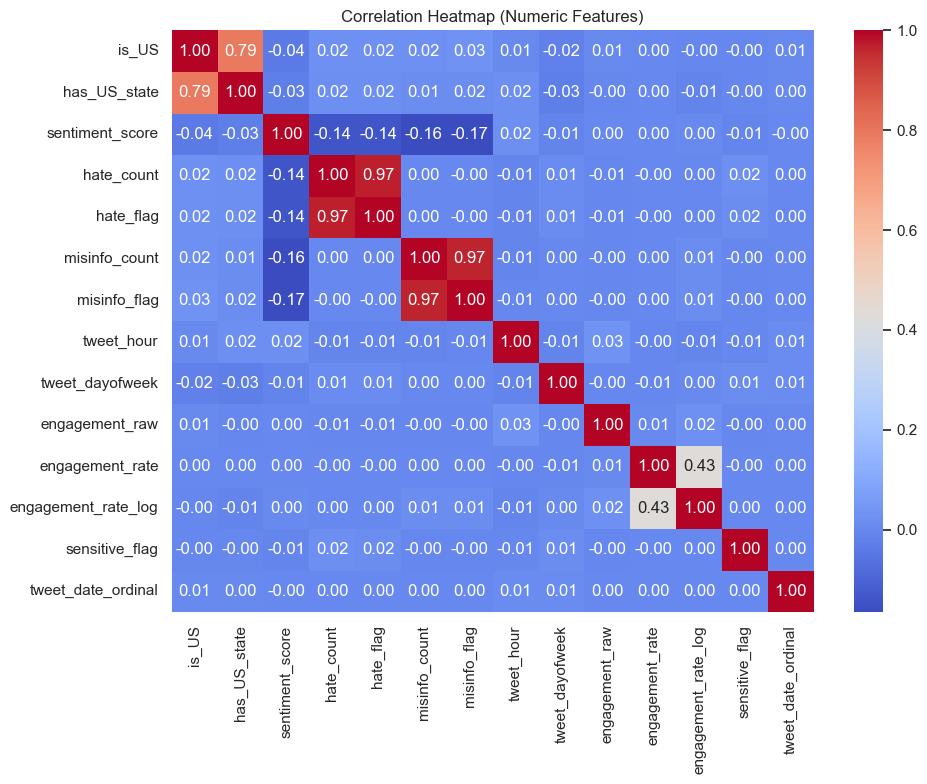

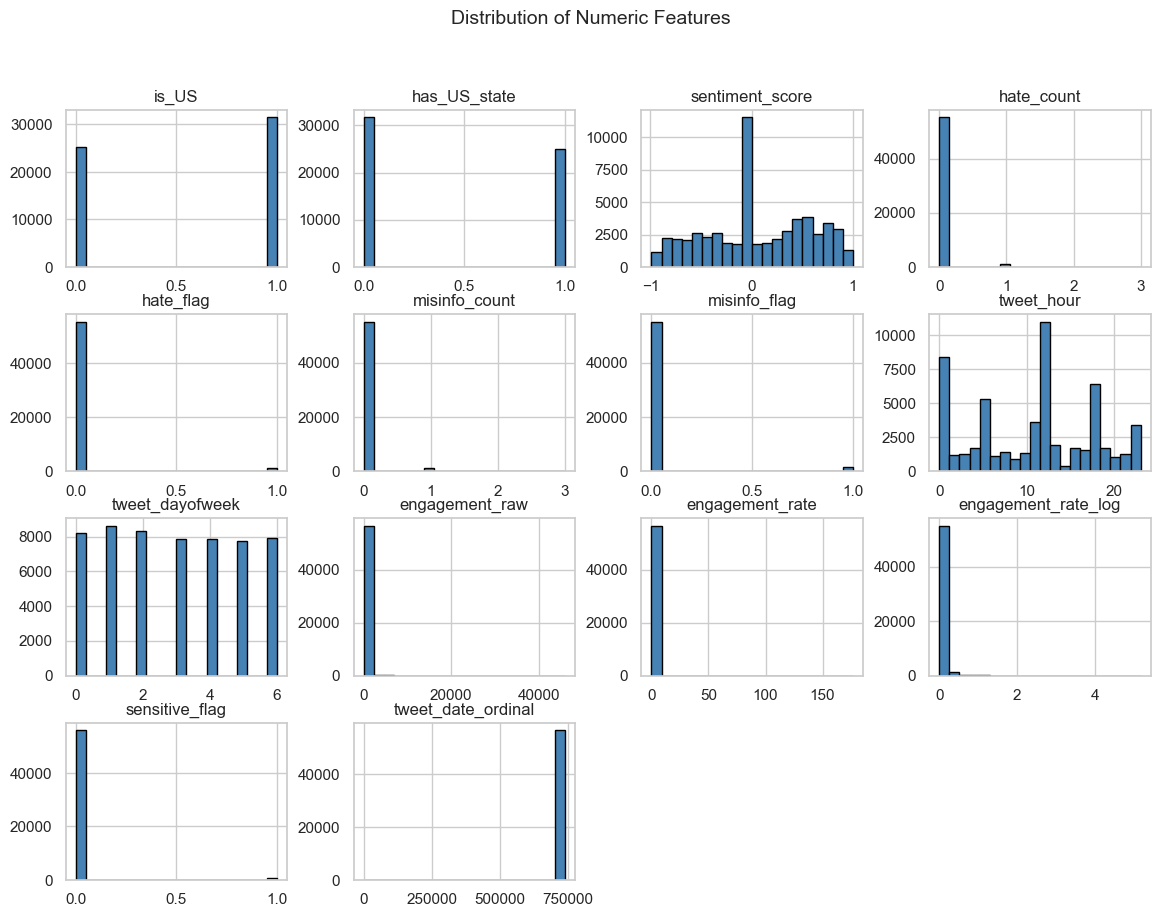


=== FEATURE DISTRIBUTION INSIGHTS (skew/kurtosis) ===
is_US                | skew= -0.23 | kurtosis= -1.95
has_US_state         | skew=  0.24 | kurtosis= -1.94
sentiment_score      | skew= -0.16 | kurtosis= -0.94
hate_count           | skew=  7.24 | kurtosis= 59.76
hate_flag            | skew=  6.25 | kurtosis= 37.07
misinfo_count        | skew=  6.98 | kurtosis= 53.99
misinfo_flag         | skew=  6.05 | kurtosis= 34.63
tweet_hour           | skew= -0.05 | kurtosis= -1.08
tweet_dayofweek      | skew=  0.05 | kurtosis= -1.26
engagement_raw       | skew= 80.02 | kurtosis=8468.47
engagement_rate      | skew=203.46 | kurtosis=44872.16
engagement_rate_log  | skew=  9.22 | kurtosis=258.65
sensitive_flag       | skew=  9.39 | kurtosis= 86.14
tweet_date_ordinal   | skew=-168.14 | kurtosis=28275.91

Cleaned candidate_fan distribution:
candidate_fan
Neutral         27340
Trump           22811
Biden_Kamala     6443
Name: count, dtype: int64


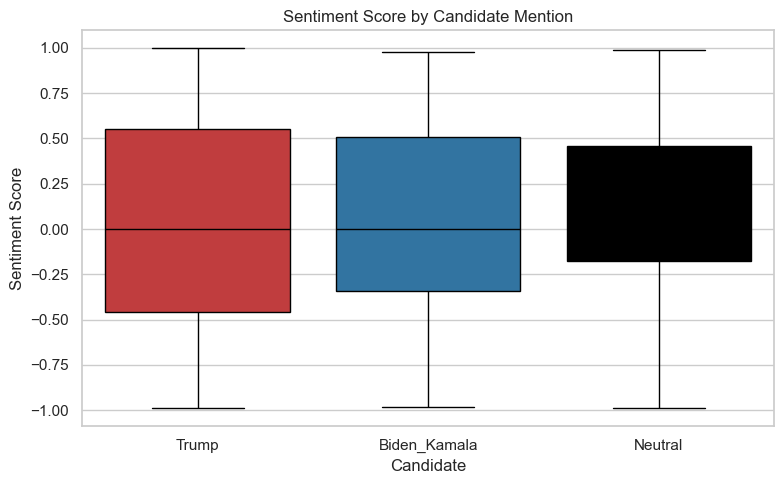

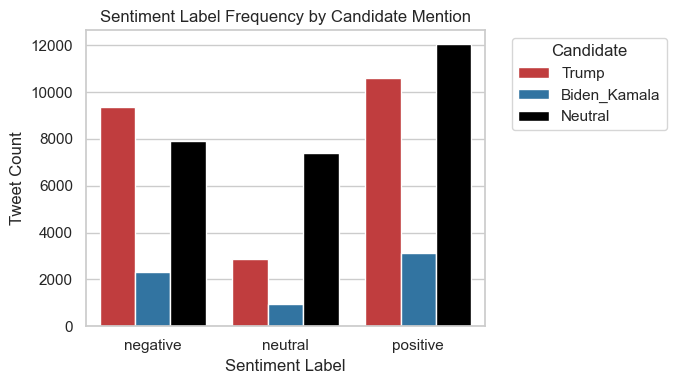

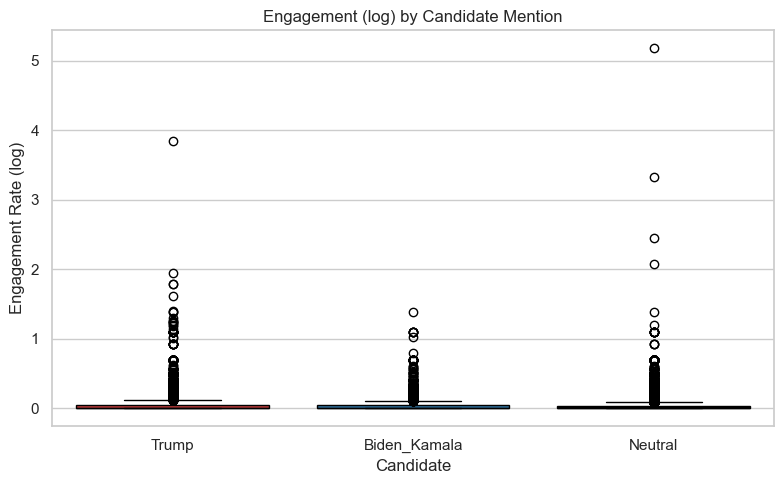


Average misinfo/hate frequency per candidate:


,misinfo_flag,hate_flag
candidate_fan,,
Trump,0.061155,0.030862
Biden_Kamala,0.001086,0.027161
Neutral,0.000988,0.017081


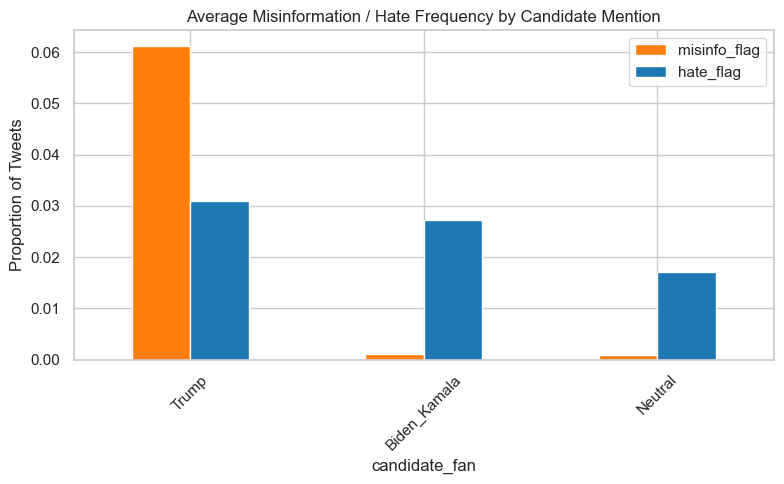

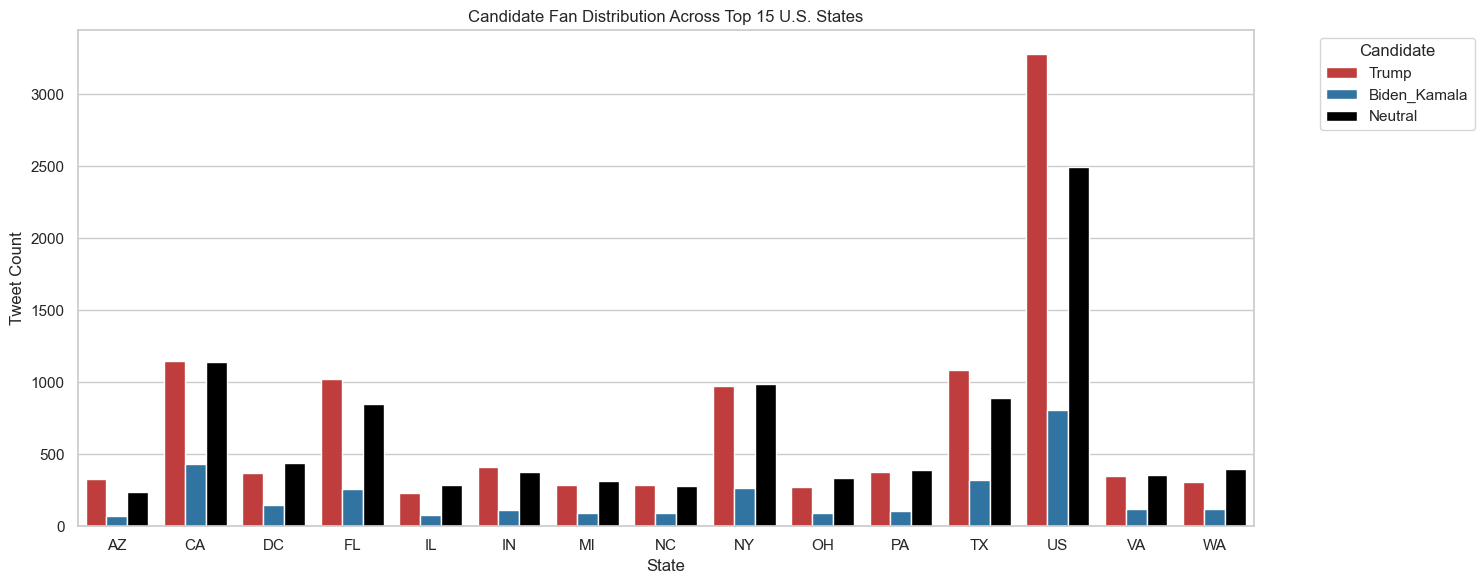

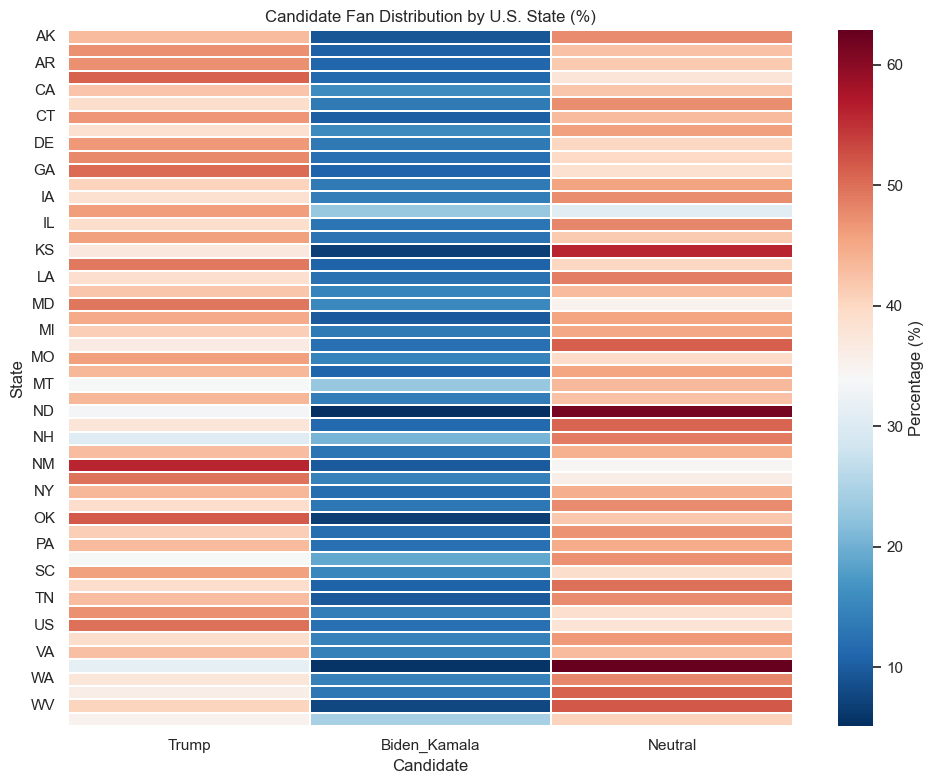

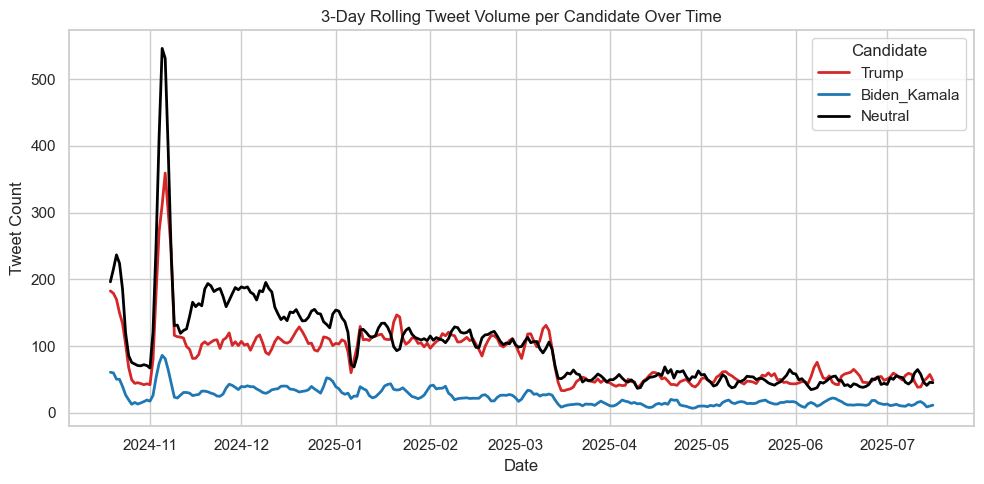


 EDA completed for numeric, categorical, and candidate-level features (Trump / Biden_Kamala / Neutral).


In [ ]:
# ================================================================
# STEP 0. IMPORTS
# ================================================================
!pip install transformers accelerate torch seaborn

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.decomposition import TruncatedSVD

from transformers import AutoTokenizer
from scipy.stats import skew, kurtosis

sns.set(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)

# ================================================================
# STEP 1. BASIC CONFIGURATION
# ================================================================

ENGINEERED_COLS = [
    "clean_text_election",
    "user_state",
    "is_US",
    "has_US_state",
    "sentiment_score",
    "sentiment_label",
    "hate_count",
    "hate_flag",
    "misinfo_count",
    "misinfo_flag",
    "tweet_date",
    "tweet_hour",
    "tweet_dayofweek",
    "temporal_period",
    "engagement_raw",
    "engagement_rate",
    "engagement_rate_log",
    "sensitive_flag",
    "candidate_fan",
]

# Remove old target if present
if "election_result" in df.columns:
    df = df.drop(columns=["election_result"])

print("Engineered columns (for reference):")
print(ENGINEERED_COLS)

TARGET_COL = "candidate_fan"
TEXT_COL = "clean_text_election"

if TARGET_COL not in df.columns:
    raise ValueError(f"TARGET_COL='{TARGET_COL}' not found in df.columns.")

# Convert tweet_date to ordinal numeric feature
if "tweet_date" in df.columns:
    df["tweet_date"] = pd.to_datetime(df["tweet_date"], errors="coerce")
    df["tweet_date_ordinal"] = df["tweet_date"].map(
        lambda x: x.toordinal() if not pd.isna(x) else np.nan
    )
else:
    print("WARNING: 'tweet_date' column not found; skipping date ordinal feature.")
    df["tweet_date_ordinal"] = np.nan

NUMERIC_COLS = [
    "is_US",
    "has_US_state",
    "sentiment_score",
    "hate_count",
    "hate_flag",
    "misinfo_count",
    "misinfo_flag",
    "tweet_hour",
    "tweet_dayofweek",
    "engagement_raw",
    "engagement_rate",
    "engagement_rate_log",
    "sensitive_flag",
    "tweet_date_ordinal",
]

CATEGORICAL_COLS = [
    "user_state",
    "sentiment_label",
    "temporal_period",
]

print("\nUsing ALL engineered features as inputs (except target).")
print("Target column       :", TARGET_COL)
print("Text column         :", TEXT_COL)
print("Numeric feature cols:", NUMERIC_COLS)
print("Categorical cols    :", CATEGORICAL_COLS)

# ================================================================
# STEP 2. BUILD df_model (FULL DATA FOR EDA + MODELING)
# ================================================================

df_model = df.copy()

# Drop empty text rows
df_model = df_model[
    df_model[TEXT_COL].notna() & (df_model[TEXT_COL].str.strip() != "")
]

# Numeric cleanup
for col in NUMERIC_COLS:
    df_model[col] = df_model[col].fillna(0)

# Categorical cleanup
for col in CATEGORICAL_COLS:
    df_model[col] = df_model[col].astype(str).fillna("Unknown")

# Clean candidate_fan target → keep three labels: Trump, Biden_Kamala, Neutral
df_model[TARGET_COL] = (
    df_model[TARGET_COL]
    .astype(str)
    .str.strip()
)

# normalize to exact spelling if needed
df_model[TARGET_COL] = df_model[TARGET_COL].replace({
    "biden_kamala": "Biden_Kamala",
    "Biden_kamala": "Biden_Kamala",
    "biden_kamala ": "Biden_Kamala",
    "neutral": "Neutral",
    "trump": "Trump",
})

print("\n=== df_model ready for EDA and modeling ===")
print("df_model shape:", df_model.shape)

print("\nUnique candidate_fan values:", df_model[TARGET_COL].value_counts())

# ================================================================
# STEP 3. EDA – BASIC NUMERIC + CATEGORICAL
# ================================================================

print("\n=== BASIC DATASET INFO ===")
print(df_model.info())
print("\nDataset shape:", df_model.shape)

print("\n=== NUMERIC FEATURES SUMMARY ===")
display(df_model[NUMERIC_COLS].describe().T)

print("\n=== CATEGORICAL FEATURES VALUE COUNTS ===")
for col in CATEGORICAL_COLS:
    print(f"\nColumn: {col}")
    print(df_model[col].value_counts().head(10))
    print("-" * 60)

print("\nTarget Distribution (candidate_fan):")
print(df_model[TARGET_COL].value_counts())

# Correlation matrix
plt.figure(figsize=(10, 8))
corr = df_model[NUMERIC_COLS].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", cbar=True)
plt.title("Correlation Heatmap (Numeric Features)")
plt.tight_layout()
plt.show()

# Histograms for numeric features
df_model[NUMERIC_COLS].hist(
    figsize=(14, 10),
    bins=20,
    color="steelblue",
    edgecolor="black",
)
plt.suptitle("Distribution of Numeric Features", fontsize=14)
plt.show()

print("\n=== FEATURE DISTRIBUTION INSIGHTS (skew/kurtosis) ===")
for col in NUMERIC_COLS:
    col_skew = skew(df_model[col])
    col_kurt = kurtosis(df_model[col])
    print(f"{col:20s} | skew={col_skew:6.2f} | kurtosis={col_kurt:6.2f}")

# ================================================================
# STEP 3B. EDA – CANDIDATE / STATE / TEMPORAL WITH CONSISTENT COLORS
# ================================================================

# Three-category setup: Trump / Biden_Kamala / Neutral
candidate_order = ["Trump", "Biden_Kamala", "Neutral"]

candidate_colors = {
    "Trump":        "#d62728",   # red
    "Biden_Kamala": "#1f77b4",   # blue
    "Neutral":      "#000000",   # black
}

# Ensure target only contains these 3 values (anything else -> Neutral)
df_model[TARGET_COL] = df_model[TARGET_COL].where(
    df_model[TARGET_COL].isin(candidate_order),
    "Neutral",
)

print("\nCleaned candidate_fan distribution:")
print(df_model[TARGET_COL].value_counts())

# ---- Candidate vs Sentiment (boxplot) ----
plt.figure(figsize=(8, 5))
sns.boxplot(
    data=df_model,
    x=TARGET_COL,
    y="sentiment_score",
    hue=TARGET_COL,
    order=candidate_order,
    hue_order=candidate_order,
    palette=candidate_colors,
    dodge=False,
)
plt.title("Sentiment Score by Candidate Mention")
plt.ylabel("Sentiment Score")
plt.xlabel("Candidate")
plt.legend([], [], frameon=False)  # hide duplicate legend
plt.tight_layout()
plt.show()

# ---- Sentiment label distribution by candidate ----
plt.figure(figsize=(7, 4))
sns.countplot(
    x="sentiment_label",
    hue=TARGET_COL,
    data=df_model,
    order=["negative", "neutral", "positive"],
    hue_order=candidate_order,
    palette=candidate_colors,
)
plt.title("Sentiment Label Frequency by Candidate Mention")
plt.xlabel("Sentiment Label")
plt.ylabel("Tweet Count")
plt.legend(title="Candidate", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()

# ---- Candidate vs Engagement ----
plt.figure(figsize=(8, 5))
sns.boxplot(
    data=df_model,
    x=TARGET_COL,
    y="engagement_rate_log",
    hue=TARGET_COL,
    order=candidate_order,
    hue_order=candidate_order,
    palette=candidate_colors,
    dodge=False,
)
plt.title("Engagement (log) by Candidate Mention")
plt.ylabel("Engagement Rate (log)")
plt.xlabel("Candidate")
plt.legend([], [], frameon=False)
plt.tight_layout()
plt.show()

# ---- Candidate vs Misinfo / Hate ----
misinfo_summary = (
    df_model.groupby(TARGET_COL)[["misinfo_flag", "hate_flag"]]
    .mean()
    .reindex(candidate_order)
)
print("\nAverage misinfo/hate frequency per candidate:")
display(misinfo_summary)

misinfo_summary.plot(kind="bar", color=["#ff7f0e", "#1f77b4"])
plt.title("Average Misinformation / Hate Frequency by Candidate Mention")
plt.ylabel("Proportion of Tweets")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# ================================================================
# CANDIDATE vs STATE – BAR CHART + HEATMAP
# ================================================================

df_model["user_state"] = df_model["user_state"].fillna("Unknown")

# aggregated counts for state × candidate
state_cand = (
    df_model[df_model["is_US"] == 1]
    .groupby(["user_state", TARGET_COL])
    .size()
    .reset_index(name="count")
)

# Top 10 states by total tweet volume
top10_states = (
    state_cand.groupby("user_state")["count"]
    .sum()
    .nlargest(15)
    .index
)
state_cand_top = state_cand[state_cand["user_state"].isin(top10_states)]

plt.figure(figsize=(15, 6))
sns.barplot(
    data=state_cand_top,
    x="user_state",
    y="count",
    hue=TARGET_COL,
    hue_order=candidate_order,
    palette=candidate_colors,
)
plt.title("Candidate Fan Distribution Across Top 15 U.S. States")
plt.xlabel("State")
plt.ylabel("Tweet Count")
plt.legend(title="Candidate", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()

# Heatmap of candidate share per state (all states)
state_cand_heat = (
    df_model[df_model["is_US"] == 1]
    .groupby(["user_state", TARGET_COL])
    .size()
    .unstack(fill_value=0)
    .reindex(columns=candidate_order, fill_value=0)
)

state_cand_prop = state_cand_heat.div(state_cand_heat.sum(axis=1), axis=0) * 100

plt.figure(figsize=(10, 8))
sns.heatmap(
    state_cand_prop,
    cmap="RdBu_r",
    linewidths=0.3,
    cbar_kws={"label": "Percentage (%)"},
)
plt.title("Candidate Fan Distribution by U.S. State (%)")
plt.xlabel("Candidate")
plt.ylabel("State")
plt.tight_layout()
plt.show()

# ================================================================
# TEMPORAL TRENDS per candidate
# ================================================================
df_model["tweet_date"] = pd.to_datetime(df_model["tweet_date"], errors="coerce")

daily_cand = (
    df_model.groupby(["tweet_date", TARGET_COL])
    .size()
    .unstack(fill_value=0)
    .reindex(columns=candidate_order, fill_value=0)
)

rolling_daily = daily_cand.rolling(window=3).mean()

plt.figure(figsize=(10, 5))
for cand in candidate_order:
    if cand in rolling_daily.columns:
        plt.plot(
            rolling_daily.index,
            rolling_daily[cand],
            label=cand,
            color=candidate_colors[cand],
            linewidth=2,
        )

plt.title("3-Day Rolling Tweet Volume per Candidate Over Time")
plt.xlabel("Date")
plt.ylabel("Tweet Count")
plt.legend(title="Candidate")
plt.tight_layout()
plt.show()

print("\n EDA completed for numeric, categorical, and candidate-level features (Trump / Biden_Kamala / Neutral).")


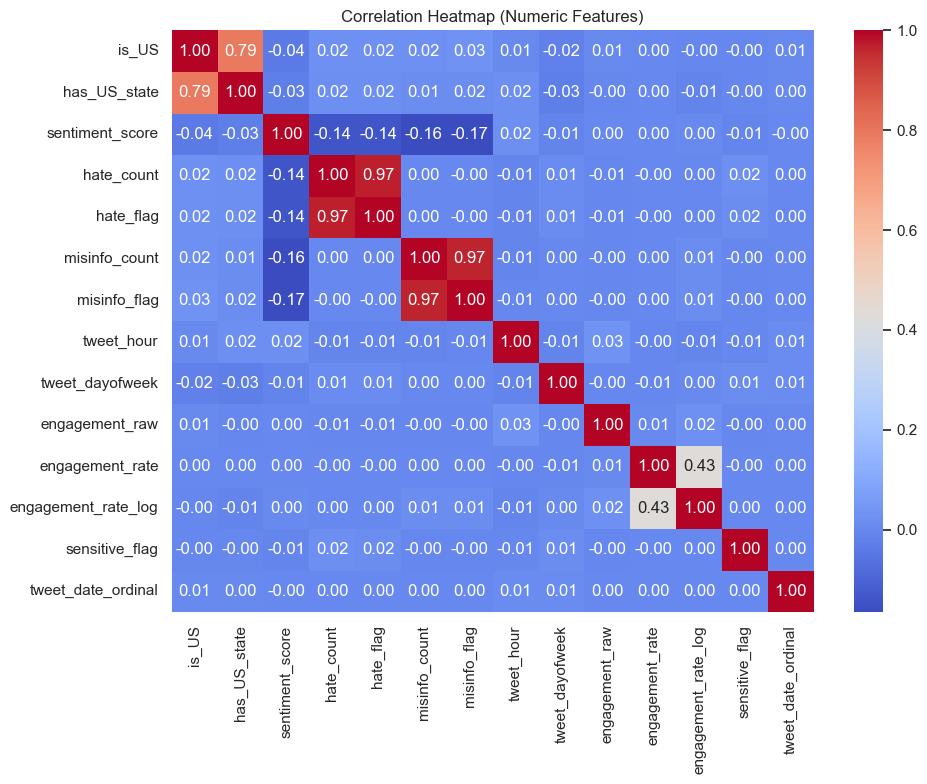

 Correlation heatmap saved as 'correlation_heatmap.png'


In [ ]:
# Correlation matrix and save to file
plt.figure(figsize=(10, 8))
corr = df_model[NUMERIC_COLS].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", cbar=True)

plt.title("Correlation Heatmap (Numeric Features)")
plt.tight_layout()

# Save high-quality image (adjust dpi if needed)
plt.savefig("correlation_heatmap.png", dpi=300, bbox_inches="tight")

plt.show()
print(" Correlation heatmap saved as 'correlation_heatmap.png'")


LDA analysis

In [ ]:


df["clean_text_election"]

import nltk, re
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
nltk.download("punkt")
nltk.download("stopwords")

stop_words = set(stopwords.words("english"))

def tokenize_for_lda(text):
    text = text.lower()
    text = re.sub(r"http\S+|www\S+", "", text)
    text = re.sub(r"[^a-z\s]", " ", text)
    tokens = word_tokenize(text)
    tokens = [w for w in tokens if w not in stop_words and len(w) > 2]
    return tokens

df["lda_tokens"] = df["clean_text_election"].astype(str).apply(tokenize_for_lda)

from gensim import corpora

dictionary = corpora.Dictionary(df["lda_tokens"])

# Filter out:
# rare words (<20 tweets)
# overly common words (>50% tweets)
dictionary.filter_extremes(no_below=20, no_above=0.5)

corpus = [dictionary.doc2bow(tokens) for tokens in df["lda_tokens"]]

from gensim.models.ldamodel import LdaModel

NUM_TOPICS = 10

lda_model = LdaModel(
    corpus=corpus,
    id2word=dictionary,
    num_topics=NUM_TOPICS,
    passes=10,
    random_state=42
)

for topic_id, topic_words in lda_model.show_topics(num_topics=NUM_TOPICS, formatted=False):
    print(f"\nTopic {topic_id}:")
    print([word for word, prob in topic_words])


[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\sorah\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\sorah\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!



Topic 0:
['party', 'general', 'house', 'candidate', 'seat', 'senate', 'one', 'labour', 'member', 'government']

Topic 1:
['year', 'day', 'time', 'since', 'make', 'last', 'one', 'month', 'market', 'see']

Topic 2:
['state', 'presidential', 'show', 'poll', 'datum', 'voter', 'like', 'swing', 'result', 'claim']

Topic 3:
['court', 'fraud', 'case', 'law', 'interference', 'amp', 'state', 'russia', 'right', 'supreme']

Topic 4:
['news', 'united', 'states', 'presidential', 'medium', 'ghana', 'party', 'break', 'via', 'watch']

Topic 5:
['read', 'war', 'support', 'full', 'story', 'article', 'ukraine', 'book', 'yes', 'line']

Topic 6:
['trump', 'president', 'harris', 'donald', 'kamala', 'win', 'biden', 'presidential', 'campaign', 'joe']

Topic 7:
['trump', 'win', 'people', 'get', 'steal', 'would', 'say', 'rig', 'musk', 'think']

Topic 8:
['vote', 'voter', 'million', 'win', 'result', 'electoral', 'bjp', 'presidential', 'assembly', 'woman']

Topic 9:
['day', 'vote', 'ballot', 'result', 'county', '

Visualization

In [ ]:
####
!pip install pyLDAvis

import pyLDAvis
import pyLDAvis.gensim_models as gensimvis  # <- important


pyLDAvis.enable_notebook()

vis = gensimvis.prepare(
    lda_model,
    corpus,
    dictionary,      # this is your id2word
    mds='mmds',      # not “mmds”
    R=30             # number of top words per topic (increase for more words)
)

vis


from gensim.models.ldamodel import LdaModel

NUM_TOPICS = 5  # e.g. 20 topics

lda_model = LdaModel(
    corpus=corpus,
    id2word=dictionary,
    num_topics=NUM_TOPICS,
    passes=10,
    random_state=100
)

vis = gensimvis.prepare(
    lda_model,
    corpus,
    dictionary,
    mds='mmds',
    R=15
)
vis



pyLDAvis.save_html(vis, "lda_twitter_election_topics_5.html")

vis



PreparedData(topic_coordinates=              x         y  topics  cluster       Freq
topic                                                
3      0.143312  0.194299       1        1  32.864820
0     -0.038122 -0.269085       2        1  19.848722
1     -0.292356 -0.064478       3        1  18.443627
2     -0.151509  0.283972       4        1  17.898364
4      0.338675 -0.144708       5        1  10.944467, topic_info=             Term          Freq         Total Category  logprob  loglift
48          trump  17641.000000  17641.000000  Default  15.0000  15.0000
40           vote  10723.000000  10723.000000  Default  14.0000  14.0000
153         state   4056.000000   4056.000000  Default  13.0000  13.0000
46      president   4807.000000   4807.000000  Default  12.0000  12.0000
293         voter   4761.000000   4761.000000  Default  11.0000  11.0000
..            ...           ...           ...      ...      ...      ...
704        member    467.966243    669.715469   Topic5  -5.1863   1.8539
458        report    646.318174   1701.774344   Topic5  -4.8634   1.2442
61       december    515.811473    901.377881   Topic5  -5.0890   1.6542
9    presidential    643.644156   5710.027278   Topic5  -4.8676   0.0295
1       candidate    513.285329   2142.298593   Topic5  -5.0939   0.7835

[165 rows x 6 columns], token_table=      Topic      Freq     Term
term                          
255       1  0.999103  america
2683      3  0.997837    among
140       1  0.312389      amp
140       2  0.335546      amp
140       3  0.216357      amp
...     ...       ...      ...
181       2  0.091110     year
181       3  0.521891     year
181       4  0.031034     year
181       5  0.024486     year
397       5  0.997130     york

[268 rows x 3 columns], R=15, lambda_step=0.01, plot_opts={'xlab': 'PC1', 'ylab': 'PC2'}, topic_order=[4, 1, 2, 3, 5])

Force to Find related to Candidates

In [ ]:
TRUMP_WORDS  = ["trump", "maga", "donald", "republican"]
BIDEN_WORDS  = ["biden", "joe", "democrat", "democrats"]
HARRIS_WORDS = ["harris", "kamala", "kamala harris"]

NUM_TOPICS = 5

TRUMP_TOPIC  = 0
BIDEN_TOPIC  = 1
HARRIS_TOPIC = 2

import numpy as np

vocab_size = len(dictionary)
eta = np.full((NUM_TOPICS, vocab_size), 0.01, dtype=np.float32)  # baseline

# helper: get ids for existing words
def word_ids(words):
    return [dictionary.token2id[w] for w in words if w in dictionary.token2id]

trump_ids  = word_ids(TRUMP_WORDS)
biden_ids  = word_ids(BIDEN_WORDS)
harris_ids = word_ids(HARRIS_WORDS)

# boost priors for each candidate topic
for wid in trump_ids:
    eta[TRUMP_TOPIC, wid] = 5.0

for wid in biden_ids:
    eta[BIDEN_TOPIC, wid] = 5.0

for wid in harris_ids:
    eta[HARRIS_TOPIC, wid] = 5.0




In [ ]:
from gensim.models.ldamodel import LdaModel

lda_guided = LdaModel(
    corpus=corpus,
    id2word=dictionary,
    num_topics=NUM_TOPICS,
    passes=20,
    random_state=100,
    eta=eta,          # <- this is the key
)


import pyLDAvis.gensim_models as gensimvis
pyLDAvis.enable_notebook()

vis = gensimvis.prepare(lda_guided, corpus, dictionary, mds='mmds', R=15)
vis



PreparedData(topic_coordinates=              x         y  topics  cluster       Freq
topic                                                
3      0.289193  0.007264       1        1  33.705320
0      0.131306  0.271109       2        1  19.155540
1     -0.245509 -0.128289       3        1  17.967090
2     -0.244775  0.215056       4        1  17.600968
4      0.069785 -0.365140       5        1  11.571081, topic_info=             Term          Freq         Total Category  logprob  loglift
48          trump  18220.000000  18220.000000  Default  15.0000  15.0000
40           vote  11167.000000  11167.000000  Default  14.0000  14.0000
153         state   4219.000000   4219.000000  Default  13.0000  13.0000
46      president   4929.000000   4929.000000  Default  12.0000  12.0000
293         voter   4955.000000   4955.000000  Default  11.0000  11.0000
..            ...           ...           ...      ...      ...      ...
407      campaign    781.975996   2281.838062   Topic5  -4.7286   1.0857
135         today    596.743740   1334.494049   Topic5  -4.9989   1.3518
527          join    548.767667    793.099129   Topic5  -5.0827   1.7884
9    presidential    596.732658   5940.865433   Topic5  -4.9989  -0.1415
476       support    556.040308   2202.811105   Topic5  -5.0696   0.7800

[162 rows x 6 columns], token_table=      Topic      Freq     Term
term                          
255       1  1.000144  america
2683      3  0.999535    among
140       1  0.318706      amp
140       2  0.315676      amp
140       3  0.249252      amp
...     ...       ...      ...
181       1  0.310720     year
181       2  0.108575     year
181       3  0.577792     year
181       5  0.003001     year
397       5  0.998950     york

[252 rows x 3 columns], R=15, lambda_step=0.01, plot_opts={'xlab': 'PC1', 'ylab': 'PC2'}, topic_order=[4, 1, 2, 3, 5])

In [ ]:
SEED_WORDS = TRUMP_WORDS + BIDEN_WORDS + HARRIS_WORDS

for w in SEED_WORDS:
    print(w, w in dictionary.token2id)


TRUMP_WORDS  = ["trump", "maga", "donald", "republican"]
BIDEN_WORDS  = ["biden", "joe", "democrat", "democrats"]
HARRIS_WORDS = ["harris", "kamala"]


import numpy as np

NUM_TOPICS = 10          # keep what you already use
TRUMP_TOPIC  = 0
BIDEN_TOPIC  = 1
HARRIS_TOPIC = 2

baseline = 0.01          # small prior for all words
boost    = 70.0          # strong prior for seed words

vocab_size = len(dictionary)
eta = np.full((NUM_TOPICS, vocab_size), baseline, dtype=np.float32)

def word_ids(words):
    return [dictionary.token2id[w] for w in words if w in dictionary.token2id]

trump_ids  = word_ids(TRUMP_WORDS)
biden_ids  = word_ids(BIDEN_WORDS)
harris_ids = word_ids(HARRIS_WORDS)

for wid in trump_ids:
    eta[TRUMP_TOPIC, wid] = boost

for wid in biden_ids:
    eta[BIDEN_TOPIC, wid] = boost

for wid in harris_ids:
    eta[HARRIS_TOPIC, wid] = boost


from gensim.models.ldamodel import LdaModel

lda_guided = LdaModel(
    corpus=corpus,
    id2word=dictionary,
    num_topics=NUM_TOPICS,
    passes=20,
    random_state=100,
    eta=eta,          # ← the key line
)


for i in [0, 1, 2]:
    print(f"\nTopic {i}")
    print(lda_guided.print_topic(i, topn=10))




trump True
maga True
donald True
republican True
biden True
joe True
democrat True
democrats True
harris True
kamala True
kamala harris False

Topic 0
0.021*"people" + 0.019*"vote" + 0.018*"get" + 0.015*"like" + 0.013*"know" + 0.013*"would" + 0.013*"think" + 0.013*"win" + 0.012*"one" + 0.012*"say"

Topic 1
0.014*"year" + 0.012*"post" + 0.011*"market" + 0.010*"since" + 0.009*"high" + 0.009*"political" + 0.008*"policy" + 0.008*"cycle" + 0.008*"show" + 0.007*"crypto"

Topic 2
0.044*"day" + 0.028*"vote" + 0.021*"result" + 0.018*"november" + 0.017*"general" + 0.016*"voting" + 0.015*"live" + 0.014*"ballot" + 0.012*"voter" + 0.012*"nov"


In [ ]:
df.to_csv("cleaned_election_tweets.csv", index=False)
print("Saved cleaned dataset to cleaned_election_tweets.csv")


Saved cleaned dataset to cleaned_election_tweets.csv


Training MOdels

In [ ]:
#exit

In [ ]:
# ================================================================
# STEP 4. TRAIN/TEST SPLIT (80/20) – TARGET = candidate_fan
# ================================================================

X = df_model[[TEXT_COL] + NUMERIC_COLS + CATEGORICAL_COLS]
y = df_model[TARGET_COL]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,           # 80/20 split
    random_state=42,
    stratify=y if y.nunique() > 1 else None,
)

print("\nTrain size:", X_train.shape, " Test size:", X_test.shape)

# ================================================================
# STEP 5. TRANSFORMATIONS BY MODEL FAMILY
# ================================================================
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.decomposition import TruncatedSVD
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# ------------------------------------------------
# 5.1 CLASSICAL MODELS (LogReg / SVM / etc.)
#     -> sparse TF-IDF + scaled numeric (sparse) + sparse one-hot
# ------------------------------------------------

tfidf_classical = TfidfVectorizer(
    ngram_range=(1, 2),
    max_features=20000,
)

numeric_sparse_scaler = StandardScaler(with_mean=False)
onehot_sparse = OneHotEncoder(handle_unknown="ignore")  # default sparse=True

preproc_classical = ColumnTransformer(
    transformers=[
        ("text", tfidf_classical, TEXT_COL),
        ("num", numeric_sparse_scaler, NUMERIC_COLS),
        ("cat", onehot_sparse, CATEGORICAL_COLS),
    ]
)

print("\n=== TRANSFORMING DATA FOR CLASSICAL MODELS ===")
X_train_classical = preproc_classical.fit_transform(X_train)
X_test_classical  = preproc_classical.transform(X_test)

print("Classical → X_train shape:", X_train_classical.shape)
print("Classical → X_test  shape:", X_test_classical.shape)

# ------------------------------------------------
# 5.2 TREE MODELS (HistGradientBoosting / XGBoost-like)
#     -> dense SVD(text) + raw numeric + dense one-hot
# ------------------------------------------------

text_svd_pipe = Pipeline(
    steps=[
        ("tfidf", TfidfVectorizer(ngram_range=(1, 2), max_features=30000)),
        ("svd", TruncatedSVD(n_components=100, random_state=42)),
    ]
)

onehot_dense = OneHotEncoder(handle_unknown="ignore", sparse_output=False)

preproc_hgb = ColumnTransformer(
    transformers=[
        ("text_svd", text_svd_pipe, TEXT_COL),
        ("num", "passthrough", NUMERIC_COLS),
        ("cat", onehot_dense, CATEGORICAL_COLS),
    ]
)

print("\n=== TRANSFORMING DATA FOR TREE MODELS (HGB) ===")
X_train_hgb = preproc_hgb.fit_transform(X_train)
X_test_hgb  = preproc_hgb.transform(X_test)

print("HGB → X_train shape:", X_train_hgb.shape)
print("HGB → X_test  shape:", X_test_hgb.shape)


# ------------------------------------------------
# 5.3 MLP / DENSE NEURAL NET MODELS
#     -> dense SVD(text) + scaled numeric (dense) + dense one-hot
# ------------------------------------------------

numeric_dense_scaler = StandardScaler(with_mean=True)

preproc_mlp = ColumnTransformer(
    transformers=[
        ("text_svd", text_svd_pipe, TEXT_COL),        # same TF-IDF + SVD
        ("num", numeric_dense_scaler, NUMERIC_COLS),  # scaled numeric
        ("cat", onehot_dense, CATEGORICAL_COLS),      # dense one-hot
    ]
)

print("\n=== TRANSFORMING DATA FOR MLP / DENSE NN MODELS ===")
X_train_mlp = preproc_mlp.fit_transform(X_train)
X_test_mlp  = preproc_mlp.transform(X_test)

print("MLP → X_train shape:", X_train_mlp.shape)
print("MLP → X_test  shape:", X_test_mlp.shape)


# ================================================================
# STEP 6. TRANSFORMER FAMILY (DistilBERT TOKENIZATION)
# ================================================================
from transformers import AutoTokenizer

MODEL_NAME = "distilbert-base-uncased"   # or "vinai/bertweet-base"
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME, use_fast=True)

texts_train = X_train[TEXT_COL].tolist()
texts_test  = X_test[TEXT_COL].tolist()

enc_train = tokenizer(
    texts_train,
    padding=True,
    truncation=True,
    max_length=128,
    return_tensors="pt"
)

enc_test = tokenizer(
    texts_test,
    padding=True,
    truncation=True,
    max_length=128,
    return_tensors="pt"
)

print("\n=== TRANSFORMER TOKENIZATION (DISTILBERT) ===")
print("Train encodings:", {k: v.shape for k, v in enc_train.items()})
print("Test encodings :", {k: v.shape for k, v in enc_test.items()})

import os
os.environ["HF_HUB_DISABLE_SYMLINKS_WARNING"] = "1"

print("\n Transformations completed, separated by model family:")
print(" - Classical: sparse TF-IDF + sparse numeric/categorical")
print(" - HGB: dense SVD text + raw numeric + dense one-hot")
print(" - MLP: dense SVD text + scaled numeric + dense one-hot")
print(" - DistilBERT: tokenized sequences ready for a transformer model")



Train size: (45275, 18)  Test size: (11319, 18)

=== TRANSFORMING DATA FOR CLASSICAL MODELS ===
Classical → X_train shape: (45275, 20074)
Classical → X_test  shape: (11319, 20074)

=== TRANSFORMING DATA FOR TREE MODELS (HGB) ===
HGB → X_train shape: (45275, 174)
HGB → X_test  shape: (11319, 174)

=== TRANSFORMING DATA FOR MLP / DENSE NN MODELS ===
MLP → X_train shape: (45275, 174)
MLP → X_test  shape: (11319, 174)

=== TRANSFORMER TOKENIZATION (DISTILBERT) ===
Train encodings: {'input_ids': torch.Size([45275, 100]), 'attention_mask': torch.Size([45275, 100])}
Test encodings : {'input_ids': torch.Size([11319, 76]), 'attention_mask': torch.Size([11319, 76])}

 Transformations completed, separated by model family:
 - Classical: sparse TF-IDF + sparse numeric/categorical
 - HGB: dense SVD text + raw numeric + dense one-hot
 - MLP: dense SVD text + scaled numeric + dense one-hot
 - DistilBERT: tokenized sequences ready for a transformer model


In [ ]:
print("Train distribution:")
print(y_train.value_counts())
print("\nTrain distribution (ratio):")
print(y_train.value_counts(normalize=True))


Train distribution:
candidate_fan
Neutral         21872
Trump           18249
Biden_Kamala     5154
Name: count, dtype: int64

Train distribution (ratio):
candidate_fan
Neutral         0.483092
Trump           0.403070
Biden_Kamala    0.113838
Name: proportion, dtype: float64


In [ ]:
#balance the training ratio
train_df = X_train.copy()
train_df["candidate_fan"] = y_train

bk_df      = train_df[train_df["candidate_fan"]=="Biden_Kamala"]
neutral_df = train_df[train_df["candidate_fan"]=="Neutral"]
trump_df   = train_df[train_df["candidate_fan"]=="Trump"]

max_n = max(len(bk_df), len(neutral_df), len(trump_df))

bk_up      = bk_df.sample(max_n, replace=True, random_state=42)
neutral_up = neutral_df.sample(max_n, replace=True, random_state=42)
trump_up   = trump_df.sample(max_n, replace=True, random_state=42)

train_balanced = pd.concat([bk_up, neutral_up, trump_up]).sample(frac=1, random_state=42)

X_train_balanced = train_balanced[TEXT_COL].fillna("")
y_train_balanced = train_balanced["candidate_fan"]

print("Train distribution:")
print(y_train_balanced.value_counts())
print("\nTrain distribution (ratio):")
print(y_train_balanced.value_counts(normalize=True))

Train distribution:
candidate_fan
Biden_Kamala    21872
Trump           21872
Neutral         21872
Name: count, dtype: int64

Train distribution (ratio):
candidate_fan
Biden_Kamala    0.333333
Trump           0.333333
Neutral         0.333333
Name: proportion, dtype: float64


In [ ]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.neural_network import MLPClassifier

import torch
from torch.utils.data import Dataset, DataLoader
from torch.optim import AdamW
import torch.nn as nn
from sklearn.preprocessing import LabelEncoder
from transformers import AutoTokenizer, AutoModelForSequenceClassification

# -------------------------------
# Text-only views
# -------------------------------
# Balanced train (you created this already)
X_train_text_bal = X_train_balanced.fillna("")
y_train_bal      = y_train_balanced

# Original test (unchanged, for fair eval)
X_test_text = X_test[TEXT_COL].fillna("")
y_test_true = y_test


In [ ]:
logreg_text_bal = Pipeline([
    ("tfidf", TfidfVectorizer(
        ngram_range=(1, 2),
        max_features=20000,
    )),
    ("logreg", LogisticRegression(
        multi_class="multinomial",
        solver="lbfgs",
        C=0.3,
        penalty="l2",
        class_weight=None,   # we already balanced data
        max_iter=100000,
        n_jobs=-1,
        random_state=42,
    )),
])

logreg_text_bal.fit(X_train_text_bal, y_train_bal)
y_pred_logreg_bal = logreg_text_bal.predict(X_test_text)

print("\n=== Logistic Regression (TEXT ONLY, BALANCED TRAIN) ===")
print("Test accuracy:", accuracy_score(y_test_true, y_pred_logreg_bal))
print("\nClassification report:")
print(classification_report(y_test_true, y_pred_logreg_bal, zero_division=0))
print("\nConfusion matrix:")
print(confusion_matrix(y_test_true, y_pred_logreg_bal))



=== Logistic Regression (TEXT ONLY, BALANCED TRAIN) ===
Test accuracy: 0.9484053361604382

Classification report:
              precision    recall  f1-score   support

Biden_Kamala       0.86      0.92      0.89      1289
     Neutral       0.94      1.00      0.97      5468
       Trump       1.00      0.90      0.94      4562

    accuracy                           0.95     11319
   macro avg       0.93      0.94      0.93     11319
weighted avg       0.95      0.95      0.95     11319


Confusion matrix:
[[1187   88   14]
 [  16 5449    3]
 [ 178  285 4099]]


In [ ]:
svm_text_bal = Pipeline([
    ("tfidf", TfidfVectorizer(
        ngram_range=(1, 2),
        max_features=200000,
    )),
    ("svm", LinearSVC(
        C=1.0,
        loss="squared_hinge",
        dual="auto",
        max_iter=200000,
        class_weight=None,   # balanced in data
        random_state=42,
    )),
])

svm_text_bal.fit(X_train_text_bal, y_train_bal)
y_pred_svm_bal = svm_text_bal.predict(X_test_text)

print("\n=== Linear SVM (TEXT ONLY, BALANCED TRAIN) ===")
print("Test accuracy:", accuracy_score(y_test_true, y_pred_svm_bal))
print("\nClassification report:")
print(classification_report(y_test_true, y_pred_svm_bal, zero_division=0))
print("\nConfusion matrix:")
print(confusion_matrix(y_test_true, y_pred_svm_bal))



=== Linear SVM (TEXT ONLY, BALANCED TRAIN) ===
Test accuracy: 0.9744677091615868

Classification report:
              precision    recall  f1-score   support

Biden_Kamala       0.94      0.92      0.93      1289
     Neutral       0.97      1.00      0.98      5468
       Trump       1.00      0.96      0.98      4562

    accuracy                           0.97     11319
   macro avg       0.97      0.96      0.96     11319
weighted avg       0.97      0.97      0.97     11319


Confusion matrix:
[[1189   84   16]
 [  13 5450    5]
 [  66  105 4391]]


In [ ]:
hgb_text_bal = Pipeline([
    ("tfidf", TfidfVectorizer(
        ngram_range=(1, 2),
        max_features=30000,
    )),
    ("svd", TruncatedSVD(
        n_components=100,
        random_state=42,
    )),
    ("hgb", HistGradientBoostingClassifier(
        loss="log_loss",
        learning_rate=0.1,
        max_depth=None,
        max_iter=200,
        random_state=42,
    )),
])

hgb_text_bal.fit(X_train_text_bal, y_train_bal)
y_pred_hgb_bal = hgb_text_bal.predict(X_test_text)

print("\n=== HistGradientBoosting (TEXT ONLY, BALANCED TRAIN) ===")
print("Test accuracy:", accuracy_score(y_test_true, y_pred_hgb_bal))
print("\nClassification report:")
print(classification_report(y_test_true, y_pred_hgb_bal, zero_division=0))
print("\nConfusion matrix:")
print(confusion_matrix(y_test_true, y_pred_hgb_bal))


c:\Users\sorah\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\Users\sorah\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "c:\Users\sorah\anaconda3\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\sorah\anaconda3\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "c:\Users\sorah\anaconda3\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _winapi.CreatePro


=== HistGradientBoosting (TEXT ONLY, BALANCED TRAIN) ===
Test accuracy: 0.8468946019966428

Classification report:
              precision    recall  f1-score   support

Biden_Kamala       0.71      0.71      0.71      1289
     Neutral       0.83      0.92      0.87      5468
       Trump       0.91      0.80      0.85      4562

    accuracy                           0.85     11319
   macro avg       0.82      0.81      0.81     11319
weighted avg       0.85      0.85      0.85     11319


Confusion matrix:
[[ 918  285   86]
 [ 166 5029  273]
 [ 207  716 3639]]


In [ ]:
mlp_text_bal = Pipeline([
    ("tfidf", TfidfVectorizer(
        ngram_range=(1, 2),
        max_features=30000,
    )),
    ("svd", TruncatedSVD(
        n_components=100,
        random_state=42,
    )),
    ("mlp", MLPClassifier(
        hidden_layer_sizes=(128, 64),
        activation="relu",
        solver="adam",
        alpha=1e-4,
        batch_size=32,
        learning_rate="adaptive",
        max_iter=400,
        random_state=42,
    )),
])

mlp_text_bal.fit(X_train_text_bal, y_train_bal)
y_pred_mlp_bal = mlp_text_bal.predict(X_test_text)

print("\n=== MLP Neural Network (TEXT ONLY, BALANCED TRAIN) ===")
print("Test accuracy:", accuracy_score(y_test_true, y_pred_mlp_bal))
print("\nClassification report:")
print(classification_report(y_test_true, y_pred_mlp_bal, zero_division=0))
print("\nConfusion matrix:")
print(confusion_matrix(y_test_true, y_pred_mlp_bal))



=== MLP Neural Network (TEXT ONLY, BALANCED TRAIN) ===
Test accuracy: 0.8294902376535029

Classification report:
              precision    recall  f1-score   support

Biden_Kamala       0.60      0.75      0.67      1289
     Neutral       0.88      0.82      0.85      5468
       Trump       0.85      0.86      0.86      4562

    accuracy                           0.83     11319
   macro avg       0.78      0.81      0.79     11319
weighted avg       0.84      0.83      0.83     11319


Confusion matrix:
[[ 970  173  146]
 [ 437 4486  545]
 [ 204  425 3933]]


In [ ]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

TEXT_COL = "clean_text_election"   # adjust if needed

# -----------------------------
# Start from your main dataframe
# (already filtered to English)
# -----------------------------
X = df_model[TEXT_COL].fillna("")
y = df_model["candidate_fan"]

# 1) First split: train+val vs test (80/20)
X_train_full, X_test, y_train_full, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

# 2) Second split: train vs val (80/20 of the 80% → 64/16/20 overall)
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full,
    y_train_full,
    test_size=0.20,
    stratify=y_train_full,
    random_state=42
)

print("Sizes:")
print("Train:", len(X_train))
print("Val  :", len(X_val))
print("Test :", len(X_test))

print("\nTrain distribution (before balancing):")
print(y_train.value_counts())
print("\nTrain distribution (ratio):")
print(y_train.value_counts(normalize=True))

# -----------------------------
# Balance TRAIN ONLY (upsample)
# -----------------------------
train_df = pd.DataFrame({
    TEXT_COL: X_train,
    "candidate_fan": y_train
})

bk_df      = train_df[train_df["candidate_fan"] == "Biden_Kamala"]
neutral_df = train_df[train_df["candidate_fan"] == "Neutral"]
trump_df   = train_df[train_df["candidate_fan"] == "Trump"]

max_n = max(len(bk_df), len(neutral_df), len(trump_df))

bk_up      = bk_df.sample(max_n, replace=True, random_state=42)
neutral_up = neutral_df.sample(max_n, replace=True, random_state=42)
trump_up   = trump_df.sample(max_n, replace=True, random_state=42)

train_balanced = pd.concat([bk_up, neutral_up, trump_up]).sample(frac=1, random_state=42)

X_train_bal = train_balanced[TEXT_COL].fillna("")
y_train_bal = train_balanced["candidate_fan"]

print("\nBalanced train distribution:")
print(y_train_bal.value_counts())
print("\nBalanced train distribution (ratio):")
print(y_train_bal.value_counts(normalize=True))

# Final views
X_val_text  = X_val.fillna("")
X_test_text = X_test.fillna("")

y_val_true  = y_val
y_test_true = y_test


Sizes:
Train: 36220
Val  : 9055
Test : 11319

Train distribution (before balancing):
candidate_fan
Neutral         17498
Trump           14599
Biden_Kamala     4123
Name: count, dtype: int64

Train distribution (ratio):
candidate_fan
Neutral         0.483103
Trump           0.403065
Biden_Kamala    0.113832
Name: proportion, dtype: float64

Balanced train distribution:
candidate_fan
Neutral         17498
Trump           17498
Biden_Kamala    17498
Name: count, dtype: int64

Balanced train distribution (ratio):
candidate_fan
Neutral         0.333333
Trump           0.333333
Biden_Kamala    0.333333
Name: proportion, dtype: float64


With hyperparameters tuning

with traing part with overfit and underfit

Ploting and figures for show the initial results of teh models performance

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)


In [ ]:
print("=== DATA SPLITS ===")
print(f"Train size (balanced): {len(X_train_bal)}")
print(f"Val size:              {len(X_val_text)}")
print(f"Test size:             {len(X_test_text)}\n")

print("Train distribution (balanced):")
print(y_train_bal.value_counts(), "\n")
print("Val distribution:")
print(y_val_true.value_counts(), "\n")
print("Test distribution:")
print(y_test_true.value_counts(), "\n")


=== DATA SPLITS ===
Train size (balanced): 52494
Val size:              9055
Test size:             11319

Train distribution (balanced):
candidate_fan
Neutral         17498
Trump           17498
Biden_Kamala    17498
Name: count, dtype: int64 

Val distribution:
candidate_fan
Neutral         4374
Trump           3650
Biden_Kamala    1031
Name: count, dtype: int64 

Test distribution:
candidate_fan
Neutral         5468
Trump           4562
Biden_Kamala    1289
Name: count, dtype: int64 



Helper to compute metrics for any classical model

Evaluate all classical models (LogReg, SVM, HGB, MLP)

Plot val vs test macro-F1 for classical models

load cleaned datset

BERTweet: Train + Validation Loss Curves (Optimization Visualization)

In [ ]:
import torch
import torch.nn as nn
import pandas as pd
from torch.utils.data import Dataset, DataLoader
from torch.optim import AdamW
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    get_linear_schedule_with_warmup
)
from sklearn.preprocessing import LabelEncoder
from tqdm.auto import tqdm

# 1. Setup Device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

# 2. Configuration
MODEL_NAME = "vinai/bertweet-base"
MAX_LEN    = 128
BATCH_SIZE = 16
LR         = 2e-5
EPOCHS     = 4  # Reduced from 8 to prevent overfitting
WEIGHT_DECAY = 0.01

# 3. Label Encoding
# Assuming y_train_bal, y_val_true, y_test_true are already defined
label_encoder = LabelEncoder()
y_all_for_fit = pd.concat([y_train_bal, y_val_true, y_test_true])
label_encoder.fit(y_all_for_fit)

y_train_ids = label_encoder.transform(y_train_bal)
y_val_ids   = label_encoder.transform(y_val_true)
y_test_ids  = label_encoder.transform(y_test_true)

num_labels = len(label_encoder.classes_)
print("Classes:", list(label_encoder.classes_))

# 4. Tokenizer
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME, use_fast=False)

def encode_texts(text_series):
    return tokenizer(
        text_series.tolist(),
        padding=True,
        truncation=True,
        max_length=MAX_LEN,
        return_tensors="pt"
    )

# Assuming X_train_bal, X_val_text, X_test_text are already defined
print("Tokenizing data...")
enc_train = encode_texts(X_train_bal)
enc_val   = encode_texts(X_val_text)
enc_test  = encode_texts(X_test_text)

# 5. Dataset Class
class TweetDataset(Dataset):
    def __init__(self, encodings, labels):
        self.encodings = encodings
        self.labels = labels

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        item = {k: v[idx] for k, v in self.encodings.items()}
        item["labels"] = torch.tensor(self.labels[idx], dtype=torch.long)
        return item

# 6. DataLoaders
train_dataset = TweetDataset(enc_train, y_train_ids)
val_dataset   = TweetDataset(enc_val,   y_val_ids)
test_dataset  = TweetDataset(enc_test,  y_test_ids)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader   = DataLoader(val_dataset,   batch_size=BATCH_SIZE, shuffle=False)
test_loader  = DataLoader(test_dataset,  batch_size=BATCH_SIZE, shuffle=False)

# 7. Model Setup
bert_model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=num_labels
).to(device)

# 8. Optimizer & Scheduler
optimizer = AdamW(bert_model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
loss_fct  = nn.CrossEntropyLoss()

total_steps = len(train_loader) * EPOCHS
scheduler = get_linear_schedule_with_warmup(
    optimizer,
    num_warmup_steps=int(0.1 * total_steps),
    num_training_steps=total_steps
)

# 9. Training Loop
best_val_loss = float('inf')
train_losses = []
val_losses   = []

print("Starting training...")

for epoch in range(EPOCHS):
    # --- TRAIN ---
    bert_model.train()
    total_train_loss = 0.0

    train_loop = tqdm(train_loader, desc=f"Epoch {epoch+1}/{EPOCHS} [Train]", leave=True)

    for batch in train_loop:
        batch = {k: v.to(device) for k, v in batch.items()}

        outputs = bert_model(
            input_ids=batch["input_ids"],
            attention_mask=batch["attention_mask"]
        )
        logits = outputs.logits
        loss = loss_fct(logits, batch["labels"])

        loss.backward()

        # Gradient clipping
        torch.nn.utils.clip_grad_norm_(bert_model.parameters(), 1.0)

        optimizer.step()
        scheduler.step()
        optimizer.zero_grad()

        total_train_loss += loss.item()
        train_loop.set_postfix(loss=loss.item())

    avg_train_loss = total_train_loss / len(train_loader)
    train_losses.append(avg_train_loss)

    # --- VALIDATION ---
    bert_model.eval()
    total_val_loss = 0.0

    val_loop = tqdm(val_loader, desc=f"Epoch {epoch+1}/{EPOCHS} [Val]", leave=True)

    with torch.no_grad():
        for batch in val_loop:
            batch = {k: v.to(device) for k, v in batch.items()}
            outputs = bert_model(
                input_ids=batch["input_ids"],
                attention_mask=batch["attention_mask"],
                labels=batch["labels"]
            )
            total_val_loss += outputs.loss.item()
            val_loop.set_postfix(loss=outputs.loss.item())

    avg_val_loss = total_val_loss / len(val_loader)
    val_losses.append(avg_val_loss)

    print(f"Epoch {epoch+1}: Train Loss={avg_train_loss:.4f}, Val Loss={avg_val_loss:.4f}")

    # Save Best Model
    if avg_val_loss < best_val_loss:
        best_val_loss = avg_val_loss
        bert_model.save_pretrained("./best_bertweet_model")
        tokenizer.save_pretrained("./best_bertweet_model")
        print("  -> New best model saved!")

print("Training complete.")

Using device: cpu
Classes: ['Biden_Kamala', 'Neutral', 'Trump']
Tokenizing data...


Some weights of RobertaForSequenceClassification were not initialized from the model checkpoint at vinai/bertweet-base and are newly initialized: ['classifier.dense.bias', 'classifier.dense.weight', 'classifier.out_proj.bias', 'classifier.out_proj.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Starting training...


Epoch 1/4 [Train]:   0%|          | 0/3281 [00:00<?, ?it/s]

Epoch 1/4 [Val]:   0%|          | 0/566 [00:00<?, ?it/s]

...

Epoch 3/4 [Val]:   0%|          | 0/566 [00:00<?, ?it/s]

Epoch 3: Train Loss=0.0096, Val Loss=0.0292
  -> New best model saved!


Epoch 4/4 [Train]:   0%|          | 0/3281 [00:00<?, ?it/s]

Epoch 4/4 [Val]:   0%|          | 0/566 [00:00<?, ?it/s]

Epoch 4: Train Loss=0.0029, Val Loss=0.0262
  -> New best model saved!
Training complete.


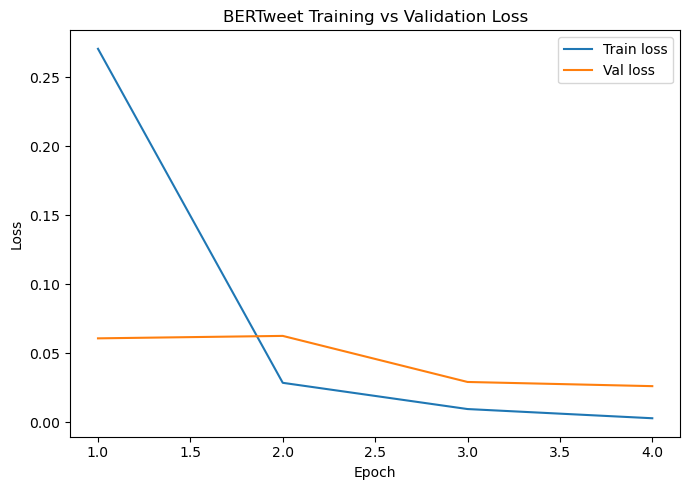

In [ ]:
plt.figure(figsize=(7, 5))
epochs_range = range(1, EPOCHS + 1)

plt.plot(epochs_range, train_losses, label="Train loss")
plt.plot(epochs_range, val_losses,   label="Val loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("BERTweet Training vs Validation Loss")
plt.legend()
plt.tight_layout()
plt.show()


In [ ]:
bert_model.eval()
all_preds = []
all_true  = []

with torch.no_grad():
    for batch in test_loader:
        labels = batch["labels"].numpy()
        batch = {k: v.to(device) for k, v in batch.items() if k != "labels"}

        outputs = bert_model(**batch)
        preds = outputs.logits.argmax(dim=-1).cpu().numpy()

        all_preds.extend(preds)
        all_true.extend(labels)

y_test_str = label_encoder.inverse_transform(all_true)
y_pred_str = label_encoder.inverse_transform(all_preds)

print("\n=== BERTweet (Final Model) ===")
print("Test accuracy:", accuracy_score(y_test_str, y_pred_str))
print("Test f1_macro:", f1_score(y_test_str, y_pred_str, average="macro"))
print("\nTest classification report:")
print(classification_report(y_test_str, y_pred_str, zero_division=0))



=== BERTweet (Final Model) ===
Test accuracy: 0.9959360367523633
Test f1_macro: 0.9953884758948734

Test classification report:
              precision    recall  f1-score   support

Biden_Kamala       0.99      1.00      0.99      1289
     Neutral       1.00      1.00      1.00      5468
       Trump       1.00      0.99      1.00      4562

    accuracy                           1.00     11319
   macro avg       0.99      1.00      1.00     11319
weighted avg       1.00      1.00      1.00     11319



In [ ]:
import torch
import torch.nn.functional as F

def predict_sentiment(text, model, tokenizer, device):
    model.eval()

    # 1. Tokenize the text
    inputs = tokenizer(
        text,
        return_tensors="pt",
        truncation=True,
        padding=True,
        max_length=128
    ).to(device)

    # 2. Get raw scores (logits)
    with torch.no_grad():
        outputs = model(**inputs)
        logits = outputs.logits

    # 3. Convert to probabilities
    probs = F.softmax(logits, dim=1)

    # 4. Get the highest probability class
    pred_idx = torch.argmax(probs, dim=1).item()
    confidence = probs[0][pred_idx].item()

    # Convert index to label (using your label_encoder from training)
    # If you loaded from a saved file, you might need to manually define classes if you didn't save the encoder
    # classes = ['Biden_Kamala', 'Neutral', 'Trump']
    predicted_label = label_encoder.inverse_transform([pred_idx])[0]

    return predicted_label, confidence

# Example usage
test_tweet = "I really support the new policies!"
label, conf = predict_sentiment(test_tweet, bert_model, tokenizer, device)
print(f"Sentiment: {label} (Confidence: {conf:.2%})")

Sentiment: Neutral (Confidence: 100.00%)


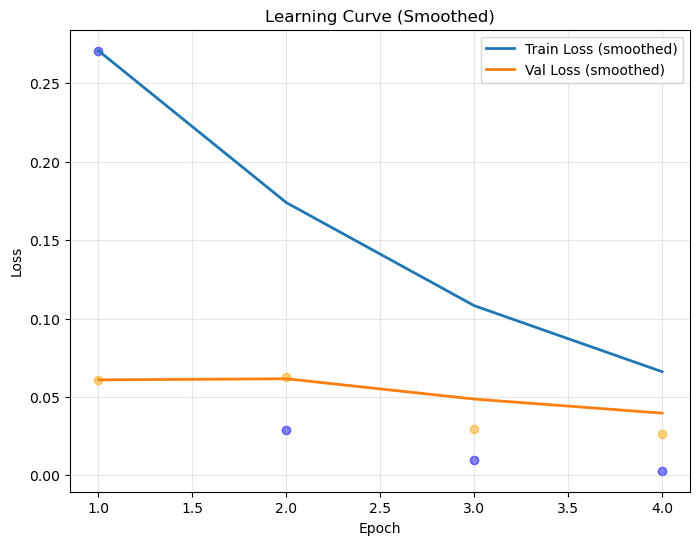

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# ---- Replace these with your real logs ----
# Example structure ONLY:
#train_losses = [0.27, 0.028, 0.0096, 0.0029]
#val_losses   = [0.060, 0.062, 0.029, 0.026]

def smooth(values, weight=0.6):
    """Exponential Moving Average smoothing."""
    smoothed = []
    last = values[0]
    for v in values:
        smoothed_val = last * weight + (1 - weight) * v
        smoothed.append(smoothed_val)
        last = smoothed_val
    return smoothed

epochs = range(1, len(train_losses) + 1)

train_s = smooth(train_losses)
val_s = smooth(val_losses)

plt.figure(figsize=(8,6))
plt.plot(epochs, train_s, label='Train Loss (smoothed)', linewidth=2)
plt.plot(epochs, val_s, label='Val Loss (smoothed)', linewidth=2)
plt.scatter(epochs, train_losses, color='blue', alpha=0.5)
plt.scatter(epochs, val_losses, color='orange', alpha=0.5)
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Learning Curve (Smoothed)')
plt.legend()
plt.grid(alpha=0.3)
plt.show()


In [ ]:
import numpy as np
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix
from sklearn.metrics import accuracy_score, f1_score, classification_report

bert_model.eval()

all_true  = []
all_preds = []
all_probs = []

with torch.no_grad():
    for batch in test_loader:
        labels = batch["labels"].numpy()        # integer labels (0,1,2)
        batch = {k: v.to(device) for k, v in batch.items() if k != "labels"}

        outputs = bert_model(**batch)
        logits = outputs.logits                 # (B, C)

        preds = logits.argmax(dim=-1).cpu().numpy()
        probs = F.softmax(logits, dim=-1).cpu().numpy()

        all_true.extend(labels)
        all_preds.extend(preds)
        all_probs.append(probs)

# concat probs
test_probs = np.vstack(all_probs)              # shape (N, C)
y_test_int = np.array(all_true)                # integer labels

# string labels for metrics
y_test_str = label_encoder.inverse_transform(y_test_int)
y_pred_str = label_encoder.inverse_transform(np.array(all_preds))

print("\n=== BERTweet (Final Model) ===")
print("Test accuracy:", accuracy_score(y_test_str, y_pred_str))
print("Test f1_macro:", f1_score(y_test_str, y_pred_str, average="macro"))
print("\nTest classification report:")
print(classification_report(y_test_str, y_pred_str, zero_division=0))




=== BERTweet (Final Model) ===
Test accuracy: 0.9959360367523633
Test f1_macro: 0.9953884758948734

Test classification report:
              precision    recall  f1-score   support

Biden_Kamala       0.99      1.00      0.99      1289
     Neutral       1.00      1.00      1.00      5468
       Trump       1.00      0.99      1.00      4562

    accuracy                           1.00     11319
   macro avg       0.99      1.00      1.00     11319
weighted avg       1.00      1.00      1.00     11319



In [ ]:
import pickle

with open("./best_bertweet_model/label_encoder.pkl", "wb") as f:
    pickle.dump(label_encoder, f)


Classes: ['Biden_Kamala', 'Neutral', 'Trump']

=== VALIDATION METRICS (TweetBERT) ===
Val accuracy     : 0.9971286581998896
Val F1 (macro)   : 0.9963922354334226
Val F1 (weighted): 0.9971286015057367

Validation classification report:

              precision    recall  f1-score   support

Biden_Kamala       0.99      0.99      0.99      1031
     Neutral       1.00      1.00      1.00      4374
       Trump       1.00      1.00      1.00      3650

    accuracy                           1.00      9055
   macro avg       1.00      1.00      1.00      9055
weighted avg       1.00      1.00      1.00      9055


=== TEST METRICS (TweetBERT) ===
Test accuracy     : 0.9959360367523633
Test F1 (macro)   : 0.9953884758948734
Test F1 (weighted): 0.9959365117058462

Test classification report:

              precision    recall  f1-score   support

Biden_Kamala       0.99      1.00      0.99      1289
     Neutral       1.00      1.00      1.00      5468
       Trump       1.00      0.99      

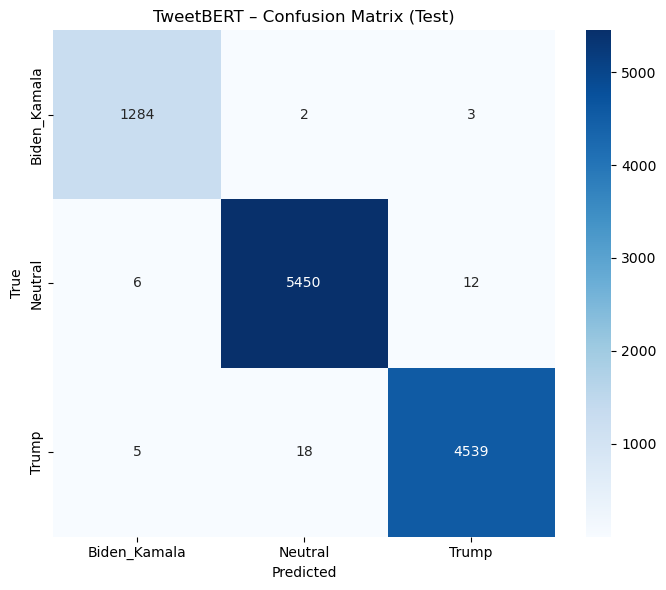

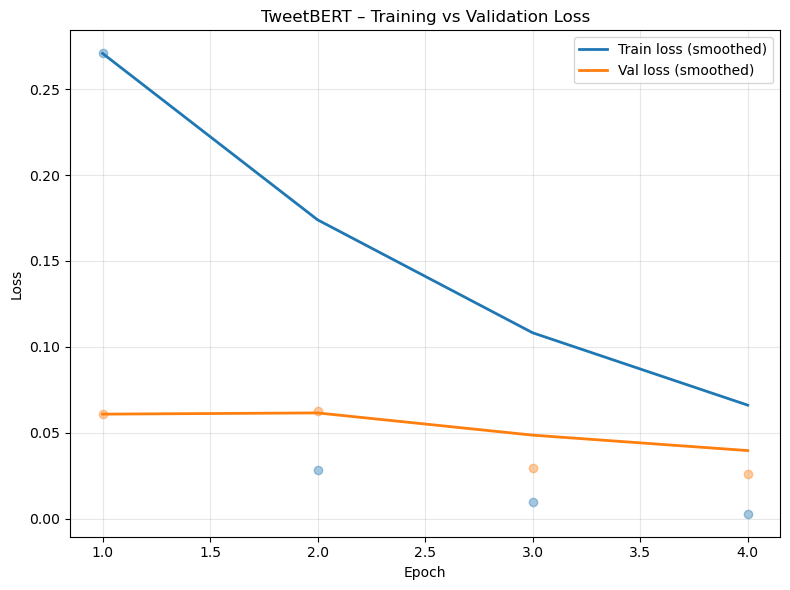

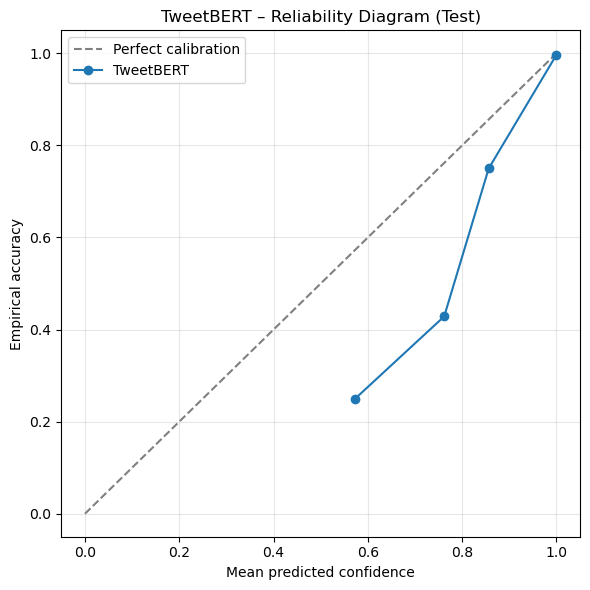


Saved:
 - tweetbert_metrics.csv
 - tweetbert_confusion_matrix.png
 - tweetbert_learning_curve.png
 - tweetbert_reliability_diagram.png
 - tweetbert_test_classification_report.txt


In [ ]:
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix,
    roc_auc_score,
)
from sklearn.preprocessing import label_binarize

# ==========================================
# 1. EVALUATION HELPER FOR A DATALOADER
# ==========================================
def evaluate_loader(model, loader, device, label_encoder):
    """
    Runs model on a loader and returns:
      - int labels
      - predicted labels
      - probabilities
      - string labels (true/pred)
      - basic metrics dict (acc, F1s)
    """
    model.eval()

    all_true_int = []
    all_pred_int = []
    all_probs = []

    with torch.no_grad():
        for batch in loader:
            labels = batch["labels"].numpy()  # integer labels (0..C-1)
            batch = {k: v.to(device) for k, v in batch.items() if k != "labels"}

            outputs = model(**batch)
            logits = outputs.logits  # (B, C)

            preds = logits.argmax(dim=-1).cpu().numpy()
            probs = F.softmax(logits, dim=-1).cpu().numpy()

            all_true_int.extend(labels)
            all_pred_int.extend(preds)
            all_probs.append(probs)

    y_true_int = np.array(all_true_int)
    y_pred_int = np.array(all_pred_int)
    probs = np.vstack(all_probs)

    y_true_str = label_encoder.inverse_transform(y_true_int)
    y_pred_str = label_encoder.inverse_transform(y_pred_int)

    acc = accuracy_score(y_true_str, y_pred_str)

    prec_micro, rec_micro, f1_micro, _ = precision_recall_fscore_support(
        y_true_str, y_pred_str, average="micro", zero_division=0
    )
    prec_macro, rec_macro, f1_macro, _ = precision_recall_fscore_support(
        y_true_str, y_pred_str, average="macro", zero_division=0
    )
    prec_weighted, rec_weighted, f1_weighted, _ = precision_recall_fscore_support(
        y_true_str, y_pred_str, average="weighted", zero_division=0
    )

    metrics = {
        "accuracy": acc,
        "precision_micro": prec_micro,
        "recall_micro": rec_micro,
        "f1_micro": f1_micro,
        "precision_macro": prec_macro,
        "recall_macro": rec_macro,
        "f1_macro": f1_macro,
        "precision_weighted": prec_weighted,
        "recall_weighted": rec_weighted,
        "f1_weighted": f1_weighted,
    }

    return (
        y_true_int,
        y_pred_int,
        probs,
        y_true_str,
        y_pred_str,
        metrics,
    )


# ==========================================
# 2. RUN ON VALIDATION AND TEST
# ==========================================
class_names = list(label_encoder.classes_)
num_classes = len(class_names)
print("Classes:", class_names)

# ----- VALIDATION -----
(
    val_true_int,
    val_pred_int,
    val_probs,
    val_true_str,
    val_pred_str,
    val_metrics,
) = evaluate_loader(bert_model, val_loader, device, label_encoder)

print("\n=== VALIDATION METRICS (TweetBERT) ===")
print("Val accuracy     :", val_metrics["accuracy"])
print("Val F1 (macro)   :", val_metrics["f1_macro"])
print("Val F1 (weighted):", val_metrics["f1_weighted"])
print("\nValidation classification report:\n")
print(classification_report(val_true_str, val_pred_str, zero_division=0))

# ----- TEST -----
(
    test_true_int,
    test_pred_int,
    test_probs,
    test_true_str,
    test_pred_str,
    test_metrics,
) = evaluate_loader(bert_model, test_loader, device, label_encoder)

print("\n=== TEST METRICS (TweetBERT) ===")
print("Test accuracy     :", test_metrics["accuracy"])
print("Test F1 (macro)   :", test_metrics["f1_macro"])
print("Test F1 (weighted):", test_metrics["f1_weighted"])
print("\nTest classification report:\n")
test_report_str = classification_report(
    test_true_str, test_pred_str, target_names=class_names, zero_division=0
)
print(test_report_str)

# ==========================================
# 3. CONFUSION MATRIX (TEST)
# ==========================================
cm = confusion_matrix(test_true_str, test_pred_str, labels=class_names)

plt.figure(figsize=(7, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names,
)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("TweetBERT – Confusion Matrix (Test)")
plt.tight_layout()
plt.savefig("tweetbert_confusion_matrix.png", dpi=300)
plt.show()

# ==========================================
# 4. ROC–AUC (TEST, ONE-VS-REST + MACRO)
# ==========================================
y_true_onehot = label_binarize(test_true_int, classes=np.arange(num_classes))

roc_auc_macro_ovr = roc_auc_score(
    y_true_onehot, test_probs, average="macro", multi_class="ovr"
)
roc_auc_per_class = roc_auc_score(
    y_true_onehot, test_probs, average=None, multi_class="ovr"
)
roc_auc_per_class_dict = {
    class_names[i]: float(roc_auc_per_class[i]) for i in range(num_classes)
}

# ==========================================
# 5. CROSS-ENTROPY + PERPLEXITY (TEST)
# ==========================================
eps = 1e-12
true_class_probs = test_probs[np.arange(len(test_true_int)), test_true_int]
cross_entropy = -np.mean(np.log(true_class_probs + eps))
perplexity = float(np.exp(cross_entropy))

# ==========================================
# 6. ECE (EXPECTED CALIBRATION ERROR, TEST)
# ==========================================
def compute_ece(probs, labels, n_bins=10):
    confidences = np.max(probs, axis=1)
    predictions = np.argmax(probs, axis=1)
    accuracies = (predictions == labels).astype(float)

    bin_boundaries = np.linspace(0.0, 1.0, n_bins + 1)
    ece = 0.0

    for i in range(n_bins):
        start = bin_boundaries[i]
        end = bin_boundaries[i + 1]

        in_bin = (confidences >= start) & (confidences < end)
        prop_in_bin = np.mean(in_bin)
        if prop_in_bin == 0:
            continue

        bin_acc = np.mean(accuracies[in_bin])
        bin_conf = np.mean(confidences[in_bin])

        ece += np.abs(bin_conf - bin_acc) * prop_in_bin

    return float(ece)


ece_10bins = compute_ece(test_probs, test_true_int, n_bins=10)

# ==========================================
# 7. BRIER SCORE (MULTI-CLASS, TEST)
# ==========================================
brier_score = float(np.mean(np.sum((test_probs - y_true_onehot) ** 2, axis=1)))

# ==========================================
# 8. TOP-K ACCURACY (TEST)
# ==========================================
def top_k_accuracy(probs, labels, k=2):
    topk = np.argsort(probs, axis=1)[:, -k:]
    correct = [labels[i] in topk[i] for i in range(len(labels))]
    return float(np.mean(correct))


top2_acc = top_k_accuracy(test_probs, test_true_int, k=2)
top3_acc = top_k_accuracy(test_probs, test_true_int, k=3)

# ==========================================
# 9. LEARNING CURVE (TRAIN + VAL LOSSES)
# ==========================================
def smooth(values, weight=0.6):
    smoothed = []
    last = values[0]
    for v in values:
        val = last * weight + (1 - weight) * v
        smoothed.append(val)
        last = val
    return smoothed


epochs = np.arange(1, len(train_losses) + 1)
train_s = smooth(train_losses)
val_s = smooth(val_losses)

plt.figure(figsize=(8, 6))
plt.plot(epochs, train_s, label="Train loss (smoothed)", linewidth=2)
plt.plot(epochs, val_s, label="Val loss (smoothed)", linewidth=2)
plt.scatter(epochs, train_losses, alpha=0.4)
plt.scatter(epochs, val_losses, alpha=0.4)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("TweetBERT – Training vs Validation Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("tweetbert_learning_curve.png", dpi=300)
plt.show()

# ==========================================
# 10. RELIABILITY DIAGRAM (CALIBRATION, TEST)
# ==========================================
confidences = np.max(test_probs, axis=1)
preds_test = np.argmax(test_probs, axis=1)
accuracies_test = (preds_test == test_true_int).astype(float)

n_bins = 10
bin_boundaries = np.linspace(0.0, 1.0, n_bins + 1)
bin_confs = []
bin_accs = []

for i in range(n_bins):
    start = bin_boundaries[i]
    end = bin_boundaries[i + 1]
    in_bin = (confidences >= start) & (confidences < end)
    if np.sum(in_bin) == 0:
        continue
    bin_confs.append(np.mean(confidences[in_bin]))
    bin_accs.append(np.mean(accuracies_test[in_bin]))

plt.figure(figsize=(6, 6))
plt.plot([0, 1], [0, 1], "--", color="gray", label="Perfect calibration")
plt.plot(bin_confs, bin_accs, marker="o", label="TweetBERT")
plt.xlabel("Mean predicted confidence")
plt.ylabel("Empirical accuracy")
plt.title("TweetBERT – Reliability Diagram (Test)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("tweetbert_reliability_diagram.png", dpi=300)
plt.show()

# ==========================================
# 11. COMBINE & SAVE METRICS
# ==========================================
metrics = {
    # VALIDATION
    "val_accuracy": val_metrics["accuracy"],
    "val_precision_micro": val_metrics["precision_micro"],
    "val_recall_micro": val_metrics["recall_micro"],
    "val_f1_micro": val_metrics["f1_micro"],
    "val_precision_macro": val_metrics["precision_macro"],
    "val_recall_macro": val_metrics["recall_macro"],
    "val_f1_macro": val_metrics["f1_macro"],
    "val_precision_weighted": val_metrics["precision_weighted"],
    "val_recall_weighted": val_metrics["recall_weighted"],
    "val_f1_weighted": val_metrics["f1_weighted"],

    # TEST
    "test_accuracy": test_metrics["accuracy"],
    "test_precision_micro": test_metrics["precision_micro"],
    "test_recall_micro": test_metrics["recall_micro"],
    "test_f1_micro": test_metrics["f1_micro"],
    "test_precision_macro": test_metrics["precision_macro"],
    "test_recall_macro": test_metrics["recall_macro"],
    "test_f1_macro": test_metrics["f1_macro"],
    "test_precision_weighted": test_metrics["precision_weighted"],
    "test_recall_weighted": test_metrics["recall_weighted"],
    "test_f1_weighted": test_metrics["f1_weighted"],

    # TEST advanced
    "roc_auc_macro_ovr": float(roc_auc_macro_ovr),
    "cross_entropy": float(cross_entropy),
    "perplexity": float(perplexity),
    "ece_10bins": float(ece_10bins),
    "brier_score": float(brier_score),
    "top2_accuracy": float(top2_acc),
    "top3_accuracy": float(top3_acc),
}

# add per-class AUCs
for cname, auc_val in roc_auc_per_class_dict.items():
    metrics[f"roc_auc_{cname}"] = float(auc_val)

metrics_df = pd.DataFrame([metrics])
metrics_df.to_csv("tweetbert_metrics.csv", index=False)

with open("tweetbert_test_classification_report.txt", "w", encoding="utf-8") as f:
    f.write(test_report_str)

print("\nSaved:")
print(" - tweetbert_metrics.csv")
print(" - tweetbert_confusion_matrix.png")
print(" - tweetbert_learning_curve.png")
print(" - tweetbert_reliability_diagram.png")
print(" - tweetbert_test_classification_report.txt")


Build more advance MLP


Build TF-IDF + SVD features for PyTorch

PyTorch Dataset + DataLoaders

Advanced MLP for Text (based on your AdvancedNN)

Trainer + EarlyStopping (adapted from your tutorial)

Train the Advanced MLP on your tweet features

Evaluate on test set

better advance MLP


Build TF-IDF + SVD Features (Small, Dense Input)

Dataset + Dataloaders

Better Advanced MLP (small, with BN + Dropout + skip)

Trainer with AdamW, LR scheduler & early stopping on macro-F1

Train and Evaluate the Better Advanced MLP

Chnage the TI-IDF to another for MLP

SBERT (MiniLM) + Advanced MLP

In [ ]:
# --- ENVIRONMENT FIX: make Transformers + SentenceTransformers happy with Keras 3 ---
!pip install -q tf-keras
!pip install -q "sentence-transformers==2.6.1"

# Now imports should work without the Keras 3 error
from sentence_transformers import SentenceTransformer
import numpy as np
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, f1_score, classification_report
import matplotlib.pyplot as plt
from tqdm import tqdm


In [ ]:
# 1) Load a small SBERT model (no BERTweet)
sbert_model = SentenceTransformer("paraphrase-MiniLM-L6-v2")

# 2) Encode your texts (balanced train, val, test)
X_train_sbert = sbert_model.encode(
    X_train_bal.tolist(), show_progress_bar=True, convert_to_numpy=True
)
X_val_sbert = sbert_model.encode(
    X_val_text.tolist(), show_progress_bar=True, convert_to_numpy=True
)
X_test_sbert = sbert_model.encode(
    X_test_text.tolist(), show_progress_bar=True, convert_to_numpy=True
)

print("SBERT shapes:", X_train_sbert.shape, X_val_sbert.shape, X_test_sbert.shape)

# 3) Label encoding for 3 classes
le_sbert = LabelEncoder()
y_train_ids = le_sbert.fit_transform(y_train_bal)
y_val_ids   = le_sbert.transform(y_val_true)
y_test_ids  = le_sbert.transform(y_test_true)

num_classes = len(le_sbert.classes_)
print("Classes:", list(le_sbert.classes_))


In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

class EmbeddingDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.long)

    def __len__(self):
        return self.X.shape[0]

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

train_dataset = EmbeddingDataset(X_train_sbert, y_train_ids)
val_dataset   = EmbeddingDataset(X_val_sbert,   y_val_ids)
test_dataset  = EmbeddingDataset(X_test_sbert,  y_test_ids)

BATCH_SIZE = 64
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader   = DataLoader(val_dataset,   batch_size=BATCH_SIZE, shuffle=False)
test_loader  = DataLoader(test_dataset,  batch_size=BATCH_SIZE, shuffle=False)


In [ ]:
class AdvancedTextMLP_Small(nn.Module):
    """
    Advanced but compact MLP for SBERT embeddings:
    - Input: dense SBERT vector (e.g., 384-dim)
    - Hidden: 128 -> 64 with BN, Dropout, skip connection
    """
    def __init__(self, input_size, hidden_sizes=[128, 64],
                 num_classes=3, dropout_rate=0.5, activation='gelu'):
        super().__init__()

        # choose activation
        self.activation_fn = self._get_activation(activation)

        # first block
        self.fc1 = nn.Linear(input_size, hidden_sizes[0])
        self.bn1 = nn.BatchNorm1d(hidden_sizes[0])
        self.drop1 = nn.Dropout(dropout_rate)

        # second block + skip
        self.fc2 = nn.Linear(hidden_sizes[0], hidden_sizes[1])
        self.bn2 = nn.BatchNorm1d(hidden_sizes[1])
        self.drop2 = nn.Dropout(dropout_rate)
        self.skip1 = (nn.Identity() if hidden_sizes[0] == hidden_sizes[1]
                      else nn.Linear(hidden_sizes[0], hidden_sizes[1]))

        # output
        self.fc_out = nn.Linear(hidden_sizes[1], num_classes)

        self._initialize_weights()

    def _get_activation(self, activation):
        activations = {
            'relu': nn.ReLU(),
            'leaky_relu': nn.LeakyReLU(0.1),
            'elu': nn.ELU(),
            'gelu': nn.GELU(),
            'tanh': nn.Tanh(),
            'sigmoid': nn.Sigmoid()
        }
        return activations.get(activation, nn.ReLU())

    def _initialize_weights(self):
        for m in self.modules():
            if isinstance(m, nn.Linear):
                nn.init.kaiming_normal_(m.weight, mode='fan_out', nonlinearity='relu')
                if m.bias is not None:
                    nn.init.constant_(m.bias, 0)
            elif isinstance(m, nn.BatchNorm1d):
                nn.init.constant_(m.weight, 1)
                nn.init.constant_(m.bias, 0)

    def forward(self, x):
        x1 = self.fc1(x)
        x1 = self.bn1(x1)
        x1 = self.activation_fn(x1)
        x1 = self.drop1(x1)

        identity = self.skip1(x1)
        x2 = self.fc2(x1)
        x2 = self.bn2(x2)
        x2 = self.activation_fn(x2)
        x2 = x2 + identity
        x2 = self.drop2(x2)

        out = self.fc_out(x2)
        return out


In [ ]:
class MLPTrainer:
    def __init__(self, model, device, lr=5e-4, weight_decay=1e-3, label_smoothing=0.1):
        self.model = model
        self.device = device

        self.criterion = nn.CrossEntropyLoss(label_smoothing=label_smoothing)
        self.optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
        self.scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
            self.optimizer, mode='min', patience=3, factor=0.5
        )

        self.train_losses = []
        self.val_losses = []
        self.train_accs = []
        self.val_accs = []

    def train_epoch(self, loader):
        self.model.train()
        running_loss, correct, total = 0.0, 0, 0

        for X, y in tqdm(loader, desc="Training", leave=False):
            X, y = X.to(self.device), y.to(self.device)
            self.optimizer.zero_grad()

            logits = self.model(X)
            loss = self.criterion(logits, y)
            loss.backward()
            nn.utils.clip_grad_norm_(self.model.parameters(), max_norm=1.0)
            self.optimizer.step()

            running_loss += loss.item()
            _, preds = logits.max(1)
            total += y.size(0)
            correct += preds.eq(y).sum().item()

        return running_loss / len(loader), 100.0 * correct / total

    def evaluate(self, loader):
        self.model.eval()
        running_loss, correct, total = 0.0, 0, 0
        all_y, all_preds = [], []

        with torch.no_grad():
            for X, y in tqdm(loader, desc="Validation", leave=False):
                X, y = X.to(self.device), y.to(self.device)
                logits = self.model(X)
                loss = self.criterion(logits, y)

                running_loss += loss.item()
                _, preds = logits.max(1)
                total += y.size(0)
                correct += preds.eq(y).sum().item()

                all_y.extend(y.cpu().numpy())
                all_preds.extend(preds.cpu().numpy())

        avg_loss = running_loss / len(loader)
        acc = 100.0 * correct / total
        f1 = f1_score(all_y, all_preds, average="macro")
        return avg_loss, acc, f1

    def fit(self, train_loader, val_loader, epochs=40, patience=7):
        best_f1 = 0.0
        best_state = None
        bad_epochs = 0

        for epoch in range(1, epochs + 1):
            print(f"\nEpoch {epoch}/{epochs}")
            print("-" * 40)

            train_loss, train_acc = self.train_epoch(train_loader)
            val_loss, val_acc, val_f1 = self.evaluate(val_loader)

            self.train_losses.append(train_loss)
            self.val_losses.append(val_loss)
            self.train_accs.append(train_acc)
            self.val_accs.append(val_acc)

            self.scheduler.step(val_loss)

            print(f"Train  Loss: {train_loss:.4f}, Train Acc: {train_acc:.2f}%")
            print(f"Val    Loss: {val_loss:.4f}, Val Acc: {val_acc:.2f}%, Val F1: {val_f1:.4f}")
            print(f"LR: {self.optimizer.param_groups[0]['lr']:.6f}")

            if val_f1 > best_f1 + 1e-4:
                best_f1 = val_f1
                bad_epochs = 0
                best_state = {k: v.cpu().clone() for k, v in self.model.state_dict().items()}
                print(f"✓ New best model (Val F1 = {best_f1:.4f})")
            else:
                bad_epochs += 1
                print(f"No improvement. Bad epochs: {bad_epochs}/{patience}")
                if bad_epochs >= patience:
                    print("Early stopping triggered.")
                    break

        if best_state is not None:
            self.model.load_state_dict(best_state)

        return self.train_losses, self.val_losses, self.train_accs, self.val_accs

    def plot_history(self):
        fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

        ax1.plot(self.train_losses, label="Train Loss")
        ax1.plot(self.val_losses,   label="Val Loss")
        ax1.set_xlabel("Epoch")
        ax1.set_ylabel("Loss")
        ax1.set_title("Training vs Validation Loss")
        ax1.legend()
        ax1.grid(alpha=0.3)

        ax2.plot(self.train_accs, label="Train Acc")
        ax2.plot(self.val_accs,   label="Val Acc")
        ax2.set_xlabel("Epoch")
        ax2.set_ylabel("Accuracy (%)")
        ax2.set_title("Training vs Validation Accuracy")
        ax2.legend()
        ax2.grid(alpha=0.3)

        plt.tight_layout()
        plt.show()


In [ ]:
input_dim = X_train_sbert.shape[1]  # usually 384 for MiniLM

advanced_mlp_sbert = AdvancedTextMLP_Small(
    input_size=input_dim,
    hidden_sizes=[128, 64],
    num_classes=num_classes,
    dropout_rate=0.5,
    activation='gelu'
).to(device)

trainer_sbert = MLPTrainer(
    model=advanced_mlp_sbert,
    device=device,
    lr=5e-4,
    weight_decay=1e-3,
    label_smoothing=0.1
)

train_losses, val_losses, train_accs, val_accs = trainer_sbert.fit(
    train_loader, val_loader,
    epochs=40,
    patience=7
)

trainer_sbert.plot_history()

# ---- Final test evaluation ----
advanced_mlp_sbert.eval()
all_y, all_pred = [], []

with torch.no_grad():
    for X, y in test_loader:
        X, y = X.to(device), y.to(device)
        logits = advanced_mlp_sbert(X)
        _, preds = logits.max(1)
        all_y.extend(y.cpu().numpy())
        all_pred.extend(preds.cpu().numpy())

test_acc = accuracy_score(all_y, all_pred) * 100
test_f1  = f1_score(all_y, all_pred, average="macro")

print("\n=== Advanced MLP + SBERT ===")
print(f"Test Accuracy: {test_acc:.2f}%")
print(f"Test F1 (macro): {test_f1:.4f}")
print("\nClassification report:")
print(classification_report(all_y, all_pred,
                            target_names=list(le_sbert.classes_),
                            zero_division=0))


Full model MLP + SBERT

Loading SBERT model...
Encoding training data...


Batches:   0%|          | 0/1641 [00:00<?, ?it/s]

Encoding validation data...


Batches:   0%|          | 0/283 [00:00<?, ?it/s]

Encoding test data...


...

Validation:   0%|          | 0/71 [00:00<?, ?it/s]

Train Loss: 0.3878 | Acc: 96.81%
Val   Loss: 0.5173 | Acc: 88.28% | F1: 0.8481
No improvement. Bad epochs: 6/7

Epoch 33/40


Training:   0%|          | 0/411 [00:00<?, ?it/s]

Validation:   0%|          | 0/71 [00:00<?, ?it/s]

Train Loss: 0.3842 | Acc: 96.94%
Val   Loss: 0.5192 | Acc: 88.42% | F1: 0.8498
No improvement. Bad epochs: 7/7
Early stopping triggered.


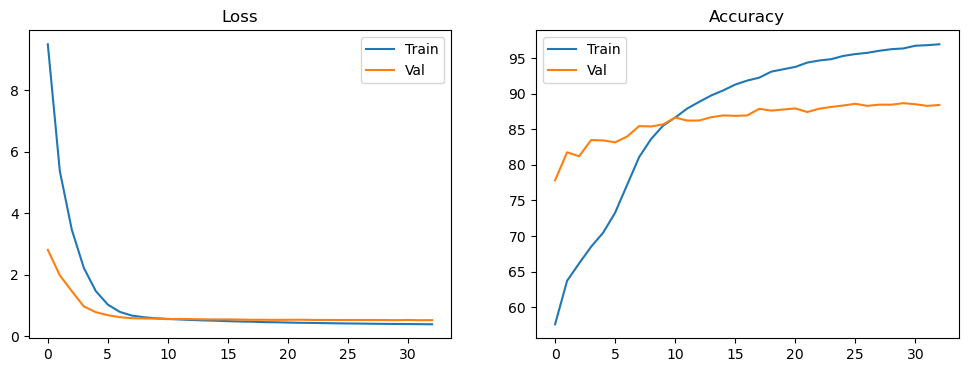


=== Advanced MLP + SBERT (mpnet) ===
Test Accuracy: 88.08%
Test F1 (macro): 0.8502

Classification report:
              precision    recall  f1-score   support

Biden_Kamala       0.73      0.79      0.76      1289
     Neutral       0.88      0.93      0.90      5468
       Trump       0.93      0.85      0.89      4562

    accuracy                           0.88     11319
   macro avg       0.85      0.85      0.85     11319
weighted avg       0.88      0.88      0.88     11319



In [ ]:
# --- ENVIRONMENT SETUP ---
# !pip install -q tf-keras
# !pip install -q "sentence-transformers==2.6.1"

from sentence_transformers import SentenceTransformer
import numpy as np
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, f1_score, classification_report
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

# 1) Load the BEST SBERT model (Better than MiniLM)
print("Loading SBERT model...")
sbert_model = SentenceTransformer("all-mpnet-base-v2")

# 2) Encode your texts (balanced train, val, test)
print("Encoding training data...")
X_train_sbert = sbert_model.encode(
    X_train_bal.tolist(), show_progress_bar=True, convert_to_numpy=True
)
print("Encoding validation data...")
X_val_sbert = sbert_model.encode(
    X_val_text.tolist(), show_progress_bar=True, convert_to_numpy=True
)
print("Encoding test data...")
X_test_sbert = sbert_model.encode(
    X_test_text.tolist(), show_progress_bar=True, convert_to_numpy=True
)

print("SBERT shapes:", X_train_sbert.shape, X_val_sbert.shape, X_test_sbert.shape)

# 3) Label encoding for 3 classes
le_sbert = LabelEncoder()
y_train_ids = le_sbert.fit_transform(y_train_bal)
y_val_ids   = le_sbert.transform(y_val_true)
y_test_ids  = le_sbert.transform(y_test_true)

num_classes = len(le_sbert.classes_)
print("Classes:", list(le_sbert.classes_))

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

# 4) Calculate Class Weights (To handle imbalance)
class_counts = np.bincount(y_train_ids)
total_samples = len(y_train_ids)
# Formula: Total / (num_classes * count)
class_weights = torch.tensor([total_samples / (num_classes * c) for c in class_counts], dtype=torch.float32).to(device)
print("Class Weights:", class_weights)

class EmbeddingDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.long)

    def __len__(self):
        return self.X.shape[0]

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

train_dataset = EmbeddingDataset(X_train_sbert, y_train_ids)
val_dataset   = EmbeddingDataset(X_val_sbert,   y_val_ids)
test_dataset  = EmbeddingDataset(X_test_sbert,  y_test_ids)

BATCH_SIZE = 128
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader   = DataLoader(val_dataset,   batch_size=BATCH_SIZE, shuffle=False)
test_loader  = DataLoader(test_dataset,  batch_size=BATCH_SIZE, shuffle=False)


class AdvancedTextMLP(nn.Module):
    """
    Advanced MLP for SBERT embeddings:
    - Input: dense SBERT vector (768 for mpnet-base)
    - Hidden: 256 -> 128 with BN, Dropout, skip connection
    """
    def __init__(self, input_size, hidden_sizes=[256, 128],
                 num_classes=3, dropout_rate=0.5, activation='gelu'):
        super().__init__()

        self.activation_fn = nn.GELU()

        # Block 1
        self.fc1 = nn.Linear(input_size, hidden_sizes[0])
        self.bn1 = nn.BatchNorm1d(hidden_sizes[0])
        self.drop1 = nn.Dropout(dropout_rate)

        # Block 2 + Skip Connection
        self.fc2 = nn.Linear(hidden_sizes[0], hidden_sizes[1])
        self.bn2 = nn.BatchNorm1d(hidden_sizes[1])
        self.drop2 = nn.Dropout(dropout_rate)

        # Skip connection adapter (if sizes differ)
        self.skip1 = nn.Linear(hidden_sizes[0], hidden_sizes[1])

        # Output
        self.fc_out = nn.Linear(hidden_sizes[1], num_classes)

        self._initialize_weights()

    def _initialize_weights(self):
        for m in self.modules():
            if isinstance(m, nn.Linear):
                nn.init.kaiming_normal_(m.weight, mode='fan_out', nonlinearity='relu')
                if m.bias is not None:
                    nn.init.constant_(m.bias, 0)
            elif isinstance(m, nn.BatchNorm1d):
                nn.init.constant_(m.weight, 1)
                nn.init.constant_(m.bias, 0)

    def forward(self, x):
        # Block 1
        x1 = self.fc1(x)
        x1 = self.bn1(x1)
        x1 = self.activation_fn(x1)
        x1 = self.drop1(x1)

        # Block 2
        x2 = self.fc2(x1)
        x2 = self.bn2(x2)
        x2 = self.activation_fn(x2)

        # Add Skip Connection (x1 transformed to match x2 size)
        identity = self.skip1(x1)
        x2 = x2 + identity

        x2 = self.drop2(x2)

        out = self.fc_out(x2)
        return out


class MLPTrainer:
    def __init__(self, model, device, class_weights=None, lr=5e-4, weight_decay=1e-3, label_smoothing=0.1):
        self.model = model
        self.device = device

        # Use class weights here
        self.criterion = nn.CrossEntropyLoss(weight=class_weights, label_smoothing=label_smoothing)

        self.optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
        self.scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
            self.optimizer, mode='min', patience=3, factor=0.5
        )

        self.train_losses = []
        self.val_losses = []
        self.train_accs = []
        self.val_accs = []

    def train_epoch(self, loader):
        self.model.train()
        running_loss, correct, total = 0.0, 0, 0

        for X, y in tqdm(loader, desc="Training", leave=False):
            X, y = X.to(self.device), y.to(self.device)
            self.optimizer.zero_grad()

            logits = self.model(X)
            loss = self.criterion(logits, y)
            loss.backward()
            nn.utils.clip_grad_norm_(self.model.parameters(), max_norm=1.0)
            self.optimizer.step()

            running_loss += loss.item()
            _, preds = logits.max(1)
            total += y.size(0)
            correct += preds.eq(y).sum().item()

        return running_loss / len(loader), 100.0 * correct / total

    def evaluate(self, loader):
        self.model.eval()
        running_loss, correct, total = 0.0, 0, 0
        all_y, all_preds = [], []

        with torch.no_grad():
            for X, y in tqdm(loader, desc="Validation", leave=False):
                X, y = X.to(self.device), y.to(self.device)
                logits = self.model(X)
                loss = self.criterion(logits, y)

                running_loss += loss.item()
                _, preds = logits.max(1)
                total += y.size(0)
                correct += preds.eq(y).sum().item()

                all_y.extend(y.cpu().numpy())
                all_preds.extend(preds.cpu().numpy())

        avg_loss = running_loss / len(loader)
        acc = 100.0 * correct / total
        f1 = f1_score(all_y, all_preds, average="macro")
        return avg_loss, acc, f1

    def fit(self, train_loader, val_loader, epochs=40, patience=7):
        best_f1 = 0.0
        best_state = None
        bad_epochs = 0

        for epoch in range(1, epochs + 1):
            print(f"\nEpoch {epoch}/{epochs}")

            train_loss, train_acc = self.train_epoch(train_loader)
            val_loss, val_acc, val_f1 = self.evaluate(val_loader)

            self.train_losses.append(train_loss)
            self.val_losses.append(val_loss)
            self.train_accs.append(train_acc)
            self.val_accs.append(val_acc)

            self.scheduler.step(val_loss)

            print(f"Train Loss: {train_loss:.4f} | Acc: {train_acc:.2f}%")
            print(f"Val   Loss: {val_loss:.4f} | Acc: {val_acc:.2f}% | F1: {val_f1:.4f}")

            if val_f1 > best_f1 + 1e-4:
                best_f1 = val_f1
                bad_epochs = 0
                best_state = {k: v.cpu().clone() for k, v in self.model.state_dict().items()}

                # Save to disk immediately
                torch.save(best_state, "sbert_mlp_model.pth")
                print(f"✓ New best model saved (Val F1 = {best_f1:.4f})")
            else:
                bad_epochs += 1
                print(f"No improvement. Bad epochs: {bad_epochs}/{patience}")
                if bad_epochs >= patience:
                    print("Early stopping triggered.")
                    break

        if best_state is not None:
            self.model.load_state_dict(best_state)

        return self.train_losses, self.val_losses, self.train_accs, self.val_accs

    def plot_history(self):
        fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
        ax1.plot(self.train_losses, label="Train")
        ax1.plot(self.val_losses,   label="Val")
        ax1.set_title("Loss")
        ax1.legend()

        ax2.plot(self.train_accs, label="Train")
        ax2.plot(self.val_accs,   label="Val")
        ax2.set_title("Accuracy")
        ax2.legend()
        plt.show()

# ---- RUNNING IT ----
input_dim = X_train_sbert.shape[1]  # 768 for mpnet-base

advanced_mlp_sbert = AdvancedTextMLP(
    input_size=input_dim,
    hidden_sizes=[256, 128], # Increased size for larger embeddings
    num_classes=num_classes,
    dropout_rate=0.5
).to(device)

trainer_sbert = MLPTrainer(
    model=advanced_mlp_sbert,
    device=device,
    class_weights=class_weights, # Pass weights here
    lr=5e-4,
    weight_decay=1e-3
)

train_losses, val_losses, train_accs, val_accs = trainer_sbert.fit(
    train_loader, val_loader,
    epochs=40,
    patience=7
)

trainer_sbert.plot_history()

# ---- Final test evaluation ----
advanced_mlp_sbert.eval()
all_y, all_pred = [], []

with torch.no_grad():
    for X, y in test_loader:
        X, y = X.to(device), y.to(device)
        logits = advanced_mlp_sbert(X)
        _, preds = logits.max(1)
        all_y.extend(y.cpu().numpy())
        all_pred.extend(preds.cpu().numpy())

test_acc = accuracy_score(all_y, all_pred) * 100
test_f1  = f1_score(all_y, all_pred, average="macro")

print("\n=== Advanced MLP + SBERT (mpnet) ===")
print(f"Test Accuracy: {test_acc:.2f}%")
print(f"Test F1 (macro): {test_f1:.4f}")
print("\nClassification report:")
print(classification_report(all_y, all_pred,
                            target_names=list(le_sbert.classes_),
                            zero_division=0))


In [ ]:
import torch
import pickle
import os

save_dir = "sbert_mlp_model"
os.makedirs(save_dir, exist_ok=True)

# 1. Save MLP classifier (state_dict)
torch.save(advanced_mlp_sbert.state_dict(), f"{save_dir}/mlp_classifier.pth")
print("✓ Saved MLP classifier.")

# 2. Save label encoder
with open(f"{save_dir}/label_encoder.pkl", "wb") as f:
    pickle.dump(le_sbert, f)
print("✓ Saved LabelEncoder.")

# 3. (Optional) Save SBERT name so you know what encoder was used
with open(f"{save_dir}/sbert_encoder_name.txt", "w") as f:
    f.write("all-mpnet-base-v2")
print("✓ Saved SBERT model name.")


✓ Saved MLP classifier.
✓ Saved LabelEncoder.
✓ Saved SBERT model name.



====== EVALUATING ADVANCED MLP + SBERT (all-mpnet-base-v2) ======

VALIDATION METRICS:
{'accuracy': 0.8858089453340696, 'f1_macro': 0.8524986804203548, 'f1_weighted': 0.8861124564519586, 'precision_macro': 0.851161010114796, 'recall_macro': 0.8556847800793124, 'precision_weighted': 0.8884258091440823, 'recall_weighted': 0.8858089453340696}
              precision    recall  f1-score   support

Biden_Kamala       0.73      0.77      0.75      1031
     Neutral       0.89      0.93      0.91      4374
       Trump       0.94      0.86      0.90      3650

    accuracy                           0.89      9055
   macro avg       0.85      0.86      0.85      9055
weighted avg       0.89      0.89      0.89      9055


TEST METRICS:
{'accuracy': 0.8808198604116971, 'f1_macro': 0.8502077071874418, 'f1_weighted': 0.8812061722157835, 'precision_macro': 0.8480814987846066, 'recall_macro': 0.8547616099633278, 'precision_weighted': 0.8840997674076876, 'recall_weighted': 0.8808198604116971}
     

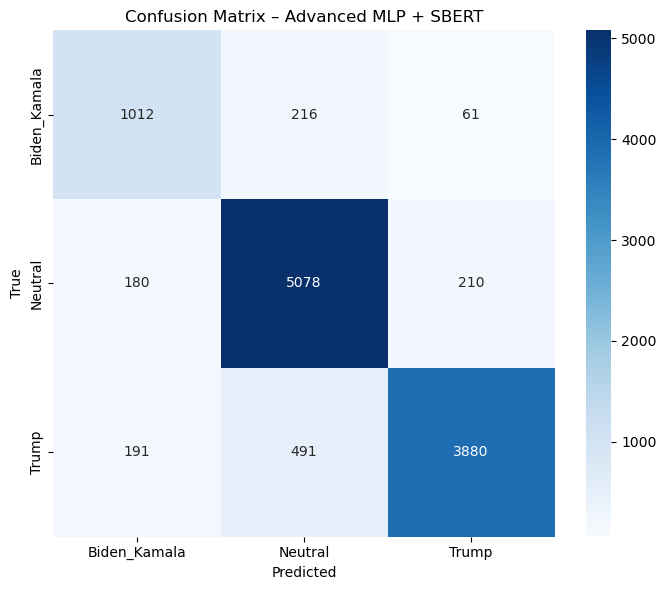

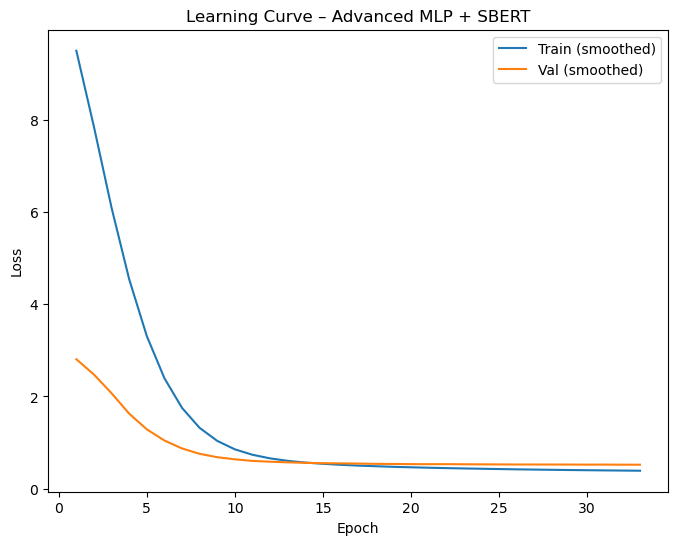

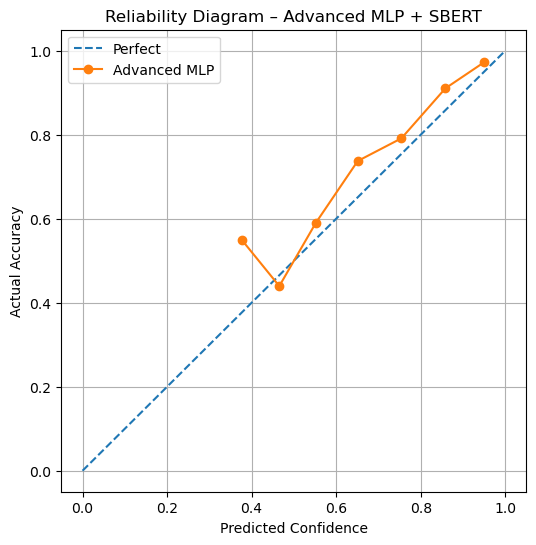


Saved all evaluation files:
 - advanced_mlp_mpnet_cm.png
 - advanced_mlp_mpnet_learning_curve.png
 - advanced_mlp_mpnet_reliability.png
 - advanced_mlp_mpnet_metrics.csv
 - advanced_mlp_mpnet_classification_report.txt


In [ ]:
# ===============================================================
# ============  FULL ADVANCED EVALUATION BLOCK  =================
# ===============================================================

import numpy as np
import pandas as pd
import torch.nn.functional as F
import seaborn as sns
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix,
    roc_auc_score,
)
from sklearn.preprocessing import label_binarize
import matplotlib.pyplot as plt

# ---------------------------------------------------------------
# 1. Helper to Evaluate AdvancedMLP (loader gives X,y)
# ---------------------------------------------------------------
def evaluate_advanced_mlp(model, loader, device, label_encoder):
    model.eval()
    all_true = []
    all_pred = []
    all_probs = []

    with torch.no_grad():
        for X, y in loader:
            X = X.to(device)
            y = y.to(device)

            logits = model(X)
            probs = F.softmax(logits, dim=-1)
            preds = logits.argmax(dim=-1)

            all_true.extend(y.cpu().numpy())
            all_pred.extend(preds.cpu().numpy())
            all_probs.append(probs.cpu().numpy())

    y_true = np.array(all_true)
    y_pred = np.array(all_pred)
    probs  = np.vstack(all_probs)

    y_true_str = label_encoder.inverse_transform(y_true)
    y_pred_str = label_encoder.inverse_transform(y_pred)

    # basic metrics
    acc = accuracy_score(y_true_str, y_pred_str)
    prec_macro, rec_macro, f1_macro, _ = precision_recall_fscore_support(
        y_true_str, y_pred_str, average="macro", zero_division=0
    )
    prec_weighted, rec_weighted, f1_weighted, _ = precision_recall_fscore_support(
        y_true_str, y_pred_str, average="weighted", zero_division=0
    )

    metrics = {
        "accuracy": acc,
        "f1_macro": f1_macro,
        "f1_weighted": f1_weighted,
        "precision_macro": prec_macro,
        "recall_macro": rec_macro,
        "precision_weighted": prec_weighted,
        "recall_weighted": rec_weighted,
    }

    return y_true, y_pred, probs, y_true_str, y_pred_str, metrics


# ---------------------------------------------------------------
# 2. Calibration Helpers (ECE, Top-K, smoothing)
# ---------------------------------------------------------------
def compute_ece(probs, labels, n_bins=10):
    confidences = np.max(probs, axis=1)
    preds = probs.argmax(axis=1)
    correct = (preds == labels).astype(float)
    bins = np.linspace(0, 1, n_bins + 1)

    ece = 0
    for i in range(n_bins):
        mask = (confidences >= bins[i]) & (confidences < bins[i + 1])
        if mask.sum() == 0:
            continue
        acc = correct[mask].mean()
        conf = confidences[mask].mean()
        ece += (mask.mean()) * abs(acc - conf)
    return float(ece)


def top_k_accuracy(probs, labels, k=2):
    topk = np.argsort(probs, axis=1)[:, -k:]
    return float(np.mean([labels[i] in topk[i] for i in range(len(labels))]))


def smooth(values, weight=0.6):
    sm = []
    last = values[0]
    for v in values:
        val = last * weight + (1 - weight) * v
        sm.append(val)
        last = val
    return sm


# ---------------------------------------------------------------
# 3. Run evaluation for this model
# ---------------------------------------------------------------
model_name = "advanced_mlp_mpnet"

class_names = list(le_sbert.classes_)
num_classes = len(class_names)

print("\n====== EVALUATING ADVANCED MLP + SBERT (all-mpnet-base-v2) ======")

# --- VALIDATION ---
(val_y_int, val_pred_int, val_probs,
 val_y_str, val_pred_str, val_metrics) = evaluate_advanced_mlp(
    advanced_mlp_sbert, val_loader, device, le_sbert
)

print("\nVALIDATION METRICS:")
print(val_metrics)
print(classification_report(val_y_str, val_pred_str, zero_division=0))


# --- TEST ---
(test_y_int, test_pred_int, test_probs,
 test_y_str, test_pred_str, test_metrics) = evaluate_advanced_mlp(
    advanced_mlp_sbert, test_loader, device, le_sbert
)

print("\nTEST METRICS:")
print(test_metrics)
report_str = classification_report(
    test_y_str, test_pred_str, target_names=class_names, zero_division=0
)
print(report_str)


# ---------------------------------------------------------------
# 4. Confusion Matrix
# ---------------------------------------------------------------
cm = confusion_matrix(test_y_str, test_pred_str, labels=class_names)

plt.figure(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=class_names, yticklabels=class_names)
plt.title("Confusion Matrix – Advanced MLP + SBERT")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.tight_layout()
plt.savefig(f"{model_name}_cm.png", dpi=300)
plt.show()


# ---------------------------------------------------------------
# 5. ROC–AUC
# ---------------------------------------------------------------
y_true_onehot = label_binarize(test_y_int, classes=np.arange(num_classes))

roc_macro = roc_auc_score(
    y_true_onehot, test_probs, average="macro", multi_class="ovr"
)
roc_perclass = roc_auc_score(
    y_true_onehot, test_probs, average=None, multi_class="ovr"
)

roc_perclass_dict = {
    class_names[i]: float(roc_perclass[i]) for i in range(num_classes)
}


# ---------------------------------------------------------------
# 6. Cross-Entropy + Perplexity
# ---------------------------------------------------------------
eps = 1e-12
p_true = test_probs[np.arange(len(test_y_int)), test_y_int]
cross_entropy = -np.mean(np.log(p_true + eps))
perplexity = float(np.exp(cross_entropy))


# ---------------------------------------------------------------
# 7. ECE + Brier + Top-K
# ---------------------------------------------------------------
ece = compute_ece(test_probs, test_y_int, n_bins=10)
brier = float(np.mean(np.sum((test_probs - y_true_onehot) ** 2, axis=1)))
top2 = top_k_accuracy(test_probs, test_y_int, k=2)
top3 = top_k_accuracy(test_probs, test_y_int, k=3)


# ---------------------------------------------------------------
# 8. Learning Curve
# ---------------------------------------------------------------
epochs_arr = np.arange(1, len(trainer_sbert.train_losses) + 1)
plt.figure(figsize=(8, 6))
plt.plot(epochs_arr, smooth(trainer_sbert.train_losses), label="Train (smoothed)")
plt.plot(epochs_arr, smooth(trainer_sbert.val_losses), label="Val (smoothed)")
plt.title("Learning Curve – Advanced MLP + SBERT")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.savefig(f"{model_name}_learning_curve.png", dpi=300)
plt.show()


# ---------------------------------------------------------------
# 9. Reliability Diagram
# ---------------------------------------------------------------
conf = np.max(test_probs, axis=1)
preds = test_probs.argmax(axis=1)
accs = (preds == test_y_int).astype(float)

bins = np.linspace(0, 1, 11)
bin_conf, bin_acc = [], []

for i in range(10):
    mask = (conf >= bins[i]) & (conf < bins[i+1])
    if mask.sum() == 0:
        continue
    bin_conf.append(conf[mask].mean())
    bin_acc.append(accs[mask].mean())

plt.figure(figsize=(6, 6))
plt.plot([0, 1], [0, 1], "--", label="Perfect")
plt.plot(bin_conf, bin_acc, marker="o", label="Advanced MLP")
plt.xlabel("Predicted Confidence")
plt.ylabel("Actual Accuracy")
plt.title("Reliability Diagram – Advanced MLP + SBERT")
plt.legend()
plt.grid()
plt.savefig(f"{model_name}_reliability.png", dpi=300)
plt.show()


# ---------------------------------------------------------------
# 10. Save all metrics
# ---------------------------------------------------------------
metrics = {
    # Basic
    "test_accuracy": test_metrics["accuracy"],
    "test_f1_macro": test_metrics["f1_macro"],
    "test_f1_weighted": test_metrics["f1_weighted"],

    # ROC
    "roc_macro_ovr": float(roc_macro),
    "cross_entropy": float(cross_entropy),
    "perplexity": float(perplexity),
    "ece_10bins": float(ece),
    "brier_score": float(brier),
    "top2_accuracy": float(top2),
    "top3_accuracy": float(top3),
}

for cname, auc_val in roc_perclass_dict.items():
    metrics[f"roc_auc_{cname}"] = auc_val

df_metrics = pd.DataFrame([metrics])
df_metrics.to_csv(f"{model_name}_metrics.csv", index=False)

with open(f"{model_name}_classification_report.txt", "w") as f:
    f.write(report_str)

print("\nSaved all evaluation files:")
print(f" - {model_name}_cm.png")
print(f" - {model_name}_learning_curve.png")
print(f" - {model_name}_reliability.png")
print(f" - {model_name}_metrics.csv")
print(f" - {model_name}_classification_report.txt")


simple ML v2 Sbert

Using device: cpu
Loading SBERT model: sentence-transformers/all-mpnet-base-v2
Encoding training data...


Batches:   0%|          | 0/1641 [00:00<?, ?it/s]

Encoding validation data...


Batches:   0%|          | 0/283 [00:00<?, ?it/s]

Encoding test data...


...

Val:   0%|          | 0/71 [00:00<?, ?it/s]

Train Loss: 0.0438 | Acc: 98.74%
Val   Loss: 0.4585 | Acc: 87.82% | F1: 0.8434
No F1 improvement. Bad epochs: 6/7

Epoch 32/40


Train:   0%|          | 0/411 [00:00<?, ?it/s]

Val:   0%|          | 0/71 [00:00<?, ?it/s]

Train Loss: 0.0441 | Acc: 98.74%
Val   Loss: 0.4576 | Acc: 87.74% | F1: 0.8429
No F1 improvement. Bad epochs: 7/7
Early stopping triggered. Best epoch was 25 with F1 = 0.8436
Loaded best model from epoch 25 (Val F1 = 0.8436)


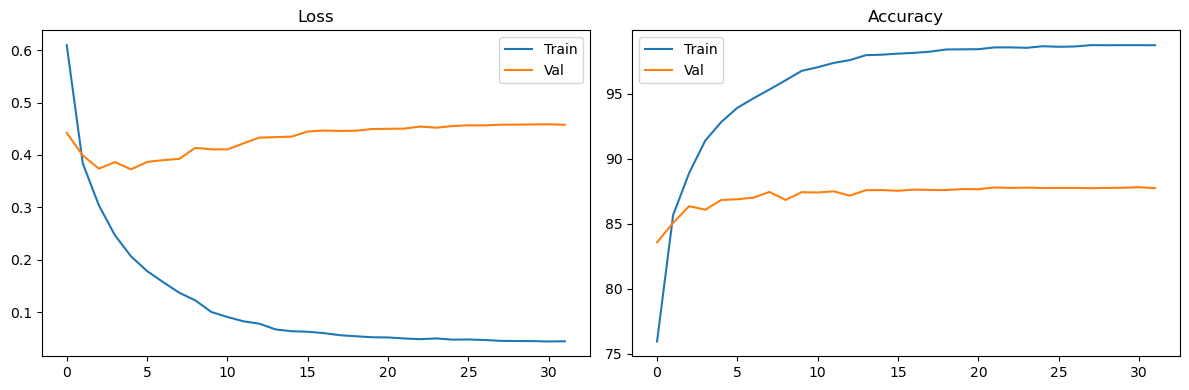

Test:   0%|          | 0/89 [00:00<?, ?it/s]


=== SIMPLE SBERT + MLP ===
Test Accuracy: 87.83%
Test F1 (macro): 0.8471

Classification report:
              precision    recall  f1-score   support

Biden_Kamala       0.75      0.76      0.75      1289
     Neutral       0.88      0.92      0.90      5468
       Trump       0.92      0.86      0.89      4562

    accuracy                           0.88     11319
   macro avg       0.85      0.85      0.85     11319
weighted avg       0.88      0.88      0.88     11319


Saved simple SBERT+MLP model to: sbert_mlp_simple_model


In [ ]:
import os
import numpy as np
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from sentence_transformers import SentenceTransformer
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, f1_score, classification_report
from tqdm.auto import tqdm
import matplotlib.pyplot as plt
import pickle

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

# -----------------------------
# 1. SBERT ENCODER (FROZEN)
# -----------------------------
ENCODER_NAME = "sentence-transformers/all-mpnet-base-v2"
print("Loading SBERT model:", ENCODER_NAME)
sbert_model = SentenceTransformer(ENCODER_NAME)

# Assumes these exist from your previous split:
# X_train_bal, y_train_bal, X_val_text, y_val_true, X_test_text, y_test_true

print("Encoding training data...")
X_train_sbert = sbert_model.encode(
    X_train_bal.tolist(),
    show_progress_bar=True,
    convert_to_numpy=True
)
print("Encoding validation data...")
X_val_sbert = sbert_model.encode(
    X_val_text.tolist(),
    show_progress_bar=True,
    convert_to_numpy=True
)
print("Encoding test data...")
X_test_sbert = sbert_model.encode(
    X_test_text.tolist(),
    show_progress_bar=True,
    convert_to_numpy=True
)

print("SBERT shapes:", X_train_sbert.shape, X_val_sbert.shape, X_test_sbert.shape)

# -----------------------------
# 2. LABEL ENCODING + WEIGHTS
# -----------------------------
le_sbert = LabelEncoder()
y_train_ids = le_sbert.fit_transform(y_train_bal)
y_val_ids   = le_sbert.transform(y_val_true)
y_test_ids  = le_sbert.transform(y_test_true)

num_classes = len(le_sbert.classes_)
print("Classes:", list(le_sbert.classes_))

class_counts = np.bincount(y_train_ids)
total_samples = len(y_train_ids)
class_weights_np = np.array(
    [total_samples / (num_classes * c) for c in class_counts],
    dtype=np.float32
)
class_weights = torch.tensor(class_weights_np, device=device)
print("Class weights:", class_weights)

# -----------------------------
# 3. DATASETS
# -----------------------------
class EmbeddingDataset(Dataset):
    def __init__(self, X, y):
        X = np.asarray(X, dtype=np.float32)
        # Simple L2 norm to stabilize
        norms = np.linalg.norm(X, axis=1, keepdims=True)
        norms = np.clip(norms, 1e-12, None)
        X = X / norms

        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.long)

    def __len__(self):
        return self.X.shape[0]

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

train_dataset = EmbeddingDataset(X_train_sbert, y_train_ids)
val_dataset   = EmbeddingDataset(X_val_sbert,   y_val_ids)
test_dataset  = EmbeddingDataset(X_test_sbert,  y_test_ids)

BATCH_SIZE = 128
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader   = DataLoader(val_dataset,   batch_size=BATCH_SIZE, shuffle=False)
test_loader  = DataLoader(test_dataset,  batch_size=BATCH_SIZE, shuffle=False)

# -----------------------------
# 4. SMALL, STABLE MLP
# -----------------------------
class SimpleSBERTMLP(nn.Module):
    def __init__(self, input_size, hidden=256, num_classes=3, dropout=0.5):
        super().__init__()
        self.ln = nn.LayerNorm(input_size)
        self.fc1 = nn.Linear(input_size, hidden)
        self.act = nn.GELU()
        self.drop = nn.Dropout(dropout)
        self.fc_out = nn.Linear(hidden, num_classes)

        # He init
        nn.init.kaiming_normal_(self.fc1.weight, nonlinearity="relu")
        nn.init.constant_(self.fc1.bias, 0)
        nn.init.xavier_uniform_(self.fc_out.weight)
        nn.init.constant_(self.fc_out.bias, 0)

    def forward(self, x):
        x = self.ln(x)
        x = self.fc1(x)
        x = self.act(x)
        x = self.drop(x)
        out = self.fc_out(x)
        return out

model = SimpleSBERTMLP(
    input_size=X_train_sbert.shape[1],
    hidden=256,
    num_classes=num_classes,
    dropout=0.5
).to(device)

criterion = nn.CrossEntropyLoss(weight=class_weights)
optimizer = torch.optim.AdamW(model.parameters(), lr=5e-4, weight_decay=1e-3)

# Cosine LR or ReduceLROnPlateau both okay; keep it simple:
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode="min", patience=3, factor=0.5
)

# -----------------------------
# 5. TRAIN LOOP WITH EARLY STOP
# -----------------------------
MAX_EPOCHS = 40
PATIENCE   = 7

train_losses, val_losses = [], []
train_accs,  val_accs  = [], []

best_val_f1 = 0.0
best_state  = None
bad_epochs  = 0
best_epoch  = 0

for epoch in range(1, MAX_EPOCHS + 1):
    print(f"\nEpoch {epoch}/{MAX_EPOCHS}")

    # TRAIN
    model.train()
    running_loss, correct, total = 0.0, 0, 0

    for X, y in tqdm(train_loader, desc="Train", leave=False):
        X = X.to(device)
        y = y.to(device)

        optimizer.zero_grad()
        logits = model(X)
        loss = criterion(logits, y)
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()

        running_loss += loss.item()
        _, preds = logits.max(1)
        total += y.size(0)
        correct += preds.eq(y).sum().item()

    train_loss = running_loss / len(train_loader)
    train_acc  = 100.0 * correct / total

    # VAL
    model.eval()
    val_running_loss, val_correct, val_total = 0.0, 0, 0
    all_val_y, all_val_pred = [], []

    with torch.no_grad():
        for X, y in tqdm(val_loader, desc="Val", leave=False):
            X = X.to(device)
            y = y.to(device)

            logits = model(X)
            loss = criterion(logits, y)

            val_running_loss += loss.item()
            _, preds = logits.max(1)
            val_total += y.size(0)
            val_correct += preds.eq(y).sum().item()

            all_val_y.extend(y.cpu().numpy())
            all_val_pred.extend(preds.cpu().numpy())

    val_loss = val_running_loss / len(val_loader)
    val_acc  = 100.0 * val_correct / val_total
    val_f1   = f1_score(all_val_y, all_val_pred, average="macro")

    train_losses.append(train_loss)
    val_losses.append(val_loss)
    train_accs.append(train_acc)
    val_accs.append(val_acc)

    scheduler.step(val_loss)

    print(f"Train Loss: {train_loss:.4f} | Acc: {train_acc:.2f}%")
    print(f"Val   Loss: {val_loss:.4f} | Acc: {val_acc:.2f}% | F1: {val_f1:.4f}")

    # Early stopping on F1
    if val_f1 > best_val_f1 + 1e-4:
        best_val_f1 = val_f1
        best_epoch  = epoch
        bad_epochs  = 0
        best_state  = {k: v.cpu().clone() for k, v in model.state_dict().items()}
        torch.save(best_state, "sbert_mlp_simple_best.pth")
        print(f"✓ New best model saved (Val F1 = {best_val_f1:.4f} at epoch {epoch})")
    else:
        bad_epochs += 1
        print(f"No F1 improvement. Bad epochs: {bad_epochs}/{PATIENCE}")
        if bad_epochs >= PATIENCE:
            print(f"Early stopping triggered. Best epoch was {best_epoch} with F1 = {best_val_f1:.4f}")
            break

if best_state is not None:
    model.load_state_dict(best_state)
    model.to(device)
    print(f"Loaded best model from epoch {best_epoch} (Val F1 = {best_val_f1:.4f})")

# -----------------------------
# 6. PLOT HISTORY
# -----------------------------
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.plot(train_losses, label="Train")
ax1.plot(val_losses,   label="Val")
ax1.set_title("Loss")
ax1.legend()

ax2.plot(train_accs, label="Train")
ax2.plot(val_accs,   label="Val")
ax2.set_title("Accuracy")
ax2.legend()
plt.tight_layout()
plt.show()

# -----------------------------
# 7. TEST EVALUATION
# -----------------------------
model.eval()
all_y_test, all_pred_test = [], []

with torch.no_grad():
    for X, y in tqdm(test_loader, desc="Test", leave=False):
        X = X.to(device)
        y = y.to(device)
        logits = model(X)
        _, preds = logits.max(1)
        all_y_test.extend(y.cpu().numpy())
        all_pred_test.extend(preds.cpu().numpy())

test_acc = accuracy_score(all_y_test, all_pred_test) * 100
test_f1  = f1_score(all_y_test, all_pred_test, average="macro")

print("\n=== SIMPLE SBERT + MLP ===")
print(f"Test Accuracy: {test_acc:.2f}%")
print(f"Test F1 (macro): {test_f1:.4f}")
print("\nClassification report:")
print(
    classification_report(
        all_y_test,
        all_pred_test,
        target_names=list(le_sbert.classes_),
        zero_division=0
    )
)

# -----------------------------
# 8. SAVE MODEL + ENCODER INFO
# -----------------------------
save_dir = "sbert_mlp_simple_model"
os.makedirs(save_dir, exist_ok=True)

torch.save(model.state_dict(), f"{save_dir}/mlp_classifier.pth")

with open(f"{save_dir}/label_encoder.pkl", "wb") as f:
    pickle.dump(le_sbert, f)

with open(f"{save_dir}/sbert_encoder_name.txt", "w") as f:
    f.write(ENCODER_NAME)

print("\nSaved simple SBERT+MLP model to:", save_dir)



===== Evaluating SIMPLE SBERT + MLP =====
Classes: ['Biden_Kamala', 'Neutral', 'Trump']

=== VALIDATION METRICS (sbert_mlp_simple) ===
Val accuracy     : 0.8775262286029818
Val F1 (macro)   : 0.8435649945018052
Val F1 (weighted): 0.8774292425552532

Validation classification report:

              precision    recall  f1-score   support

Biden_Kamala       0.74      0.74      0.74      1031
     Neutral       0.88      0.92      0.90      4374
       Trump       0.92      0.86      0.89      3650

    accuracy                           0.88      9055
   macro avg       0.85      0.84      0.84      9055
weighted avg       0.88      0.88      0.88      9055


=== TEST METRICS (sbert_mlp_simple) ===
Test accuracy     : 0.8783461436522662
Test F1 (macro)   : 0.8471234705549743
Test F1 (weighted): 0.8783181488952296

Test classification report:

              precision    recall  f1-score   support

Biden_Kamala       0.75      0.76      0.75      1289
     Neutral       0.88      0.92   

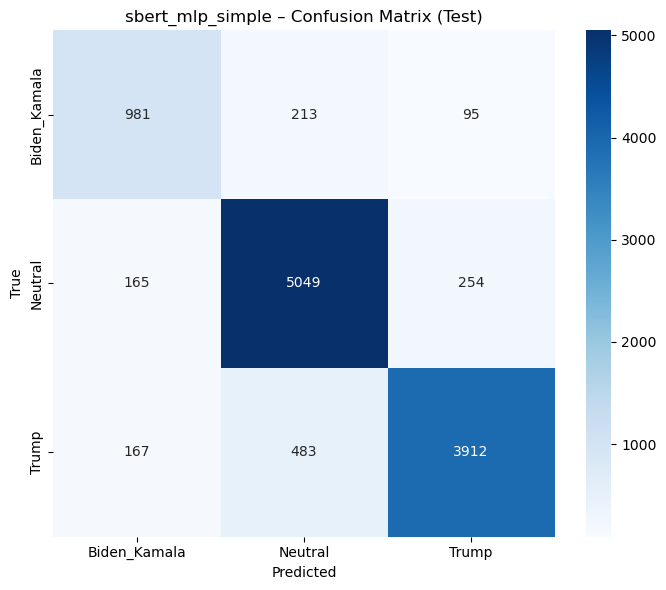

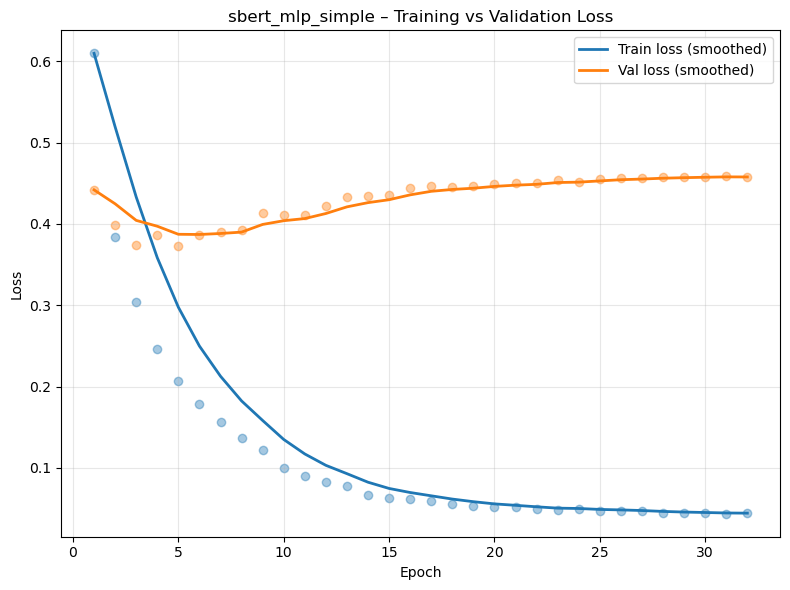

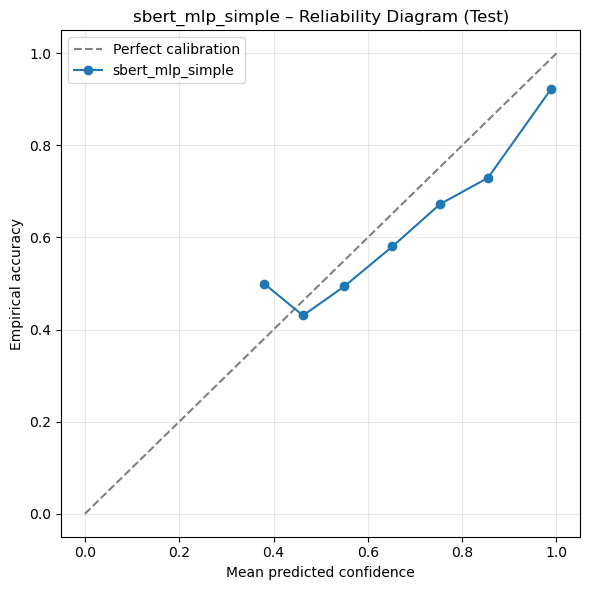


Saved:
 - sbert_mlp_simple_metrics.csv
 - sbert_mlp_simple_confusion_matrix.png
 - sbert_mlp_simple_learning_curve.png
 - sbert_mlp_simple_reliability_diagram.png
 - sbert_mlp_simple_test_classification_report.txt


In [ ]:
import numpy as np
import pandas as pd
import torch.nn.functional as F
import seaborn as sns
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix,
    roc_auc_score,
)
from sklearn.preprocessing import label_binarize

# ==========================================
# 1. EVALUATION HELPER FOR MLP LOADER
# ==========================================
def evaluate_mlp_loader(model, loader, device, label_encoder):
    """
    For MLP models where loader yields (X, y):
      - returns int labels, preds, probs
      - also string labels
      - plus metrics dict
    """
    model.eval()
    all_true_int = []
    all_pred_int = []
    all_probs = []

    with torch.no_grad():
        for X, y in loader:
            X = X.to(device)
            y = y.to(device)

            logits = model(X)                  # (B, C)
            probs = F.softmax(logits, dim=-1)  # (B, C)
            preds = logits.argmax(dim=-1)

            all_true_int.extend(y.cpu().numpy())
            all_pred_int.extend(preds.cpu().numpy())
            all_probs.append(probs.cpu().numpy())

    y_true_int = np.array(all_true_int)
    y_pred_int = np.array(all_pred_int)
    probs = np.vstack(all_probs)

    y_true_str = label_encoder.inverse_transform(y_true_int)
    y_pred_str = label_encoder.inverse_transform(y_pred_int)

    acc = accuracy_score(y_true_str, y_pred_str)

    prec_micro, rec_micro, f1_micro, _ = precision_recall_fscore_support(
        y_true_str, y_pred_str, average="micro", zero_division=0
    )
    prec_macro, rec_macro, f1_macro, _ = precision_recall_fscore_support(
        y_true_str, y_pred_str, average="macro", zero_division=0
    )
    prec_weighted, rec_weighted, f1_weighted, _ = precision_recall_fscore_support(
        y_true_str, y_pred_str, average="weighted", zero_division=0
    )

    metrics = {
        "accuracy": acc,
        "precision_micro": prec_micro,
        "recall_micro": rec_micro,
        "f1_micro": f1_micro,
        "precision_macro": prec_macro,
        "recall_macro": rec_macro,
        "f1_macro": f1_macro,
        "precision_weighted": prec_weighted,
        "recall_weighted": rec_weighted,
        "f1_weighted": f1_weighted,
    }

    return (
        y_true_int,
        y_pred_int,
        probs,
        y_true_str,
        y_pred_str,
        metrics,
    )

# ==========================================
# 2. EXTRA HELPERS (ECE, TOP-K, SMOOTH)
# ==========================================
def compute_ece(probs, labels, n_bins=10):
    confidences = np.max(probs, axis=1)
    predictions = np.argmax(probs, axis=1)
    accuracies = (predictions == labels).astype(float)

    bin_boundaries = np.linspace(0.0, 1.0, n_bins + 1)
    ece = 0.0

    for i in range(n_bins):
        start = bin_boundaries[i]
        end = bin_boundaries[i + 1]

        in_bin = (confidences >= start) & (confidences < end)
        prop_in_bin = np.mean(in_bin)
        if prop_in_bin == 0:
            continue

        bin_acc = np.mean(accuracies[in_bin])
        bin_conf = np.mean(confidences[in_bin])

        ece += np.abs(bin_conf - bin_acc) * prop_in_bin

    return float(ece)


def top_k_accuracy(probs, labels, k=2):
    topk = np.argsort(probs, axis=1)[:, -k:]
    correct = [labels[i] in topk[i] for i in range(len(labels))]
    return float(np.mean(correct))


def smooth(values, weight=0.6):
    smoothed = []
    last = values[0]
    for v in values:
        val = last * weight + (1 - weight) * v
        smoothed.append(val)
        last = val
    return smoothed

# ==========================================
# 3. FULL EVAL FOR SIMPLE SBERT+MLP
# ==========================================
model_name_prefix = "sbert_mlp_simple"
class_names = list(le_sbert.classes_)
num_classes = len(class_names)
print("\n===== Evaluating SIMPLE SBERT + MLP =====")
print("Classes:", class_names)

# ---------- VALIDATION ----------
(
    val_true_int,
    val_pred_int,
    val_probs,
    val_true_str,
    val_pred_str,
    val_metrics,
) = evaluate_mlp_loader(model, val_loader, device, le_sbert)

print(f"\n=== VALIDATION METRICS ({model_name_prefix}) ===")
print("Val accuracy     :", val_metrics["accuracy"])
print("Val F1 (macro)   :", val_metrics["f1_macro"])
print("Val F1 (weighted):", val_metrics["f1_weighted"])
print("\nValidation classification report:\n")
print(classification_report(val_true_str, val_pred_str, zero_division=0))

# ---------- TEST ----------
(
    test_true_int,
    test_pred_int,
    test_probs,
    test_true_str,
    test_pred_str,
    test_metrics,
) = evaluate_mlp_loader(model, test_loader, device, le_sbert)

print(f"\n=== TEST METRICS ({model_name_prefix}) ===")
print("Test accuracy     :", test_metrics["accuracy"])
print("Test F1 (macro)   :", test_metrics["f1_macro"])
print("Test F1 (weighted):", test_metrics["f1_weighted"])
print("\nTest classification report:\n")
test_report_str = classification_report(
    test_true_str, test_pred_str, target_names=class_names, zero_division=0
)
print(test_report_str)

# ==========================================
# 4. CONFUSION MATRIX (TEST)
# ==========================================
cm = confusion_matrix(test_true_str, test_pred_str, labels=class_names)

plt.figure(figsize=(7, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names,
)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title(f"{model_name_prefix} – Confusion Matrix (Test)")
plt.tight_layout()
cm_path = f"{model_name_prefix}_confusion_matrix.png"
plt.savefig(cm_path, dpi=300)
plt.show()

# ==========================================
# 5. ROC–AUC (OVR, MACRO + PER-CLASS)
# ==========================================
y_true_onehot = label_binarize(test_true_int, classes=np.arange(num_classes))

roc_auc_macro_ovr = roc_auc_score(
    y_true_onehot, test_probs, average="macro", multi_class="ovr"
)
roc_auc_per_class = roc_auc_score(
    y_true_onehot, test_probs, average=None, multi_class="ovr"
)
roc_auc_per_class_dict = {
    class_names[i]: float(roc_auc_per_class[i]) for i in range(num_classes)
}

# ==========================================
# 6. CROSS-ENTROPY + PERPLEXITY (TEST)
# ==========================================
eps = 1e-12
true_class_probs = test_probs[np.arange(len(test_true_int)), test_true_int]
cross_entropy = -np.mean(np.log(true_class_probs + eps))
perplexity = float(np.exp(cross_entropy))

# ==========================================
# 7. ECE (TEST)
# ==========================================
ece_10bins = compute_ece(test_probs, test_true_int, n_bins=10)

# ==========================================
# 8. BRIER SCORE (MULTI-CLASS, TEST)
# ==========================================
brier_score = float(np.mean(np.sum((test_probs - y_true_onehot) ** 2, axis=1)))

# ==========================================
# 9. TOP-K ACCURACY (TEST)
# ==========================================
top2_acc = top_k_accuracy(test_probs, test_true_int, k=2)
top3_acc = top_k_accuracy(test_probs, test_true_int, k=3)

# ==========================================
# 10. LEARNING CURVE (TRAIN + VAL LOSSES)
# ==========================================
epochs_arr = np.arange(1, len(train_losses) + 1)
train_s = smooth(train_losses)
val_s = smooth(val_losses)

plt.figure(figsize=(8, 6))
plt.plot(epochs_arr, train_s, label="Train loss (smoothed)", linewidth=2)
plt.plot(epochs_arr, val_s, label="Val loss (smoothed)", linewidth=2)
plt.scatter(epochs_arr, train_losses, alpha=0.4)
plt.scatter(epochs_arr, val_losses, alpha=0.4)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title(f"{model_name_prefix} – Training vs Validation Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
lc_path = f"{model_name_prefix}_learning_curve.png"
plt.savefig(lc_path, dpi=300)
plt.show()

# ==========================================
# 11. RELIABILITY DIAGRAM (TEST)
# ==========================================
confidences = np.max(test_probs, axis=1)
preds_test = np.argmax(test_probs, axis=1)
accuracies_test = (preds_test == test_true_int).astype(float)

n_bins = 10
bin_boundaries = np.linspace(0.0, 1.0, n_bins + 1)
bin_confs = []
bin_accs = []

for i in range(n_bins):
    start = bin_boundaries[i]
    end = bin_boundaries[i + 1]
    in_bin = (confidences >= start) & (confidences < end)
    if np.sum(in_bin) == 0:
        continue
    bin_confs.append(np.mean(confidences[in_bin]))
    bin_accs.append(np.mean(accuracies_test[in_bin]))

plt.figure(figsize=(6, 6))
plt.plot([0, 1], [0, 1], "--", color="gray", label="Perfect calibration")
plt.plot(bin_confs, bin_accs, marker="o", label=model_name_prefix)
plt.xlabel("Mean predicted confidence")
plt.ylabel("Empirical accuracy")
plt.title(f"{model_name_prefix} – Reliability Diagram (Test)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
rel_path = f"{model_name_prefix}_reliability_diagram.png"
plt.savefig(rel_path, dpi=300)
plt.show()

# ==========================================
# 12. COMBINE & SAVE METRICS
# ==========================================
metrics = {
    # VALIDATION
    "val_accuracy": val_metrics["accuracy"],
    "val_precision_micro": val_metrics["precision_micro"],
    "val_recall_micro": val_metrics["recall_micro"],
    "val_f1_micro": val_metrics["f1_micro"],
    "val_precision_macro": val_metrics["precision_macro"],
    "val_recall_macro": val_metrics["recall_macro"],
    "val_f1_macro": val_metrics["f1_macro"],
    "val_precision_weighted": val_metrics["precision_weighted"],
    "val_recall_weighted": val_metrics["recall_weighted"],
    "val_f1_weighted": val_metrics["f1_weighted"],

    # TEST
    "test_accuracy": test_metrics["accuracy"],
    "test_precision_micro": test_metrics["precision_micro"],
    "test_recall_micro": test_metrics["recall_micro"],
    "test_f1_micro": test_metrics["f1_micro"],
    "test_precision_macro": test_metrics["precision_macro"],
    "test_recall_macro": test_metrics["recall_macro"],
    "test_f1_macro": test_metrics["f1_macro"],
    "test_precision_weighted": test_metrics["precision_weighted"],
    "test_recall_weighted": test_metrics["recall_weighted"],
    "test_f1_weighted": test_metrics["f1_weighted"],

    # TEST advanced
    "roc_auc_macro_ovr": float(roc_auc_macro_ovr),
    "cross_entropy": float(cross_entropy),
    "perplexity": float(perplexity),
    "ece_10bins": float(ece_10bins),
    "brier_score": float(brier_score),
    "top2_accuracy": float(top2_acc),
    "top3_accuracy": float(top3_acc),
}

for cname, auc_val in roc_auc_per_class_dict.items():
    metrics[f"roc_auc_{cname}"] = float(auc_val)

metrics_df = pd.DataFrame([metrics])
csv_path = f"{model_name_prefix}_metrics.csv"
metrics_df.to_csv(csv_path, index=False)

report_path = f"{model_name_prefix}_test_classification_report.txt"
with open(report_path, "w", encoding="utf-8") as f:
    f.write(test_report_str)

print("\nSaved:")
print(" -", csv_path)
print(" -", cm_path)
print(" -", lc_path)
print(" -", rel_path)
print(" -", report_path)


All features training and testing


In [ ]:
import os
import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from sentence_transformers import SentenceTransformer

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler, OneHotEncoder
from sklearn.metrics import accuracy_score, f1_score, classification_report

from tqdm.auto import tqdm
import matplotlib.pyplot as plt
import pickle

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

TEXT_COL = "clean_text_election"
TARGET_COL = "candidate_fan"

# ================================================================
# 0. TRAIN/VAL/TEST SPLIT + BALANCING (full df, including features)
# ================================================================
# Start from full df_model already filtered to English etc.
df = df_model.copy()

X = df[TEXT_COL].fillna("")
y = df[TARGET_COL]

# 1) Train+Val vs Test (80/20)
X_train_full, X_test, y_train_full, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

# 2) Train vs Val (80/20 of 80% → 64/16/20)
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full,
    y_train_full,
    test_size=0.20,
    stratify=y_train_full,
    random_state=42
)

print("Sizes:")
print("Train:", len(X_train))
print("Val  :", len(X_val))
print("Test :", len(X_test))

# Rebuild dataframes with ALL metadata columns
train_df = df.loc[X_train.index].copy()
val_df   = df.loc[X_val.index].copy()
test_df  = df.loc[X_test.index].copy()

# --------------------------------
# Balance TRAIN ONLY (upsample)
# --------------------------------
bk_df      = train_df[train_df[TARGET_COL] == "Biden_Kamala"]
neutral_df = train_df[train_df[TARGET_COL] == "Neutral"]
trump_df   = train_df[train_df[TARGET_COL] == "Trump"]

max_n = max(len(bk_df), len(neutral_df), len(trump_df))

bk_up      = bk_df.sample(max_n, replace=True, random_state=42)
neutral_up = neutral_df.sample(max_n, replace=True, random_state=42)
trump_up   = trump_df.sample(max_n, replace=True, random_state=42)

train_balanced = pd.concat([bk_up, neutral_up, trump_up]).sample(frac=1, random_state=42)

print("\nBalanced train distribution:")
print(train_balanced[TARGET_COL].value_counts())

# final text + labels
X_train_text = train_balanced[TEXT_COL].fillna("")
X_val_text   = val_df[TEXT_COL].fillna("")
X_test_text  = test_df[TEXT_COL].fillna("")

y_train_bal  = train_balanced[TARGET_COL]
y_val_true   = val_df[TARGET_COL]
y_test_true  = test_df[TARGET_COL]

Using device: cpu
Sizes:
Train: 36220
Val  : 9055
Test : 11319

Balanced train distribution:
candidate_fan
Neutral         17498
Trump           17498
Biden_Kamala    17498
Name: count, dtype: int64


In [ ]:
# ================================================================
# 1. SBERT ENCODING
# ================================================================
ENCODER_NAME = "sentence-transformers/all-mpnet-base-v2"
print("\nLoading SBERT encoder:", ENCODER_NAME)
sbert_model = SentenceTransformer(ENCODER_NAME)

print("Encoding train text...")
X_train_sbert = sbert_model.encode(
    X_train_text.tolist(), show_progress_bar=True, convert_to_numpy=True
)
print("Encoding val text...")
X_val_sbert = sbert_model.encode(
    X_val_text.tolist(), show_progress_bar=True, convert_to_numpy=True
)
print("Encoding test text...")
X_test_sbert = sbert_model.encode(
    X_test_text.tolist(), show_progress_bar=True, convert_to_numpy=True
)

print("SBERT shapes:", X_train_sbert.shape, X_val_sbert.shape, X_test_sbert.shape)



Loading SBERT encoder: sentence-transformers/all-mpnet-base-v2
Encoding train text...


Batches:   0%|          | 0/1641 [00:00<?, ?it/s]

Encoding val text...


Batches:   0%|          | 0/283 [00:00<?, ?it/s]

Encoding test text...


Batches:   0%|          | 0/354 [00:00<?, ?it/s]

SBERT shapes: (52494, 768) (9055, 768) (11319, 768)


In [ ]:
# ================================================================
# 2. LABEL ENCODING + CLASS WEIGHTS
# ================================================================
le_sbert = LabelEncoder()
y_train_ids = le_sbert.fit_transform(y_train_bal)
y_val_ids   = le_sbert.transform(y_val_true)
y_test_ids  = le_sbert.transform(y_test_true)

num_classes = len(le_sbert.classes_)
print("Classes:", list(le_sbert.classes_))

class_counts = np.bincount(y_train_ids)
total_samples = len(y_train_ids)
class_weights_np = np.array(
    [total_samples / (num_classes * c) for c in class_counts],
    dtype=np.float32
)
class_weights = torch.tensor(class_weights_np, device=device)
print("Class weights:", class_weights)


Classes: ['Biden_Kamala', 'Neutral', 'Trump']
Class weights: tensor([1., 1., 1.])


In [ ]:
# ================================================================
# 3. FEATURE BLOCKS: A, B, C, D
# ================================================================
# Block A – content semantics / toxicity
BLOCK_A_NUM = ["sentiment_score"]
BLOCK_A_CAT = ["sentiment_label"]
BLOCK_A_BIN = ["hate_flag", "misinfo_flag", "sensitive_flag"]

# Block B – engagement
BLOCK_B_NUM = ["engagement_rate_log"]  # can add "engagement_rate" too if you want

# Block C – geo/user
BLOCK_C_BIN = ["is_US", "has_US_state"]
BLOCK_C_CAT = ["user_state"]

# Block D – temporal
BLOCK_D_NUM = ["tweet_hour", "tweet_dayofweek"]
BLOCK_D_CAT = ["temporal_period"]

# ------------------------------------------------
# 3.1 Build numeric + categorical matrices per block
# ------------------------------------------------
from sklearn.compose import ColumnTransformer

# full balanced train df with all features
df_train_bal = train_balanced.copy()
df_val_      = val_df.copy()
df_test_     = test_df.copy()

# Helper to collect columns by blocks
def build_feature_lists(use_A=False, use_B=False, use_C=False, use_D=False):
    num_cols = []
    cat_cols = []
    bin_cols = []

    if use_A:
        num_cols += BLOCK_A_NUM
        cat_cols += BLOCK_A_CAT
        bin_cols += BLOCK_A_BIN
    if use_B:
        num_cols += BLOCK_B_NUM
    if use_C:
        bin_cols += BLOCK_C_BIN
        cat_cols += BLOCK_C_CAT
    if use_D:
        num_cols += BLOCK_D_NUM
        cat_cols += BLOCK_D_CAT

    # remove duplicates while preserving order
    num_cols = list(dict.fromkeys(num_cols))
    cat_cols = list(dict.fromkeys(cat_cols))
    bin_cols = list(dict.fromkeys(bin_cols))

    return num_cols, cat_cols, bin_cols

In [ ]:
# ================================================================
# 4. Dataset class for SBERT + extra features
# ================================================================
class MultiFeatureDataset(Dataset):
    def __init__(self, X_emb, X_num, X_cat, y):
        # concatenate: [emb, numeric, categorical]
        parts = [X_emb]
        if X_num is not None and X_num.shape[1] > 0:
            parts.append(X_num.astype(np.float32))
        if X_cat is not None and X_cat.shape[1] > 0:
            parts.append(X_cat.astype(np.float32))
        X_full = np.concatenate(parts, axis=1).astype(np.float32)

        self.X = torch.tensor(X_full, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.long)

    def __len__(self):
        return self.X.shape[0]

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

In [ ]:
# ================================================================
# 5. AdvancedTextMLP & MLPTrainer
#    (If not already defined, re-define here)
# ================================================================
class AdvancedTextMLP(nn.Module):
    def __init__(self, input_size, hidden_sizes=[256, 128],
                 num_classes=3, dropout_rate=0.5, activation='gelu'):
        super().__init__()
        self.activation_fn = nn.GELU()

        self.fc1 = nn.Linear(input_size, hidden_sizes[0])
        self.bn1 = nn.BatchNorm1d(hidden_sizes[0])
        self.drop1 = nn.Dropout(dropout_rate)

        self.fc2 = nn.Linear(hidden_sizes[0], hidden_sizes[1])
        self.bn2 = nn.BatchNorm1d(hidden_sizes[1])
        self.drop2 = nn.Dropout(dropout_rate)

        self.skip1 = nn.Linear(hidden_sizes[0], hidden_sizes[1])

        self.fc_out = nn.Linear(hidden_sizes[1], num_classes)
        self._initialize_weights()

    def _initialize_weights(self):
        for m in self.modules():
            if isinstance(m, nn.Linear):
                nn.init.kaiming_normal_(m.weight, mode='fan_out', nonlinearity='relu')
                if m.bias is not None:
                    nn.init.constant_(m.bias, 0)
            elif isinstance(m, nn.BatchNorm1d):
                nn.init.constant_(m.weight, 1)
                nn.init.constant_(m.bias, 0)

    def forward(self, x):
        x1 = self.fc1(x)
        x1 = self.bn1(x1)
        x1 = self.activation_fn(x1)
        x1 = self.drop1(x1)

        x2 = self.fc2(x1)
        x2 = self.bn2(x2)
        x2 = self.activation_fn(x2)

        x2 = x2 + self.skip1(x1)
        x2 = self.drop2(x2)
        out = self.fc_out(x2)
        return out


class MLPTrainer:
    def __init__(self, model, device, class_weights=None, lr=5e-4, weight_decay=1e-3, label_smoothing=0.1):
        self.model = model
        self.device = device

        self.criterion = nn.CrossEntropyLoss(
            weight=class_weights, label_smoothing=label_smoothing
        )
        self.optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
        self.scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
            self.optimizer, mode='min', patience=3, factor=0.5
        )

        self.train_losses = []
        self.val_losses = []
        self.train_accs = []
        self.val_accs = []

    def train_epoch(self, loader):
        self.model.train()
        running_loss, correct, total = 0.0, 0, 0

        for X, y in tqdm(loader, desc="Train", leave=False):
            X, y = X.to(self.device), y.to(self.device)
            self.optimizer.zero_grad()

            logits = self.model(X)
            loss = self.criterion(logits, y)
            loss.backward()
            nn.utils.clip_grad_norm_(self.model.parameters(), max_norm=1.0)
            self.optimizer.step()

            running_loss += loss.item()
            _, preds = logits.max(1)
            total += y.size(0)
            correct += preds.eq(y).sum().item()

        return running_loss / len(loader), 100.0 * correct / total

    def evaluate(self, loader):
        self.model.eval()
        running_loss, correct, total = 0.0, 0, 0
        all_y, all_preds = [], []

        with torch.no_grad():
            for X, y in tqdm(loader, desc="Val/Test", leave=False):
                X, y = X.to(self.device), y.to(self.device)
                logits = self.model(X)
                loss = self.criterion(logits, y)

                running_loss += loss.item()
                _, preds = logits.max(1)
                total += y.size(0)
                correct += preds.eq(y).sum().item()

                all_y.extend(y.cpu().numpy())
                all_preds.extend(preds.cpu().numpy())

        avg_loss = running_loss / len(loader)
        acc = 100.0 * correct / total
        f1 = f1_score(all_y, all_preds, average="macro")
        return avg_loss, acc, f1, np.array(all_y), np.array(all_preds)

    def fit(self, train_loader, val_loader, epochs=40, patience=7):
        best_f1 = 0.0
        best_state = None
        bad_epochs = 0

        for epoch in range(1, epochs + 1):
            print(f"\nEpoch {epoch}/{epochs}")
            train_loss, train_acc = self.train_epoch(train_loader)
            val_loss, val_acc, val_f1, _, _ = self.evaluate(val_loader)

            self.train_losses.append(train_loss)
            self.val_losses.append(val_loss)
            self.train_accs.append(train_acc)
            self.val_accs.append(val_acc)

            self.scheduler.step(val_loss)

            print(f"Train Loss: {train_loss:.4f} | Acc: {train_acc:.2f}%")
            print(f"Val   Loss: {val_loss:.4f} | Acc: {val_acc:.2f}% | F1: {val_f1:.4f}")

            if val_f1 > best_f1 + 1e-4:
                best_f1 = val_f1
                bad_epochs = 0
                best_state = {k: v.cpu().clone() for k, v in self.model.state_dict().items()}
                print(f"✓ New best state (Val F1 = {best_f1:.4f})")
            else:
                bad_epochs += 1
                print(f"No improvement. Bad epochs: {bad_epochs}/{patience}")
                if bad_epochs >= patience:
                    print("Early stopping.")
                    break

        if best_state is not None:
            self.model.load_state_dict(best_state)

        return self.train_losses, self.val_losses, self.train_accs, self.val_accs

In [ ]:
import os, pickle
import numpy as np
from collections import OrderedDict

from sklearn.preprocessing import StandardScaler, OneHotEncoder
from torch.utils.data import DataLoader

# ---------------------------------------------------
# NaN / Inf cleaning for meta features
# ---------------------------------------------------
def clean_meta(df, num_cols, cat_cols, bin_cols):
    df2 = df.copy()

    # Replace +/- inf with NaN
    df2 = df2.replace([np.inf, -np.inf], np.nan)

    # Numeric: fill NaN with median
    for col in num_cols:
        if col in df2.columns:
            if df2[col].isna().sum() > 0:
                df2[col] = df2[col].fillna(df2[col].median())

    # Categorical: fill NaN with "Unknown"
    for col in cat_cols:
        if col in df2.columns:
            df2[col] = df2[col].fillna("Unknown")

    # Binary: fill NaN with 0
    for col in bin_cols:
        if col in df2.columns:
            df2[col] = df2[col].fillna(0)

    return df2


# ---------------------------------------------------
# Build loaders + scalers for ONE config
# ---------------------------------------------------
def make_loaders_for_config(config_name, use_A, use_B, use_C, use_D):
    """
    Returns:
      train_loader, val_loader, test_loader,
      input_dim, scaler, ohe
    """

    # 1) Which columns belong to A/B/C/D
    num_cols, cat_cols, bin_cols = build_feature_lists(
        use_A=use_A, use_B=use_B, use_C=use_C, use_D=use_D
    )
    print("Numeric cols:", num_cols)
    print("Categorical cols:", cat_cols)
    print("Binary cols:", bin_cols)

    meta_cols = num_cols + cat_cols + bin_cols

    # 2) Subset meta-data
    train_meta = df_train_bal[meta_cols].copy()
    val_meta   = df_val_[meta_cols].copy()
    test_meta  = df_test_[meta_cols].copy()

    # 3) Clean NaN / Inf
    train_meta = clean_meta(train_meta, num_cols, cat_cols, bin_cols)
    val_meta   = clean_meta(val_meta,   num_cols, cat_cols, bin_cols)
    test_meta  = clean_meta(test_meta,  num_cols, cat_cols, bin_cols)

    # 4) Numeric scaling
    if len(num_cols) > 0:
        scaler = StandardScaler()
        X_num_train = scaler.fit_transform(train_meta[num_cols])
        X_num_val   = scaler.transform(val_meta[num_cols])
        X_num_test  = scaler.transform(test_meta[num_cols])
    else:
        scaler = None
        X_num_train = np.zeros((len(train_meta), 0), dtype=np.float32)
        X_num_val   = np.zeros((len(val_meta), 0), dtype=np.float32)
        X_num_test  = np.zeros((len(test_meta), 0), dtype=np.float32)

    # 5) Binary as float 0/1
    if len(bin_cols) > 0:
        X_bin_train = train_meta[bin_cols].astype(np.float32).values
        X_bin_val   = val_meta[bin_cols].astype(np.float32).values
        X_bin_test  = test_meta[bin_cols].astype(np.float32).values
    else:
        X_bin_train = np.zeros((len(train_meta), 0), dtype=np.float32)
        X_bin_val   = np.zeros((len(val_meta), 0), dtype=np.float32)
        X_bin_test  = np.zeros((len(test_meta), 0), dtype=np.float32)

    # 6) Categorical one-hot
    if len(cat_cols) > 0:
        ohe = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
        X_cat_train = ohe.fit_transform(train_meta[cat_cols])
        X_cat_val   = ohe.transform(val_meta[cat_cols])
        X_cat_test  = ohe.transform(test_meta[cat_cols])
    else:
        ohe = None
        X_cat_train = np.zeros((len(train_meta), 0), dtype=np.float32)
        X_cat_val   = np.zeros((len(val_meta), 0), dtype=np.float32)
        X_cat_test  = np.zeros((len(test_meta), 0), dtype=np.float32)

    # 7) Combine numeric + binary
    X_num_train_full = np.concatenate([X_num_train, X_bin_train], axis=1)
    X_num_val_full   = np.concatenate([X_num_val,   X_bin_val],   axis=1)
    X_num_test_full  = np.concatenate([X_num_test,  X_bin_test],  axis=1)

    # 8) emb_only case: wipe all non-text blocks
    if config_name == "emb_only":
        X_num_train_full = np.zeros((X_train_sbert.shape[0], 0), dtype=np.float32)
        X_num_val_full   = np.zeros((X_val_sbert.shape[0], 0), dtype=np.float32)
        X_num_test_full  = np.zeros((X_test_sbert.shape[0], 0), dtype=np.float32)
        X_cat_train      = np.zeros((X_train_sbert.shape[0], 0), dtype=np.float32)
        X_cat_val        = np.zeros((X_val_sbert.shape[0], 0), dtype=np.float32)
        X_cat_test       = np.zeros((X_test_sbert.shape[0], 0), dtype=np.float32)
        scaler = None
        ohe = None

    # 9) Build datasets
    train_ds = MultiFeatureDataset(
        X_train_sbert, X_num_train_full, X_cat_train, y_train_ids
    )
    val_ds   = MultiFeatureDataset(
        X_val_sbert,   X_num_val_full,   X_cat_val,   y_val_ids
    )
    test_ds  = MultiFeatureDataset(
        X_test_sbert,  X_num_test_full,  X_cat_test,  y_test_ids
    )

    BATCH_SIZE = 128
    train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True)
    val_loader   = DataLoader(val_ds,   batch_size=BATCH_SIZE, shuffle=False)
    test_loader  = DataLoader(test_ds,  batch_size=BATCH_SIZE, shuffle=False)

    input_dim = train_ds.X.shape[1]
    print("Final input dimension:", input_dim)

    return train_loader, val_loader, test_loader, input_dim, scaler, ohe


# Where we store final comparison
multi_results = []


In [ ]:
def run_one_config(config_name, use_A, use_B, use_C, use_D):
    print("\n" + "="*60)
    print(f"CONFIG: {config_name} --> {{'use_A': {use_A}, 'use_B': {use_B}, 'use_C': {use_C}, 'use_D': {use_D}}}")
    print("="*60)

    # 1) Build loaders + scalers, with NaN cleaning
    train_loader, val_loader, test_loader, input_dim, scaler, ohe = make_loaders_for_config(
        config_name, use_A, use_B, use_C, use_D
    )

    # 2) Model + trainer
    model = AdvancedTextMLP(
        input_size=input_dim,
        hidden_sizes=[256, 128],
        num_classes=num_classes,
        dropout_rate=0.5,
    ).to(device)

    trainer = MLPTrainer(
        model=model,
        device=device,
        class_weights=class_weights,
        lr=5e-4,
        weight_decay=1e-3,
    )

    train_losses, val_losses, train_accs, val_accs = trainer.fit(
        train_loader, val_loader, epochs=40, patience=7
    )

    # 3) Evaluate with best weights
    val_loss, val_acc, val_f1, val_y_true, val_y_pred = trainer.evaluate(val_loader)
    test_loss, test_acc, test_f1, test_y_true, test_y_pred = trainer.evaluate(test_loader)

    print(f"\n[{config_name}]  Val Acc: {val_acc:.2f}% | Val F1: {val_f1:.4f}")
    print(f"[{config_name}]  Test Acc: {test_acc:.2f}% | Test F1: {test_f1:.4f}")

    # 4) Save metrics to global list
    multi_results.append({
        "config": config_name,
        "use_A": use_A,
        "use_B": use_B,
        "use_C": use_C,
        "use_D": use_D,
        "val_acc": val_acc,
        "val_f1_macro": val_f1,
        "test_acc": test_acc,
        "test_f1_macro": test_f1,
    })

    # 5) Save model + preprocessors
    config_dir = f"advanced_mlp_mpnet_{config_name}"
    os.makedirs(config_dir, exist_ok=True)

    torch.save(model.state_dict(), os.path.join(config_dir, "model.pth"))

    with open(os.path.join(config_dir, "label_encoder.pkl"), "wb") as f:
        pickle.dump(le_sbert, f)

    with open(os.path.join(config_dir, "encoder_name.txt"), "w") as f:
        f.write(ENCODER_NAME)

    if scaler is not None:
        with open(os.path.join(config_dir, "scaler.pkl"), "wb") as f:
            pickle.dump(scaler, f)
    if ohe is not None:
        with open(os.path.join(config_dir, "onehot.pkl"), "wb") as f:
            pickle.dump(ohe, f)

    return (val_acc, val_f1, test_acc, test_f1, train_losses, val_losses, train_accs, val_accs)


In [ ]:
val_acc_emb, val_f1_emb, test_acc_emb, test_f1_emb, *_ = run_one_config(
    "emb_only",
    use_A=False,
    use_B=False,
    use_C=False,
    use_D=False,
)



CONFIG: emb_only --> {'use_A': False, 'use_B': False, 'use_C': False, 'use_D': False}
Numeric cols: []
Categorical cols: []
Binary cols: []
Final input dimension: 768

Epoch 1/40


Train:   0%|          | 0/411 [00:00<?, ?it/s]

Val/Test:   0%|          | 0/71 [00:00<?, ?it/s]

Train Loss: 9.5781 | Acc: 57.75%
Val   Loss: 2.8090 | Acc: 77.73% | F1: 0.7338
✓ New best state (Val F1 = 0.7338)

Epoch 2/40


Train:   0%|          | 0/411 [00:00<?, ?it/s]

...

Val/Test:   0%|          | 0/71 [00:00<?, ?it/s]

Train Loss: 0.4024 | Acc: 96.02%
Val   Loss: 0.5252 | Acc: 88.32% | F1: 0.8486
No improvement. Bad epochs: 7/7
Early stopping.


Val/Test:   0%|          | 0/71 [00:00<?, ?it/s]

Val/Test:   0%|          | 0/89 [00:00<?, ?it/s]


[emb_only]  Val Acc: 88.54% | Val F1: 0.8512
[emb_only]  Test Acc: 88.14% | Test F1: 0.8534


In [ ]:
val_acc_A, val_f1_A, test_acc_A, test_f1_A, *_ = run_one_config(
    "A",
    use_A=True,
    use_B=False,
    use_C=False,
    use_D=False,
)



CONFIG: A --> {'use_A': True, 'use_B': False, 'use_C': False, 'use_D': False}
Numeric cols: ['sentiment_score']
Categorical cols: ['sentiment_label']
Binary cols: ['hate_flag', 'misinfo_flag', 'sensitive_flag']
Final input dimension: 775

Epoch 1/40


Train:   0%|          | 0/411 [00:00<?, ?it/s]

Val/Test:   0%|          | 0/71 [00:00<?, ?it/s]

Train Loss: 8.4466 | Acc: 56.39%
Val   Loss: 2.4246 | Acc: 78.95% | F1: 0.7418
✓ New best state (Val F1 = 0.7418)

Epoch 2/40


Train:   0%|          | 0/411 [00:00<?, ?it/s]

...

Val/Test:   0%|          | 0/71 [00:00<?, ?it/s]

Train Loss: 0.3738 | Acc: 97.36%
Val   Loss: 0.5164 | Acc: 88.55% | F1: 0.8513
No improvement. Bad epochs: 5/7


Val/Test:   0%|          | 0/71 [00:00<?, ?it/s]

Val/Test:   0%|          | 0/89 [00:00<?, ?it/s]


[A]  Val Acc: 88.71% | Val F1: 0.8513
[A]  Test Acc: 88.22% | Test F1: 0.8508


In [ ]:
val_acc_AB, val_f1_AB, test_acc_AB, test_f1_AB, *_ = run_one_config(
    "A+B",
    use_A=True,
    use_B=True,
    use_C=False,
    use_D=False,
)



CONFIG: A+B --> {'use_A': True, 'use_B': True, 'use_C': False, 'use_D': False}
Numeric cols: ['sentiment_score', 'engagement_rate_log']
Categorical cols: ['sentiment_label']
Binary cols: ['hate_flag', 'misinfo_flag', 'sensitive_flag']
Final input dimension: 776

Epoch 1/40


Train:   0%|          | 0/411 [00:00<?, ?it/s]

Val/Test:   0%|          | 0/71 [00:00<?, ?it/s]

Train Loss: 8.5700 | Acc: 55.31%
Val   Loss: 2.3224 | Acc: 75.95% | F1: 0.7169
✓ New best state (Val F1 = 0.7169)

Epoch 2/40


Train:   0%|          | 0/411 [00:00<?, ?it/s]

...

Val/Test:   0%|          | 0/71 [00:00<?, ?it/s]

Train Loss: 0.3810 | Acc: 96.85%
Val   Loss: 0.5198 | Acc: 88.34% | F1: 0.8467
✓ New best state (Val F1 = 0.8467)


Val/Test:   0%|          | 0/71 [00:00<?, ?it/s]

Val/Test:   0%|          | 0/89 [00:00<?, ?it/s]


[A+B]  Val Acc: 88.34% | Val F1: 0.8467
[A+B]  Test Acc: 88.42% | Test F1: 0.8540


In [ ]:
val_acc_ABC, val_f1_ABC, test_acc_ABC, test_f1_ABC, *_ = run_one_config(
    "A+B+C",
    use_A=True,
    use_B=True,
    use_C=True,
    use_D=False,
)



CONFIG: A+B+C --> {'use_A': True, 'use_B': True, 'use_C': True, 'use_D': False}
Numeric cols: ['sentiment_score', 'engagement_rate_log']
Categorical cols: ['sentiment_label', 'user_state']
Binary cols: ['hate_flag', 'misinfo_flag', 'sensitive_flag', 'is_US', 'has_US_state']
Final input dimension: 831

Epoch 1/40


Train:   0%|          | 0/411 [00:00<?, ?it/s]

Val/Test:   0%|          | 0/71 [00:00<?, ?it/s]

Train Loss: 9.2750 | Acc: 53.47%
Val   Loss: 2.3806 | Acc: 77.04% | F1: 0.7261
✓ New best state (Val F1 = 0.7261)

Epoch 2/40


Train:   0%|          | 0/411 [00:00<?, ?it/s]

...

Val/Test:   0%|          | 0/71 [00:00<?, ?it/s]

Train Loss: 0.3796 | Acc: 97.11%
Val   Loss: 0.5264 | Acc: 87.92% | F1: 0.8430
No improvement. Bad epochs: 1/7


Val/Test:   0%|          | 0/71 [00:00<?, ?it/s]

Val/Test:   0%|          | 0/89 [00:00<?, ?it/s]


[A+B+C]  Val Acc: 88.03% | Val F1: 0.8449
[A+B+C]  Test Acc: 87.94% | Test F1: 0.8461


In [ ]:
val_acc_ABCD, val_f1_ABCD, test_acc_ABCD, test_f1_ABCD, *_ = run_one_config(
    "A+B+C+D",
    use_A=True,
    use_B=True,
    use_C=True,
    use_D=True,
)



CONFIG: A+B+C+D --> {'use_A': True, 'use_B': True, 'use_C': True, 'use_D': True}
Numeric cols: ['sentiment_score', 'engagement_rate_log', 'tweet_hour', 'tweet_dayofweek']
Categorical cols: ['sentiment_label', 'user_state', 'temporal_period']
Binary cols: ['hate_flag', 'misinfo_flag', 'sensitive_flag', 'is_US', 'has_US_state']
Final input dimension: 837

Epoch 1/40


Train:   0%|          | 0/411 [00:00<?, ?it/s]

Val/Test:   0%|          | 0/71 [00:00<?, ?it/s]

Train Loss: 9.9875 | Acc: 51.77%
Val   Loss: 2.8555 | Acc: 71.41% | F1: 0.6718
✓ New best state (Val F1 = 0.6718)

Epoch 2/40


Train:   0%|          | 0/411 [00:00<?, ?it/s]

...

Val/Test:   0%|          | 0/71 [00:00<?, ?it/s]

Train Loss: 0.3822 | Acc: 96.79%
Val   Loss: 0.5268 | Acc: 88.15% | F1: 0.8432
✓ New best state (Val F1 = 0.8432)


Val/Test:   0%|          | 0/71 [00:00<?, ?it/s]

Val/Test:   0%|          | 0/89 [00:00<?, ?it/s]


[A+B+C+D]  Val Acc: 88.15% | Val F1: 0.8432
[A+B+C+D]  Test Acc: 87.93% | Test F1: 0.8465


In [ ]:
import pandas as pd

results_df = pd.DataFrame(multi_results)
display(results_df.sort_values("val_f1_macro", ascending=False))
results_df.to_csv("multi_feature_mlp_comparison.csv", index=False)
print("Saved comparison to multi_feature_mlp_comparison.csv")


,config,use_A,use_B,use_C,use_D,val_acc,val_f1_macro,test_acc,test_f1_macro
1,A,True,False,False,False,88.713418,0.851303,88.223341,0.850811
0,emb_only,False,False,False,False,88.536720,0.851156,88.143829,0.853364
2,A+B,True,True,False,False,88.337935,0.846727,88.417705,0.853961
3,A+B+C,True,True,True,False,88.028713,0.844873,87.940631,0.846052
4,A+B+C+D,True,True,True,True,88.150193,0.843200,87.931796,0.846513


Saved comparison to multi_feature_mlp_comparison.csv


In [ ]:
# ================================================================
# 7. COMPARISON TABLE & BEST CONFIG
# ================================================================
results_df = pd.DataFrame(results)
results_df.to_csv("advanced_mlp_mpnet_feature_block_comparison.csv", index=False)
print("\n=== Feature Block Comparison ===")
print(results_df.sort_values("val_f1_macro", ascending=False))

best_row = results_df.sort_values("val_f1_macro", ascending=False).iloc[0]
print("\nBEST CONFIG (by val F1):")
print(best_row)



=== Feature Block Comparison ===
     config  use_A  use_B  use_C  use_D    val_acc  val_f1_macro   test_acc  \
0  emb_only  False  False  False  False  88.614025      0.852581  88.435374   
2       A+B   True   True  False  False  88.271673      0.847557  88.046647   
1         A   True  False  False  False  88.172281      0.845296  87.772771   
4   A+B+C+D   True   True   True   True  88.238542      0.844271  88.046647   
3     A+B+C   True   True   True  False  87.730536      0.839512  88.214507   

   test_f1_macro  
0       0.854846  
2       0.849340  
1       0.846648  
4       0.847935  
3       0.850584  

BEST CONFIG (by val F1):
config            emb_only
use_A                False
use_B                False
use_C                False
use_D                False
val_acc          88.614025
val_f1_macro      0.852581
test_acc         88.435374
test_f1_macro     0.854846
Name: 0, dtype: object


In [ ]:
A_FEATURES = ["sentiment_score", "engagement_rate_log", "tweet_hour", "tweet_dayofweek"]


A-only ablation (which subset of A is best?)

In [ ]:
# ======================================================
# A1 — Single-feature ablation: sentiment_score
# ======================================================
import numpy as np
from sklearn.preprocessing import StandardScaler
from torch.utils.data import DataLoader

FEATURE = ["sentiment_score"]

# ---- Build numeric feature matrices ----
train_meta = df_train_bal[FEATURE].astype(np.float32)
val_meta   = df_val_[FEATURE].astype(np.float32)
test_meta  = df_test_[FEATURE].astype(np.float32)

scaler = StandardScaler()
X_num_train = scaler.fit_transform(train_meta)
X_num_val   = scaler.transform(val_meta)
X_num_test  = scaler.transform(test_meta)

# ---- No categorical ----
X_cat_train = np.zeros((len(train_meta), 0), dtype=np.float32)
X_cat_val   = np.zeros((len(val_meta),   0), dtype=np.float32)
X_cat_test  = np.zeros((len(test_meta),  0), dtype=np.float32)

# ---- Dataset ----
train_ds = MultiFeatureDataset(X_train_sbert, X_num_train, X_cat_train, y_train_ids)
val_ds   = MultiFeatureDataset(X_val_sbert,   X_num_val,   X_cat_val,   y_val_ids)
test_ds  = MultiFeatureDataset(X_test_sbert,  X_num_test,  X_cat_test,  y_test_ids)

train_loader = DataLoader(train_ds, batch_size=128, shuffle=True)
val_loader   = DataLoader(val_ds,   batch_size=128, shuffle=False)
test_loader  = DataLoader(test_ds,  batch_size=128, shuffle=False)

# ---- Model ----
input_dim = train_ds.X.shape[1]
model = AdvancedTextMLP(
    input_size=input_dim,
    hidden_sizes=[256,128],
    num_classes=num_classes,
    dropout_rate=0.5
).to(device)

trainer = MLPTrainer(
    model=model,
    device=device,
    class_weights=class_weights,
    lr=5e-4,
    weight_decay=1e-3
)

trainer.fit(train_loader, val_loader, epochs=40, patience=7)

val_loss, val_acc, val_f1, _, _ = trainer.evaluate(val_loader)
test_loss, test_acc, test_f1, _, _ = trainer.evaluate(test_loader)

print("\n=== SENTIMENT_SCORE RESULTS ===")
print(f"Val Acc: {val_acc:.2f}%  |  Val F1: {val_f1:.4f}")
print(f"Test Acc: {test_acc:.2f}% |  Test F1: {test_f1:.4f}")



Epoch 1/40


Train:   0%|          | 0/411 [00:00<?, ?it/s]

Val/Test:   0%|          | 0/71 [00:00<?, ?it/s]

Train Loss: 9.8838 | Acc: 56.69%
Val   Loss: 2.7901 | Acc: 77.63% | F1: 0.7318
✓ New best state (Val F1 = 0.7318)

Epoch 2/40


Train:   0%|          | 0/411 [00:00<?, ?it/s]

...

Val/Test:   0%|          | 0/71 [00:00<?, ?it/s]

Train Loss: 0.3759 | Acc: 97.34%
Val   Loss: 0.5228 | Acc: 87.81% | F1: 0.8426
No improvement. Bad epochs: 5/7


Val/Test:   0%|          | 0/71 [00:00<?, ?it/s]

Val/Test:   0%|          | 0/89 [00:00<?, ?it/s]


=== SENTIMENT_SCORE RESULTS ===
Val Acc: 88.49%  |  Val F1: 0.8500
Test Acc: 88.48% |  Test F1: 0.8570


In [ ]:
# ======================================================
# A2 — Single-feature ablation: engagement_rate_log
# ======================================================
FEATURE = ["engagement_rate_log"]

train_meta = df_train_bal[FEATURE].astype(np.float32)
val_meta   = df_val_[FEATURE].astype(np.float32)
test_meta  = df_test_[FEATURE].astype(np.float32)

scaler = StandardScaler()
X_num_train = scaler.fit_transform(train_meta)
X_num_val   = scaler.transform(val_meta)
X_num_test  = scaler.transform(test_meta)

X_cat_train = np.zeros((len(train_meta), 0), dtype=np.float32)
X_cat_val   = np.zeros((len(val_meta),   0), dtype=np.float32)
X_cat_test  = np.zeros((len(test_meta),  0), dtype=np.float32)

train_ds = MultiFeatureDataset(X_train_sbert, X_num_train, X_cat_train, y_train_ids)
val_ds   = MultiFeatureDataset(X_val_sbert,   X_num_val,   X_cat_val,   y_val_ids)
test_ds  = MultiFeatureDataset(X_test_sbert,  X_num_test,  X_cat_test,  y_test_ids)

train_loader = DataLoader(train_ds, batch_size=128, shuffle=True)
val_loader   = DataLoader(val_ds,   batch_size=128, shuffle=False)
test_loader  = DataLoader(test_ds,  batch_size=128, shuffle=False)

input_dim = train_ds.X.shape[1]
model = AdvancedTextMLP(
    input_size=input_dim,
    hidden_sizes=[256,128],
    num_classes=num_classes,
    dropout_rate=0.5
).to(device)

trainer = MLPTrainer(model, device, class_weights, lr=5e-4, weight_decay=1e-3)
trainer.fit(train_loader, val_loader, epochs=40, patience=7)

val_loss, val_acc, val_f1, _, _ = trainer.evaluate(val_loader)
test_loss, test_acc, test_f1, _, _ = trainer.evaluate(test_loader)

print("\n=== ENGAGEMENT_RATE_LOG RESULTS ===")
print(f"Val Acc: {val_acc:.2f}%  |  Val F1: {val_f1:.4f}")
print(f"Test Acc: {test_acc:.2f}% |  Test F1: {test_f1:.4f}")



Epoch 1/40


Train:   0%|          | 0/411 [00:00<?, ?it/s]

Val/Test:   0%|          | 0/71 [00:00<?, ?it/s]

Train Loss: 8.9737 | Acc: 56.39%
Val   Loss: 2.3339 | Acc: 78.90% | F1: 0.7446
✓ New best state (Val F1 = 0.7446)

Epoch 2/40


Train:   0%|          | 0/411 [00:00<?, ?it/s]

...

Val/Test:   0%|          | 0/71 [00:00<?, ?it/s]

Train Loss: 0.3929 | Acc: 96.40%
Val   Loss: 0.5253 | Acc: 87.82% | F1: 0.8437
No improvement. Bad epochs: 7/7
Early stopping.


Val/Test:   0%|          | 0/71 [00:00<?, ?it/s]

Val/Test:   0%|          | 0/89 [00:00<?, ?it/s]


=== ENGAGEMENT_RATE_LOG RESULTS ===
Val Acc: 88.67%  |  Val F1: 0.8520
Test Acc: 88.20% |  Test F1: 0.8519


In [ ]:
# ======================================================
# A3 — Single-feature ablation: tweet_hour
# ======================================================
FEATURE = ["tweet_hour"]

train_meta = df_train_bal[FEATURE].astype(np.float32)
val_meta   = df_val_[FEATURE].astype(np.float32)
test_meta  = df_test_[FEATURE].astype(np.float32)

scaler = StandardScaler()
X_num_train = scaler.fit_transform(train_meta)
X_num_val   = scaler.transform(val_meta)
X_num_test  = scaler.transform(test_meta)

X_cat_train = np.zeros((len(train_meta), 0), dtype=np.float32)
X_cat_val   = np.zeros((len(val_meta),   0), dtype=np.float32)
X_cat_test  = np.zeros((len(test_meta),  0), dtype=np.float32)

train_ds = MultiFeatureDataset(X_train_sbert, X_num_train, X_cat_train, y_train_ids)
val_ds   = MultiFeatureDataset(X_val_sbert,   X_num_val,   X_cat_val,   y_val_ids)
test_ds  = MultiFeatureDataset(X_test_sbert,  X_num_test,  X_cat_test,  y_test_ids)

train_loader = DataLoader(train_ds, batch_size=128, shuffle=True)
val_loader   = DataLoader(val_ds,   batch_size=128, shuffle=False)
test_loader  = DataLoader(test_ds,  batch_size=128, shuffle=False)

input_dim = train_ds.X.shape[1]
model = AdvancedTextMLP(input_dim, [256,128], num_classes, 0.5).to(device)

trainer = MLPTrainer(model, device, class_weights, lr=5e-4, weight_decay=1e-3)
trainer.fit(train_loader, val_loader, epochs=40, patience=7)

val_loss, val_acc, val_f1, _, _ = trainer.evaluate(val_loader)
test_loss, test_acc, test_f1, _, _ = trainer.evaluate(test_loader)

print("\n=== TWEET_HOUR RESULTS ===")
print(f"Val Acc: {val_acc:.2f}%  |  Val F1: {val_f1:.4f}")
print(f"Test Acc: {test_acc:.2f}% |  Test F1: {test_f1:.4f}")



Epoch 1/40


Train:   0%|          | 0/411 [00:00<?, ?it/s]

Val/Test:   0%|          | 0/71 [00:00<?, ?it/s]

Train Loss: 8.9979 | Acc: 55.75%
Val   Loss: 2.7242 | Acc: 74.22% | F1: 0.7000
✓ New best state (Val F1 = 0.7000)

Epoch 2/40


Train:   0%|          | 0/411 [00:00<?, ?it/s]

...

Val/Test:   0%|          | 0/71 [00:00<?, ?it/s]

Train Loss: 0.3891 | Acc: 96.63%
Val   Loss: 0.5262 | Acc: 88.06% | F1: 0.8450
No improvement. Bad epochs: 5/7


Val/Test:   0%|          | 0/71 [00:00<?, ?it/s]

Val/Test:   0%|          | 0/89 [00:00<?, ?it/s]


=== TWEET_HOUR RESULTS ===
Val Acc: 88.30%  |  Val F1: 0.8484
Test Acc: 88.13% |  Test F1: 0.8517


In [ ]:
# ======================================================
# A4 — Single-feature ablation: tweet_dayofweek
# ======================================================
FEATURE = ["tweet_dayofweek"]

train_meta = df_train_bal[FEATURE].astype(np.float32)
val_meta   = df_val_[FEATURE].astype(np.float32)
test_meta  = df_test_[FEATURE].astype(np.float32)

scaler = StandardScaler()
X_num_train = scaler.fit_transform(train_meta)
X_num_val   = scaler.transform(val_meta)
X_num_test  = scaler.transform(test_meta)

X_cat_train = np.zeros((len(train_meta), 0), dtype=np.float32)
X_cat_val   = np.zeros((len(val_meta),   0), dtype=np.float32)
X_cat_test  = np.zeros((len(test_meta),  0), dtype=np.float32)

train_ds = MultiFeatureDataset(X_train_sbert, X_num_train, X_cat_train, y_train_ids)
val_ds   = MultiFeatureDataset(X_val_sbert,   X_num_val,   X_cat_val,   y_val_ids)
test_ds  = MultiFeatureDataset(X_test_sbert,  X_num_test,  X_cat_test,  y_test_ids)

train_loader = DataLoader(train_ds, batch_size=128, shuffle=True)
val_loader   = DataLoader(val_ds,   batch_size=128, shuffle=False)
test_loader  = DataLoader(test_ds,  batch_size=128, shuffle=False)

input_dim = train_ds.X.shape[1]
model = AdvancedTextMLP(input_dim, [256,128], num_classes, 0.5).to(device)

trainer = MLPTrainer(model, device, class_weights, lr=5e-4, weight_decay=1e-3)
trainer.fit(train_loader, val_loader, epochs=40, patience=7)

val_loss, val_acc, val_f1, _, _ = trainer.evaluate(val_loader)
test_loss, test_acc, test_f1, _, _ = trainer.evaluate(test_loader)

print("\n=== TWEET_DAYOFWEEK RESULTS ===")
print(f"Val Acc: {val_acc:.2f}%  |  Val F1: {val_f1:.4f}")
print(f"Test Acc: {test_acc:.2f}% |  Test F1: {test_f1:.4f}")



Epoch 1/40


Train:   0%|          | 0/411 [00:00<?, ?it/s]

Val/Test:   0%|          | 0/71 [00:00<?, ?it/s]

Train Loss: 8.3436 | Acc: 56.08%
Val   Loss: 2.3641 | Acc: 77.99% | F1: 0.7331
✓ New best state (Val F1 = 0.7331)

Epoch 2/40


Train:   0%|          | 0/411 [00:00<?, ?it/s]

...

Val/Test:   0%|          | 0/71 [00:00<?, ?it/s]

Train Loss: 0.3698 | Acc: 97.71%
Val   Loss: 0.5232 | Acc: 88.53% | F1: 0.8516
✓ New best state (Val F1 = 0.8516)


Val/Test:   0%|          | 0/71 [00:00<?, ?it/s]

Val/Test:   0%|          | 0/89 [00:00<?, ?it/s]


=== TWEET_DAYOFWEEK RESULTS ===
Val Acc: 88.53%  |  Val F1: 0.8516
Test Acc: 88.17% |  Test F1: 0.8521


In [ ]:
import pandas as pd

# === Your measured single-feature results ===
rows = [
    {
        "feature": "tweet_dayofweek",
        "val_acc": 88.53,
        "val_f1": 0.8516,
        "test_acc": 88.17,
        "test_f1": 0.8521,
    },
    {
        "feature": "tweet_hour",
        "val_acc": 88.30,
        "val_f1": 0.8484,
        "test_acc": 88.13,
        "test_f1": 0.8517,
    },
    {
        "feature": "engagement_rate_log",
        "val_acc": 88.67,
        "val_f1": 0.8520,
        "test_acc": 88.20,
        "test_f1": 0.8519,
    },
    {
        "feature": "sentiment_score",
        "val_acc": 88.49,
        "val_f1": 0.8500,
        "test_acc": 88.48,
        "test_f1": 0.8570,
    },
]

# === Create DataFrame and sort by validation macro F1 ===
df_ablation_A = pd.DataFrame(rows).sort_values("val_f1", ascending=False)

# === Show the table ===
print(df_ablation_A)

# === Save CSV ===
save_path = "blockA_single_feature_ablation.csv"
df_ablation_A.to_csv(save_path, index=False)

print(f"\n✔ Saved Block A ablation results to: {save_path}")


               feature  val_acc  val_f1  test_acc  test_f1
2  engagement_rate_log    88.67  0.8520     88.20   0.8519
0      tweet_dayofweek    88.53  0.8516     88.17   0.8521
3      sentiment_score    88.49  0.8500     88.48   0.8570
1           tweet_hour    88.30  0.8484     88.13   0.8517

✔ Saved Block A ablation results to: blockA_single_feature_ablation.csv


In [ ]:
pip install --upgrade --force-reinstall --no-cache-dir numpy scikit-learn


   ---------------------------------------- 0.0/12.8 MB ? eta -:--:--
   ------------- -------------------------- 4.5/12.8 MB 22.3 MB/s eta 0:00:01
   --------------------------- ------------ 8.7/12.8 MB 22.4 MB/s eta 0:00:01
   ---------------------------------------- 12.8/12.8 MB 22.2 MB/s  0:00:00
   ---------------------------------------- 0.0/8.7 MB ? eta -:--:--
   ------------------------- -------------- 5.5/8.7 MB 27.9 MB/s eta 0:00:01
   ---------------------------------------- 8.7/8.7 MB 27.1 MB/s  0:00:00
   ---------------------------------------- 0.0/38.6 MB ? eta -:--:--
   ----- ---------------------------------- 5.5/38.6 MB 27.9 MB/s eta 0:00:02
   ----------- ---------------------------- 11.3/38.6 MB 27.1 MB/s eta 0:00:02
   ----------------- ---------------------- 16.8/38.6 MB 26.4 MB/s eta 0:00:01
   ---------------------- ----------------- 21.8/38.6 MB 26.0 MB/s eta 0:00:01
   --------------------------- ------------ 26.7/38.6 MB 25.7 MB/s eta 0:00:01
   -----------

  You can safely remove it manually.
  You can safely remove it manually.
  You can safely remove it manually.
  You can safely remove it manually.
  You can safely remove it manually.
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
contourpy 1.2.0 requires numpy<2.0,>=1.20, but you have numpy 2.3.5 which is incompatible.
pywavelets 1.5.0 requires numpy<2.0,>=1.22.4, but you have numpy 2.3.5 which is incompatible.


In [ ]:
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import HistGradientBoostingClassifier

# ======================================================
# 1. TEXT-ONLY SPLIT + TRAIN BALANCING
# ======================================================
TEXT_COL = "clean_text_election"   # adjust if needed
TARGET_COL = "candidate_fan"

# -----------------------------
# Start from your main dataframe
# (already filtered to English)
# -----------------------------
X = df_model[TEXT_COL].fillna("")
y = df_model[TARGET_COL]

# 1) First split: train+val vs test (80/20)
X_train_full, X_test, y_train_full, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

# 2) Second split: train vs val (80/20 of the 80% → 64/16/20 overall)
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full,
    y_train_full,
    test_size=0.20,
    stratify=y_train_full,
    random_state=42
)

print("Sizes:")
print("Train:", len(X_train))
print("Val  :", len(X_val))
print("Test :", len(X_test))

print("\nTrain distribution (before balancing):")
print(y_train.value_counts())
print("\nTrain distribution (ratio):")
print(y_train.value_counts(normalize=True))

# -----------------------------
# Balance TRAIN ONLY (upsample)
# -----------------------------
train_df = pd.DataFrame({
    TEXT_COL: X_train,
    TARGET_COL: y_train
})

bk_df      = train_df[train_df[TARGET_COL] == "Biden_Kamala"]
neutral_df = train_df[train_df[TARGET_COL] == "Neutral"]
trump_df   = train_df[train_df[TARGET_COL] == "Trump"]

max_n = max(len(bk_df), len(neutral_df), len(trump_df))

bk_up      = bk_df.sample(max_n, replace=True, random_state=42)
neutral_up = neutral_df.sample(max_n, replace=True, random_state=42)
trump_up   = trump_df.sample(max_n, replace=True, random_state=42)

train_balanced = pd.concat([bk_up, neutral_up, trump_up]).sample(frac=1, random_state=42)

X_train_bal = train_balanced[TEXT_COL].fillna("")
y_train_bal = train_balanced[TARGET_COL]

print("\nBalanced train distribution:")
print(y_train_bal.value_counts())
print("\nBalanced train distribution (ratio):")
print(y_train_bal.value_counts(normalize=True))

# Final views (all are pure text Series)
X_train_text_bal = X_train_bal
X_val_text       = X_val.fillna("")
X_test_text      = X_test.fillna("")

y_val_true  = y_val
y_test_true = y_test

# ======================================================
# 2. CLASSICAL MODELS — TEXT ONLY, BALANCED TRAIN
# ======================================================

# --------------------------
# 2.1 Logistic Regression
# --------------------------
logreg_text_bal = Pipeline([
    ("tfidf", TfidfVectorizer(
        ngram_range=(1, 2),
        max_features=20000,
    )),
    ("logreg", LogisticRegression(
        multi_class="multinomial",
        solver="lbfgs",
        C=0.3,
        penalty="l2",
        class_weight=None,   # we already balanced data
        max_iter=100000,
        random_state=42,
    )),
])

logreg_text_bal.fit(X_train_text_bal, y_train_bal)

y_pred_logreg_val  = logreg_text_bal.predict(X_val_text)
y_pred_logreg_test = logreg_text_bal.predict(X_test_text)

print("\n=== Logistic Regression (TEXT ONLY, BALANCED TRAIN) ===")
print("Val  accuracy:", accuracy_score(y_val_true,  y_pred_logreg_val))
print("Test accuracy:", accuracy_score(y_test_true, y_pred_logreg_test))
print("\nTest classification report:")
print(classification_report(y_test_true, y_pred_logreg_test, zero_division=0))
print("\nTest confusion matrix:")
print(confusion_matrix(y_test_true, y_pred_logreg_test))

# --------------------------
# 2.2 Linear SVM
# --------------------------
svm_text_bal = Pipeline([
    ("tfidf", TfidfVectorizer(
        ngram_range=(1, 2),
        max_features=200000,
    )),
    ("svm", LinearSVC(
        C=1.0,
        loss="squared_hinge",
        dual=True,           # explicit True (your sklearn doesn't like "auto")
        max_iter=200000,
        class_weight=None,   # balanced in data
        random_state=42,
    )),
])

svm_text_bal.fit(X_train_text_bal, y_train_bal)

y_pred_svm_val  = svm_text_bal.predict(X_val_text)
y_pred_svm_test = svm_text_bal.predict(X_test_text)

print("\n=== Linear SVM (TEXT ONLY, BALANCED TRAIN) ===")
print("Val  accuracy:", accuracy_score(y_val_true,  y_pred_svm_val))
print("Test accuracy:", accuracy_score(y_test_true, y_pred_svm_test))
print("\nTest classification report:")
print(classification_report(y_test_true, y_pred_svm_test, zero_division=0))
print("\nTest confusion matrix:")
print(confusion_matrix(y_test_true, y_pred_svm_test))

# --------------------------
# 2.3 HistGradientBoosting
# --------------------------
hgb_text_bal = Pipeline([
    ("tfidf", TfidfVectorizer(
        ngram_range=(1, 2),
        max_features=30000,
    )),
    ("svd", TruncatedSVD(
        n_components=100,
        random_state=42,
    )),
    ("hgb", HistGradientBoostingClassifier(
        loss="log_loss",     # this is what your error message expects
        learning_rate=0.1,
        max_depth=None,
        max_iter=200,
        random_state=42,
    )),
])

hgb_text_bal.fit(X_train_text_bal, y_train_bal)

y_pred_hgb_val  = hgb_text_bal.predict(X_val_text)
y_pred_hgb_test = hgb_text_bal.predict(X_test_text)

print("\n=== HistGradientBoosting (TEXT ONLY, BALANCED TRAIN) ===")
print("Val  accuracy:", accuracy_score(y_val_true,  y_pred_hgb_val))
print("Test accuracy:", accuracy_score(y_test_true, y_pred_hgb_test))
print("\nTest classification report:")
print(classification_report(y_test_true, y_pred_hgb_test, zero_division=0))
print("\nTest confusion matrix:")
print(confusion_matrix(y_test_true, y_pred_hgb_test))


Sizes:
Train: 36220
Val  : 9055
Test : 11319

Train distribution (before balancing):
candidate_fan
Neutral         17498
Trump           14599
Biden_Kamala     4123
Name: count, dtype: int64

Train distribution (ratio):
candidate_fan
Neutral         0.483103
Trump           0.403065
Biden_Kamala    0.113832
Name: proportion, dtype: float64

Balanced train distribution:
candidate_fan
Neutral         17498
Trump           17498
Biden_Kamala    17498
Name: count, dtype: int64

Balanced train distribution (ratio):
candidate_fan
Neutral         0.333333
Trump           0.333333
Biden_Kamala    0.333333
Name: proportion, dtype: float64

=== Logistic Regression (TEXT ONLY, BALANCED TRAIN) ===
Val  accuracy: 0.9410270568746549
Test accuracy: 0.9435462496686986

Test classification report:
              precision    recall  f1-score   support

Biden_Kamala       0.86      0.91      0.88      1289
     Neutral       0.93      0.99      0.96      5468
       Trump       0.99      0.89      0.94  

c:\Users\sorah\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  "the number of cores you want to use."
  File "c:\Users\sorah\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    except Exception as e:
                       ^^^
  File "c:\Users\sorah\anaconda3\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\sorah\anaconda3\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "c:\Users\sorah\anaconda3\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _


=== HistGradientBoosting (TEXT ONLY, BALANCED TRAIN) ===
Val  accuracy: 0.8397570403092214
Test accuracy: 0.8480431133492358

Test classification report:
              precision    recall  f1-score   support

Biden_Kamala       0.71      0.70      0.71      1289
     Neutral       0.83      0.92      0.88      5468
       Trump       0.91      0.80      0.85      4562

    accuracy                           0.85     11319
   macro avg       0.82      0.81      0.81     11319
weighted avg       0.85      0.85      0.85     11319


Test confusion matrix:
[[ 908  301   80]
 [ 166 5035  267]
 [ 207  699 3656]]


In [ ]:
import numpy as np
import pandas as pd
import joblib
import os
from pickle import PicklingError

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix,
    roc_auc_score,
    log_loss,
)
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import HistGradientBoostingClassifier

# ======================================================
# 0. OUTPUT FOLDER
# ======================================================
OUTPUT_DIR = "results_classical_text_only"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# ======================================================
# 0.1 SAFE MODEL SAVER
# ======================================================
def safe_dump(model, path):
    """Try to save model; if pickling fails, just warn and continue."""
    try:
        joblib.dump(model, path)
        print(f"[INFO] Saved model to {path}")
    except (PicklingError, TypeError, AttributeError) as e:
        print(f"[WARN] Could not pickle model to {path}: {e}")
    except Exception as e:
        print(f"[WARN] Unexpected error while pickling model to {path}: {e}")

# ======================================================
# 1. TEXT-ONLY SPLIT + TRAIN BALANCING
# ======================================================
TEXT_COL = "clean_text_election"   # adjust if needed
TARGET_COL = "candidate_fan"

# -----------------------------
# Start from your main dataframe
# (already filtered to English)
# -----------------------------
X = df_model[TEXT_COL].fillna("")
y = df_model[TARGET_COL]

# 1) First split: train+val vs test (80/20)
X_train_full, X_test, y_train_full, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

# 2) Second split: train vs val (80/20 of the 80% → 64/16/20 overall)
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full,
    y_train_full,
    test_size=0.20,
    stratify=y_train_full,
    random_state=42
)

print("Sizes:")
print("Train:", len(X_train))
print("Val  :", len(X_val))
print("Test :", len(X_test))

print("\nTrain distribution (before balancing):")
print(y_train.value_counts())
print("\nTrain distribution (ratio):")
print(y_train.value_counts(normalize=True))

# -----------------------------
# Balance TRAIN ONLY (upsample)
# -----------------------------
train_df = pd.DataFrame({
    TEXT_COL: X_train,
    TARGET_COL: y_train
})

bk_df      = train_df[train_df[TARGET_COL] == "Biden_Kamala"]
neutral_df = train_df[train_df[TARGET_COL] == "Neutral"]
trump_df   = train_df[train_df[TARGET_COL] == "Trump"]

max_n = max(len(bk_df), len(neutral_df), len(trump_df))

bk_up      = bk_df.sample(max_n, replace=True, random_state=42)
neutral_up = neutral_df.sample(max_n, replace=True, random_state=42)
trump_up   = trump_df.sample(max_n, replace=True, random_state=42)

train_balanced = pd.concat([bk_up, neutral_up, trump_up]).sample(frac=1, random_state=42)

X_train_bal = train_balanced[TEXT_COL].fillna("")
y_train_bal = train_balanced[TARGET_COL]

print("\nBalanced train distribution:")
print(y_train_bal.value_counts())
print("\nBalanced train distribution (ratio):")
print(y_train_bal.value_counts(normalize=True))

# Final views (all are pure text Series)
X_train_text_bal = X_train_bal
X_val_text       = X_val.fillna("")
X_test_text      = X_test.fillna("")

y_val_true  = y_val
y_test_true = y_test

class_labels = sorted(y_train_bal.unique())

# ======================================================
# 2. HELPER: EVALUATION + SAVING
# ======================================================
def evaluate_and_save(model_name, model, X_val, y_val, X_test, y_test):
    """
    Compute metrics (Accuracy, Precision, Recall, F1, ROC-AUC, Log-loss where possible)
    for val and test, save confusion matrices and classification reports, and
    return a list of metrics dicts (one for val, one for test).
    """
    metrics_rows = []

    for split_name, X_split, y_split in [
        ("val", X_val, y_val),
        ("test", X_test, y_test),
    ]:
        # Predictions
        y_pred = model.predict(X_split)

        # Basic metrics
        acc = accuracy_score(y_split, y_pred)
        precision_macro, recall_macro, f1_macro, _ = precision_recall_fscore_support(
            y_split, y_pred, average="macro", zero_division=0
        )

        # Classification report (per class) as text
        cls_report = classification_report(
            y_split, y_pred, zero_division=0, labels=class_labels
        )

        # Confusion matrix
        cm = confusion_matrix(y_split, y_pred, labels=class_labels)
        cm_df = pd.DataFrame(cm, index=class_labels, columns=class_labels)

        # Save confusion matrix
        cm_path = os.path.join(OUTPUT_DIR, f"confusion_{model_name}_{split_name}.csv")
        cm_df.to_csv(cm_path)

        # Save classification report
        report_path = os.path.join(
            OUTPUT_DIR, f"classification_report_{model_name}_{split_name}.txt"
        )
        with open(report_path, "w", encoding="utf-8") as f:
            f.write(cls_report)

        # ROC-AUC and Log-loss (if possible)
        roc_auc_macro = np.nan
        logloss_val = np.nan

        # Try to get scores / probabilities
        try:
            if hasattr(model, "predict_proba"):
                proba = model.predict_proba(X_split)
                roc_auc_macro = roc_auc_score(
                    y_split, proba, multi_class="ovr", average="macro"
                )
                logloss_val = log_loss(y_split, proba)
            elif hasattr(model, "decision_function"):
                scores = model.decision_function(X_split)
                roc_auc_macro = roc_auc_score(
                    y_split, scores, multi_class="ovr", average="macro"
                )
                # log_loss formally requires probabilities; we skip it here
        except Exception as e:
            print(f"[WARN] ROC-AUC/log-loss failed for {model_name} ({split_name}): {e}")

        # Store metrics
        metrics_rows.append({
            "model": model_name,
            "split": split_name,
            "accuracy": acc,
            "precision_macro": precision_macro,
            "recall_macro": recall_macro,
            "f1_macro": f1_macro,
            "roc_auc_macro": roc_auc_macro,
            "log_loss": logloss_val,
            "confusion_matrix_csv": cm_path,
            "classification_report_txt": report_path,
        })

        # Print short summary to console
        print(f"\n=== {model_name} ({split_name.upper()}) ===")
        print("Accuracy:", acc)
        print("Precision (macro):", precision_macro)
        print("Recall (macro):", recall_macro)
        print("F1 (macro):", f1_macro)
        print("ROC-AUC (macro):", roc_auc_macro)
        print("Log-loss:", logloss_val)
        print("\nClassification report:\n", cls_report)
        print("\nConfusion matrix:\n", cm_df)

    return metrics_rows

# ======================================================
# 3. CLASSICAL MODELS — TEXT ONLY, BALANCED TRAIN
# ======================================================

all_metrics = []

# --------------------------
# 3.1 Logistic Regression
# --------------------------
logreg_text_bal = Pipeline([
    ("tfidf", TfidfVectorizer(
        ngram_range=(1, 2),
        max_features=20000,
    )),
    ("logreg", LogisticRegression(
        multi_class="multinomial",
        solver="lbfgs",
        C=0.3,
        penalty="l2",
        class_weight=None,   # we already balanced data
        max_iter=100000,
        random_state=42,
    )),
])

logreg_text_bal.fit(X_train_text_bal, y_train_bal)

# Save model (best effort)
safe_dump(logreg_text_bal, os.path.join(OUTPUT_DIR, "logreg_text_bal.pkl"))

# Evaluate + save metrics
all_metrics.extend(
    evaluate_and_save(
        model_name="LogReg_TextOnly_Balanced",
        model=logreg_text_bal,
        X_val=X_val_text,
        y_val=y_val_true,
        X_test=X_test_text,
        y_test=y_test_true,
    )
)

# --------------------------
# 3.2 Linear SVM
# --------------------------
svm_text_bal = Pipeline([
    ("tfidf", TfidfVectorizer(
        ngram_range=(1, 2),
        max_features=200000,
    )),
    ("svm", LinearSVC(
        C=1.0,
        loss="squared_hinge",
        dual=True,
        max_iter=200000,
        class_weight=None,   # balanced in data
        random_state=42,
    )),
])

svm_text_bal.fit(X_train_text_bal, y_train_bal)

# Save model (best effort)
safe_dump(svm_text_bal, os.path.join(OUTPUT_DIR, "svm_text_bal.pkl"))

# Evaluate + save metrics
all_metrics.extend(
    evaluate_and_save(
        model_name="LinearSVM_TextOnly_Balanced",
        model=svm_text_bal,
        X_val=X_val_text,
        y_val=y_val_true,
        X_test=X_test_text,
        y_test=y_test_true,
    )
)

# --------------------------
# 3.3 HistGradientBoosting
# --------------------------
hgb_text_bal = Pipeline([
    ("tfidf", TfidfVectorizer(
        ngram_range=(1, 2),
        max_features=30000,
    )),
    ("svd", TruncatedSVD(
        n_components=100,
        random_state=42,
    )),
    ("hgb", HistGradientBoostingClassifier(
        loss="log_loss",
        learning_rate=0.1,
        max_depth=None,
        max_iter=200,
        random_state=42,
    )),
])

hgb_text_bal.fit(X_train_text_bal, y_train_bal)

# Save model (best effort)
safe_dump(hgb_text_bal, os.path.join(OUTPUT_DIR, "hgb_text_bal.pkl"))

# Evaluate + save metrics
all_metrics.extend(
    evaluate_and_save(
        model_name="HGB_TextOnly_Balanced",
        model=hgb_text_bal,
        X_val=X_val_text,
        y_val=y_val_true,
        X_test=X_test_text,
        y_test=y_test_true,
    )
)

# ======================================================
# 4. SAVE ALL METRICS AS ONE TABLE
# ======================================================
metrics_df = pd.DataFrame(all_metrics)
metrics_path = os.path.join(OUTPUT_DIR, "all_metrics_classical_text_only.csv")
metrics_df.to_csv(metrics_path, index=False)

print("\n\nSaved combined metrics table to:", metrics_path)
print("Saved models (if pickling worked) and per-model confusion matrices / reports in:", OUTPUT_DIR)


Sizes:
Train: 36220
Val  : 9055
Test : 11319

Train distribution (before balancing):
candidate_fan
Neutral         17498
Trump           14599
Biden_Kamala     4123
Name: count, dtype: int64

Train distribution (ratio):
candidate_fan
Neutral         0.483103
Trump           0.403065
Biden_Kamala    0.113832
Name: proportion, dtype: float64

Balanced train distribution:
candidate_fan
Neutral         17498
Trump           17498
Biden_Kamala    17498
Name: count, dtype: int64

Balanced train distribution (ratio):
candidate_fan
Neutral         0.333333
Trump           0.333333
Biden_Kamala    0.333333
Name: proportion, dtype: float64
[WARN] Could not pickle model to results_classical_text_only\logreg_text_bal.pkl: Can't pickle <built-in function scalar>: it's not found as numpy._core.multiarray.scalar

=== LogReg_TextOnly_Balanced (VAL) ===
Accuracy: 0.9410270568746549
Precision (macro): 0.9216745309593378
Recall (macro): 0.9251439650604029
F1 (macro): 0.9220130066445255
ROC-AUC (macro): 0

In [ ]:
# =============================
# 1. Load your cleaned CSV
# =============================
# Adjust the path if the file is somewhere else
csv_path = "cleaned_election_tweets.csv"

df_model = pd.read_csv(csv_path)

print("Data loaded from:", csv_path)
print("Shape:", df_model.shape)
print("Columns:", df_model.columns.tolist(), "\n")

# Make sure these columns exist
TEXT_COL = "clean_text_election"   # text column
TARGET_COL = "candidate_fan"       # target column

if TEXT_COL not in df_model.columns:
    raise KeyError(f"Column '{TEXT_COL}' not found in df_model.")
if TARGET_COL not in df_model.columns:
    raise KeyError(f"Column '{TARGET_COL}' not found in df_model.")

# -----------------------------
# Start from your main dataframe
# (already filtered to English)
# -----------------------------
X = df_model[TEXT_COL].fillna("")
y = df_model[TARGET_COL]

# 1) First split: train+val vs test (80/20)
X_train_full, X_test, y_train_full, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

# 2) Second split: train vs val (80/20 of the 80% → 64/16/20 overall)
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full,
    y_train_full,
    test_size=0.20,
    stratify=y_train_full,
    random_state=42
)

print("Sizes:")
print("Train:", len(X_train))
print("Val  :", len(X_val))
print("Test :", len(X_test))

print("\nTrain distribution (before balancing):")
print(y_train.value_counts())
print("\nTrain distribution (ratio):")
print(y_train.value_counts(normalize=True))

# -----------------------------
# Balance TRAIN ONLY (upsample)
# -----------------------------
train_df = pd.DataFrame({
    TEXT_COL: X_train,
    TARGET_COL: y_train
})

bk_df      = train_df[train_df[TARGET_COL] == "Biden_Kamala"]
neutral_df = train_df[train_df[TARGET_COL] == "Neutral"]
trump_df   = train_df[train_df[TARGET_COL] == "Trump"]

max_n = max(len(bk_df), len(neutral_df), len(trump_df))

bk_up      = bk_df.sample(max_n, replace=True, random_state=42)
neutral_up = neutral_df.sample(max_n, replace=True, random_state=42)
trump_up   = trump_df.sample(max_n, replace=True, random_state=42)

train_balanced = pd.concat([bk_up, neutral_up, trump_up]).sample(frac=1, random_state=42)

X_train_bal = train_balanced[TEXT_COL].fillna("")
y_train_bal = train_balanced[TARGET_COL]

print("\nBalanced train distribution:")
print(y_train_bal.value_counts())
print("\nBalanced train distribution (ratio):")
print(y_train_bal.value_counts(normalize=True))

# Final views for text-only splits
X_val_text  = X_val.fillna("")
X_test_text = X_test.fillna("")

y_val_true  = y_val
y_test_true = y_test

print("\n=== DATA SPLITS ===")
print(f"Train size (balanced): {len(X_train_bal)}")
print(f"Val size:              {len(X_val_text)}")
print(f"Test size:             {len(X_test_text)}\n")

print("Train distribution (balanced):")
print(y_train_bal.value_counts(), "\n")
print("Val distribution:")
print(y_val_true.value_counts(), "\n")
print("Test distribution:")
print(y_test_true.value_counts(), "\n")


Data loaded from: cleaned_election_tweets.csv
Shape: (56594, 133)
Columns: ['created_at', 'possibly_sensitive', 'author_id', 'text', 'clean_text', 'sentiment_vader_raw', 'sentiment_vader_label', 'edit_history_tweet_ids', 'id', 'public_metrics.retweet_count', 'public_metrics.reply_count', 'public_metrics.like_count', 'public_metrics.quote_count', 'public_metrics.bookmark_count', 'public_metrics.impression_count', 'entities.mentions', 'name', 'user_location', 'user_location_USA_state', 'username', 'verified', 'word_count', 'hashtags', 'Conspiracy_gpt4o_mini', 'Sensationalism_gpt4o_mini', 'Hate_Speech_gpt4o_mini', 'Speculation_gpt4o_mini', 'Satire_gpt4o_mini', 'Conspiracy_gpt4o', 'Sensationalism_gpt4o', 'Hate_Speech_gpt4o', 'Speculation_gpt4o', 'Satire_gpt4o', 'Conspiracy_gemini_2.0_flash', 'Sensationalism_gemini_2.0_flash', 'Hate_Speech_gemini_2.0_flash', 'Speculation_gemini_2.0_flash', 'Satire_gemini_2.0_flash', 'Conspiracy_gemini_2.5_pro', 'Sensationalism_gemini_2.5_pro', 'Hate_Speech_

C:\Users\sorah\AppData\Local\Temp\ipykernel_78468\1774956628.py:7: DtypeWarning: Columns (1,2) have mixed types. Specify dtype option on import or set low_memory=False.
  df_model = pd.read_csv(csv_path)


In [ ]:
# ================================================================
# MULTI-FEATURE ANALYSIS FOR:
#   - Logistic Regression
#   - Linear SVM
#   - Histogram-Based Gradient Boosting (HGB)
#
# Uses:
#   - SBERT embeddings of TEXT_COL
#   - Feature blocks A/B/C/D (same as your MLP)
#   - Balanced train set (upsampled per class)
# ================================================================

import os
import numpy as np
import pandas as pd

import torch
from sentence_transformers import SentenceTransformer

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report
from sklearn.base import clone

In [ ]:
# ------------------------------------------------
# 0. BASIC SETTINGS
# ------------------------------------------------
TEXT_COL = "clean_text_election"
TARGET_COL = "candidate_fan"

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

# ================================================================
# 1. TRAIN/VAL/TEST SPLIT + BALANCING (FULL DF WITH FEATURES)
# ================================================================
df = df_model.copy()

X_text = df[TEXT_COL].fillna("")
y = df[TARGET_COL]

# 1) Train+Val vs Test (80/20)
X_train_full, X_test, y_train_full, y_test = train_test_split(
    X_text,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

# 2) Train vs Val (80/20 of 80% → 64/16/20)
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full,
    y_train_full,
    test_size=0.20,
    stratify=y_train_full,
    random_state=42
)

print("Sizes:")
print("Train:", len(X_train))
print("Val  :", len(X_val))
print("Test :", len(X_test))

# Rebuild dataframes with ALL metadata columns
train_df = df.loc[X_train.index].copy()
val_df   = df.loc[X_val.index].copy()
test_df  = df.loc[X_test.index].copy()

# --------------------------------
# Balance TRAIN ONLY (upsample)
# --------------------------------
bk_df      = train_df[train_df[TARGET_COL] == "Biden_Kamala"]
neutral_df = train_df[train_df[TARGET_COL] == "Neutral"]
trump_df   = train_df[train_df[TARGET_COL] == "Trump"]

max_n = max(len(bk_df), len(neutral_df), len(trump_df))

bk_up      = bk_df.sample(max_n, replace=True, random_state=42)
neutral_up = neutral_df.sample(max_n, replace=True, random_state=42)
trump_up   = trump_df.sample(max_n, replace=True, random_state=42)

train_balanced = pd.concat([bk_up, neutral_up, trump_up]).sample(frac=1, random_state=42)

print("\nBalanced train distribution:")
print(train_balanced[TARGET_COL].value_counts())

# final text + labels
X_train_text = train_balanced[TEXT_COL].fillna("")
X_val_text   = val_df[TEXT_COL].fillna("")
X_test_text  = test_df[TEXT_COL].fillna("")

y_train_bal  = train_balanced[TARGET_COL]
y_val_true   = val_df[TARGET_COL]
y_test_true  = test_df[TARGET_COL]


Using device: cpu
Sizes:
Train: 36220
Val  : 9055
Test : 11319

Balanced train distribution:
candidate_fan
Neutral         17498
Trump           17498
Biden_Kamala    17498
Name: count, dtype: int64


In [ ]:
# ================================================================
# 2. SBERT ENCODING
# ================================================================
ENCODER_NAME = "sentence-transformers/all-mpnet-base-v2"
print("\nLoading SBERT encoder:", ENCODER_NAME)
sbert_model = SentenceTransformer(ENCODER_NAME)

print("Encoding train text...")
X_train_sbert = sbert_model.encode(
    X_train_text.tolist(), show_progress_bar=True, convert_to_numpy=True
)
print("Encoding val text...")
X_val_sbert = sbert_model.encode(
    X_val_text.tolist(), show_progress_bar=True, convert_to_numpy=True
)
print("Encoding test text...")
X_test_sbert = sbert_model.encode(
    X_test_text.tolist(), show_progress_bar=True, convert_to_numpy=True
)

print("SBERT shapes:", X_train_sbert.shape, X_val_sbert.shape, X_test_sbert.shape)

# ================================================================
# 3. LABEL ENCODING
# ================================================================
le_sbert = LabelEncoder()
y_train_ids = le_sbert.fit_transform(y_train_bal)
y_val_ids   = le_sbert.transform(y_val_true)
y_test_ids  = le_sbert.transform(y_test_true)

num_classes = len(le_sbert.classes_)
print("Classes:", list(le_sbert.classes_))


Loading SBERT encoder: sentence-transformers/all-mpnet-base-v2
Encoding train text...


Batches:   0%|          | 0/1641 [00:00<?, ?it/s]

KeyboardInterrupt: 

In [ ]:
# ================================================================
# 4. FEATURE BLOCKS: A, B, C, D (SAME AS MLP)
# ================================================================
# Block A – content semantics / toxicity
BLOCK_A_NUM = ["sentiment_score"]
BLOCK_A_CAT = ["sentiment_label"]
BLOCK_A_BIN = ["hate_flag", "misinfo_flag", "sensitive_flag"]

# Block B – engagement
BLOCK_B_NUM = ["engagement_rate_log"]

# Block C – geo/user
BLOCK_C_BIN = ["is_US", "has_US_state"]
BLOCK_C_CAT = ["user_state"]

# Block D – temporal
BLOCK_D_NUM = ["tweet_hour", "tweet_dayofweek"]
BLOCK_D_CAT = ["temporal_period"]

# full balanced train df with all features
df_train_bal = train_balanced.copy()
df_val_      = val_df.copy()
df_test_     = test_df.copy()

def build_feature_lists(use_A=False, use_B=False, use_C=False, use_D=False):
    """
    Decide which meta columns (numeric, categorical, binary) are active for blocks A/B/C/D.
    """
    num_cols = []
    cat_cols = []
    bin_cols = []

    if use_A:
        num_cols += BLOCK_A_NUM
        cat_cols += BLOCK_A_CAT
        bin_cols += BLOCK_A_BIN
    if use_B:
        num_cols += BLOCK_B_NUM
    if use_C:
        bin_cols += BLOCK_C_BIN
        cat_cols += BLOCK_C_CAT
    if use_D:
        num_cols += BLOCK_D_NUM
        cat_cols += BLOCK_D_CAT

    # remove duplicates while preserving order
    num_cols = list(dict.fromkeys(num_cols))
    cat_cols = list(dict.fromkeys(cat_cols))
    bin_cols = list(dict.fromkeys(bin_cols))

    return num_cols, cat_cols, bin_cols

In [ ]:
# ------------------------------------------------
# 5. NaN / Inf cleaning for meta features
# ------------------------------------------------
def clean_meta(df, num_cols, cat_cols, bin_cols):
    df2 = df.copy()

    # Replace +/- inf with NaN
    df2 = df2.replace([np.inf, -np.inf], np.nan)

    # Numeric: fill NaN with median
    for col in num_cols:
        if col in df2.columns:
            if df2[col].isna().sum() > 0:
                df2[col] = df2[col].fillna(df2[col].median())

    # Categorical: fill NaN with "Unknown"
    for col in cat_cols:
        if col in df2.columns:
            df2[col] = df2[col].fillna("Unknown")

    # Binary: fill NaN with 0
    for col in bin_cols:
        if col in df2.columns:
            df2[col] = df2[col].fillna(0)

    return df2

# ------------------------------------------------
# 6. Build dense feature matrices for a given config
# ------------------------------------------------
def build_features_for_config(config_name, use_A, use_B, use_C, use_D):
    """
    Returns:
      X_train_full, X_val_full, X_test_full, scaler, ohe,
      num_cols, cat_cols, bin_cols
    """

    # 1) Which columns belong to A/B/C/D
    num_cols, cat_cols, bin_cols = build_feature_lists(
        use_A=use_A, use_B=use_B, use_C=use_C, use_D=use_D
    )
    print("\n" + "-"*60)
    print(f"[{config_name}] Numeric cols:", num_cols)
    print(f"[{config_name}] Categorical cols:", cat_cols)
    print(f"[{config_name}] Binary cols:", bin_cols)

    meta_cols = num_cols + cat_cols + bin_cols

    # 2) Subset meta-data
    train_meta = df_train_bal[meta_cols].copy()
    val_meta   = df_val_[meta_cols].copy()
    test_meta  = df_test_[meta_cols].copy()

    # 3) Clean NaN / Inf
    train_meta = clean_meta(train_meta, num_cols, cat_cols, bin_cols)
    val_meta   = clean_meta(val_meta,   num_cols, cat_cols, bin_cols)
    test_meta  = clean_meta(test_meta,  num_cols, cat_cols, bin_cols)

    # 4) Numeric scaling
    if len(num_cols) > 0:
        scaler = StandardScaler()
        X_num_train = scaler.fit_transform(train_meta[num_cols])
        X_num_val   = scaler.transform(val_meta[num_cols])
        X_num_test  = scaler.transform(test_meta[num_cols])
    else:
        scaler = None
        X_num_train = np.zeros((len(train_meta), 0), dtype=np.float32)
        X_num_val   = np.zeros((len(val_meta), 0), dtype=np.float32)
        X_num_test  = np.zeros((len(test_meta), 0), dtype=np.float32)

    # 5) Binary as float 0/1
    if len(bin_cols) > 0:
        X_bin_train = train_meta[bin_cols].astype(np.float32).values
        X_bin_val   = val_meta[bin_cols].astype(np.float32).values
        X_bin_test  = test_meta[bin_cols].astype(np.float32).values
    else:
        X_bin_train = np.zeros((len(train_meta), 0), dtype=np.float32)
        X_bin_val   = np.zeros((len(val_meta), 0), dtype=np.float32)
        X_bin_test  = np.zeros((len(test_meta), 0), dtype=np.float32)

    # 6) Categorical one-hot
    if len(cat_cols) > 0:
        ohe = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
        X_cat_train = ohe.fit_transform(train_meta[cat_cols])
        X_cat_val   = ohe.transform(val_meta[cat_cols])
        X_cat_test  = ohe.transform(test_meta[cat_cols])
    else:
        ohe = None
        X_cat_train = np.zeros((len(train_meta), 0), dtype=np.float32)
        X_cat_val   = np.zeros((len(val_meta), 0), dtype=np.float32)
        X_cat_test  = np.zeros((len(test_meta), 0), dtype=np.float32)

    # 7) Combine numeric + binary
    X_num_train_full = np.concatenate([X_num_train, X_bin_train], axis=1)
    X_num_val_full   = np.concatenate([X_num_val,   X_bin_val],   axis=1)
    X_num_test_full  = np.concatenate([X_num_test,  X_bin_test],  axis=1)

    # 8) "emb_only" case → no meta features at all
    if config_name == "emb_only":
        X_num_train_full = np.zeros((X_train_sbert.shape[0], 0), dtype=np.float32)
        X_num_val_full   = np.zeros((X_val_sbert.shape[0],   0), dtype=np.float32)
        X_num_test_full  = np.zeros((X_test_sbert.shape[0],  0), dtype=np.float32)
        X_cat_train      = np.zeros((X_train_sbert.shape[0], 0), dtype=np.float32)
        X_cat_val        = np.zeros((X_val_sbert.shape[0],   0), dtype=np.float32)
        X_cat_test       = np.zeros((X_test_sbert.shape[0],  0), dtype=np.float32)
        scaler = None
        ohe = None

    # 9) Final dense matrices: [SBERT | numeric+binary | categorical-one-hot]
    X_train_full = np.concatenate([X_train_sbert, X_num_train_full, X_cat_train], axis=1)
    X_val_full   = np.concatenate([X_val_sbert,   X_num_val_full,   X_cat_val],   axis=1)
    X_test_full  = np.concatenate([X_test_sbert,  X_num_test_full,  X_cat_test],  axis=1)

    print(f"[{config_name}] Final shape train/val/test:",
          X_train_full.shape, X_val_full.shape, X_test_full.shape)

    return X_train_full, X_val_full, X_test_full, scaler, ohe, num_cols, cat_cols, bin_cols

In [ ]:
# ------------------------------------------------
# 7. Evaluation helper for one sklearn model + one config
# ------------------------------------------------
sklearn_results = []

def run_sklearn_one_model_one_config(
    base_clf,
    model_name,
    config_name,
    use_A, use_B, use_C, use_D
):
    # 1) Build features for this config
    (X_train_full,
     X_val_full,
     X_test_full,
     scaler,
     ohe,
     num_cols,
     cat_cols,
     bin_cols) = build_features_for_config(
        config_name, use_A, use_B, use_C, use_D
    )

    # 2) Clone classifier to avoid reusing state
    clf = clone(base_clf)

    print("\n" + "="*60)
    print(f"{model_name}  |  CONFIG: {config_name}")
    print("="*60)

    # 3) Fit on balanced train
    clf.fit(X_train_full, y_train_ids)

    # 4) Validation metrics
    y_val_pred = clf.predict(X_val_full)
    val_acc = accuracy_score(y_val_ids, y_val_pred)
    val_f1  = f1_score(y_val_ids, y_val_pred, average="macro")

    print(f"[VAL]  Acc: {val_acc:.4f} | Macro-F1: {val_f1:.4f}")
    print("\nValidation classification report:")
    print(classification_report(y_val_ids, y_val_pred, target_names=le_sbert.classes_))

    # 5) Test metrics
    y_test_pred = clf.predict(X_test_full)
    test_acc = accuracy_score(y_test_ids, y_test_pred)
    test_f1  = f1_score(y_test_ids, y_test_pred, average="macro")

    print(f"\n[TEST] Acc: {test_acc:.4f} | Macro-F1: {test_f1:.4f}")

    # 6) Store results
    sklearn_results.append({
        "model": model_name,
        "config": config_name,
        "use_A": use_A,
        "use_B": use_B,
        "use_C": use_C,
        "use_D": use_D,
        "val_acc": val_acc,
        "val_f1_macro": val_f1,
        "test_acc": test_acc,
        "test_f1_macro": test_f1,
        "num_cols": num_cols,
        "cat_cols": cat_cols,
        "bin_cols": bin_cols,
    })


In [ ]:
# ------------------------------------------------
# 8. Define base classifiers (LogReg, SVM, HGB)
# ------------------------------------------------
base_logreg = LogisticRegression(
    max_iter=2000,
    n_jobs=-1,
    multi_class="auto",
    solver="lbfgs",
    # class_weight="balanced",  # usually not needed because train is balanced
)

base_svm = LinearSVC(
    # C=1.0,
    # class_weight="balanced",
)

base_hgb = HistGradientBoostingClassifier(
    learning_rate=0.1,
    max_depth=None,
    max_iter=200,
    random_state=42,
)

# ------------------------------------------------
# 9. Run all configs for all three models
# ------------------------------------------------
configs = [
    ("emb_only",     False, False, False, False),  # only SBERT embeddings
    ("A",            True,  False, False, False),
    ("A+B",          True,  True,  False, False),
    ("A+B+C",        True,  True,  True,  False),
    ("A+B+C+D",      True,  True,  True,  True),
]

sklearn_results = []  # reset

for config_name, use_A, use_B, use_C, use_D in configs:
    # 1) Logistic Regression
    run_sklearn_one_model_one_config(
        base_clf=base_logreg,
        model_name="LogReg_SBERT+Meta",
        config_name=config_name,
        use_A=use_A, use_B=use_B, use_C=use_C, use_D=use_D,
    )

    # 2) SVM
    run_sklearn_one_model_one_config(
        base_clf=base_svm,
        model_name="SVM_SBERT+Meta",
        config_name=config_name,
        use_A=use_A, use_B=use_B, use_C=use_C, use_D=use_D,
    )

    # 3) HGB
    run_sklearn_one_model_one_config(
        base_clf=base_hgb,
        model_name="HGB_SBERT+Meta",
        config_name=config_name,
        use_A=use_A, use_B=use_B, use_C=use_C, use_D=use_D,
    )

In [ ]:
# ------------------------------------------------
# 10. Summary table for report
# ------------------------------------------------
sk_results_df = pd.DataFrame(sklearn_results)
sk_results_df = sk_results_df.sort_values(
    by=["val_f1_macro", "model"], ascending=[False, True]
)

print("\n=== SKLEARN MULTI-FEATURE COMPARISON (VAL MACRO-F1) ===")
display(sk_results_df)

sk_results_df.to_csv("logreg_svm_hgb_sbert_meta_feature_block_comparison.csv", index=False)
print("Saved to logreg_svm_hgb_sbert_meta_feature_block_comparison.csv")

best_row = sk_results_df.iloc[0]
print("\nBEST CONFIG OVERALL:")
print(best_row)
